In [1]:
# ============================================================
# Cell 0: Environment Check
# ManaTTS Reimplementation Project
# ============================================================

import os
import sys
import platform
import shutil
import subprocess
from pathlib import Path

print("=" * 70)
print("ManaTTS Project - Environment Check")
print("=" * 70)

# ------------------------------------------------------------
# Basic Python / OS info
# ------------------------------------------------------------
print("\n[1] Python / OS")
print("Python version:", sys.version.replace("\n", " "))
print("Platform:", platform.platform())
print("Current working directory:", os.getcwd())

# ------------------------------------------------------------
# Check whether running in Colab
# ------------------------------------------------------------
print("\n[2] Colab Check")
try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

print("Running in Google Colab:", IN_COLAB)

# ------------------------------------------------------------
# PyTorch / CUDA / GPU info
# ------------------------------------------------------------
print("\n[3] PyTorch / CUDA / GPU")

try:
    import torch

    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        gpu_count = torch.cuda.device_count()
        print("GPU count:", gpu_count)

        for i in range(gpu_count):
            props = torch.cuda.get_device_properties(i)
            total_vram_gb = props.total_memory / (1024 ** 3)
            print(f"GPU {i} name:", torch.cuda.get_device_name(i))
            print(f"GPU {i} total VRAM: {total_vram_gb:.2f} GB")
            print(f"GPU {i} compute capability: {props.major}.{props.minor}")
    else:
        print("No CUDA GPU detected by PyTorch.")

except Exception as e:
    print("PyTorch check failed.")
    print("Error:", repr(e))

# ------------------------------------------------------------
# nvidia-smi info
# ------------------------------------------------------------
print("\n[4] nvidia-smi")

try:
    result = subprocess.run(
        ["nvidia-smi"],
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True,
        check=False
    )

    if result.returncode == 0:
        print(result.stdout)
    else:
        print("nvidia-smi returned non-zero code.")
        print("STDERR:", result.stderr)

except FileNotFoundError:
    print("nvidia-smi command not found.")
except Exception as e:
    print("nvidia-smi check failed.")
    print("Error:", repr(e))

# ------------------------------------------------------------
# RAM info
# ------------------------------------------------------------
print("\n[5] System RAM")

try:
    import psutil

    ram = psutil.virtual_memory()
    print(f"Total RAM: {ram.total / (1024 ** 3):.2f} GB")
    print(f"Available RAM: {ram.available / (1024 ** 3):.2f} GB")
    print(f"Used RAM: {ram.used / (1024 ** 3):.2f} GB")
except Exception as e:
    print("psutil RAM check failed, trying /proc/meminfo.")
    try:
        with open("/proc/meminfo", "r") as f:
            meminfo = f.read()
        print(meminfo.split("\n")[:5])
    except Exception as e2:
        print("RAM check failed.")
        print("Error:", repr(e2))

# ------------------------------------------------------------
# Disk space info
# ------------------------------------------------------------
print("\n[6] Disk Space")

paths_to_check = ["/content", "/"]

for p in paths_to_check:
    if os.path.exists(p):
        total, used, free = shutil.disk_usage(p)
        print(f"Path: {p}")
        print(f"  Total: {total / (1024 ** 3):.2f} GB")
        print(f"  Used : {used / (1024 ** 3):.2f} GB")
        print(f"  Free : {free / (1024 ** 3):.2f} GB")

# ------------------------------------------------------------
# Project directory proposal
# ------------------------------------------------------------
print("\n[7] Project Directory")

project_dir = Path("/content/ManaTTS_Project") if os.path.exists("/content") else Path.cwd() / "ManaTTS_Project"

print("Suggested project directory:", project_dir)
print("Directory exists:", project_dir.exists())

print("\n" + "=" * 70)
print("Environment check finished.")
print("=" * 70)

ManaTTS Project - Environment Check

[1] Python / OS
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Current working directory: /content

[2] Colab Check
Running in Google Colab: True

[3] PyTorch / CUDA / GPU
PyTorch version: 2.11.0+cu128
CUDA available: True
GPU count: 1
GPU 0 name: Tesla T4
GPU 0 total VRAM: 14.56 GB
GPU 0 compute capability: 7.5

[4] nvidia-smi
Wed Sep 16 10:35:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |      

In [2]:
# ============================================================
# Cell 1: Project Directory Setup + Google Drive Mount
# ManaTTS Reimplementation Project
# ============================================================

import os
import json
import shutil
from pathlib import Path
from datetime import datetime

print("=" * 70)
print("Cell 1: Project Directory Setup")
print("=" * 70)

# ------------------------------------------------------------
# User settings
# ------------------------------------------------------------
USE_GOOGLE_DRIVE = True

PROJECT_NAME = "ManaTTS_Project"

# Local Colab project directory
LOCAL_PROJECT_DIR = Path("/content") / PROJECT_NAME

# Google Drive project directory
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive") / PROJECT_NAME

# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------
IN_COLAB = False
try:
    import google.colab  # type: ignore
    IN_COLAB = True
except Exception:
    IN_COLAB = False

drive_mounted = False

if USE_GOOGLE_DRIVE and IN_COLAB:
    print("\n[1] Mounting Google Drive...")
    try:
        from google.colab import drive  # type: ignore

        if not Path("/content/drive").exists():
            Path("/content/drive").mkdir(parents=True, exist_ok=True)

        drive.mount("/content/drive", force_remount=False)

        if Path("/content/drive/MyDrive").exists():
            drive_mounted = True
            print("Google Drive mounted successfully.")
        else:
            print("Google Drive mount path not found after mounting.")
            drive_mounted = False

    except Exception as e:
        print("Google Drive mounting failed.")
        print("Error:", repr(e))
        print("Continuing with local-only mode.")
        drive_mounted = False
else:
    print("\n[1] Google Drive mount skipped.")
    drive_mounted = False

# ------------------------------------------------------------
# Create local project directories
# ------------------------------------------------------------
print("\n[2] Creating local project directories...")

local_dirs = {
    "project": LOCAL_PROJECT_DIR,
    "notebooks": LOCAL_PROJECT_DIR / "notebooks",
    "src": LOCAL_PROJECT_DIR / "src",
    "configs": LOCAL_PROJECT_DIR / "configs",
    "data": LOCAL_PROJECT_DIR / "data",
    "data_raw": LOCAL_PROJECT_DIR / "data" / "raw",
    "data_parquet": LOCAL_PROJECT_DIR / "data" / "parquet",
    "data_processed": LOCAL_PROJECT_DIR / "data" / "processed",
    "data_wavs": LOCAL_PROJECT_DIR / "data" / "processed" / "wavs",
    "data_mels": LOCAL_PROJECT_DIR / "data" / "processed" / "mels",
    "metadata": LOCAL_PROJECT_DIR / "data" / "processed" / "metadata",
    "runs": LOCAL_PROJECT_DIR / "runs",
    "logs": LOCAL_PROJECT_DIR / "runs" / "logs",
    "checkpoints": LOCAL_PROJECT_DIR / "runs" / "checkpoints",
    "samples": LOCAL_PROJECT_DIR / "samples",
    "reports": LOCAL_PROJECT_DIR / "reports",
    "figures": LOCAL_PROJECT_DIR / "reports" / "figures",
}

for name, path in local_dirs.items():
    path.mkdir(parents=True, exist_ok=True)
    print(f"Created/exists: {name:15s} -> {path}")

# ------------------------------------------------------------
# Create Google Drive persistent directories
# ------------------------------------------------------------
drive_dirs = {}

if drive_mounted:
    print("\n[3] Creating Google Drive persistent directories...")

    drive_dirs = {
        "drive_project": DRIVE_PROJECT_DIR,
        "drive_checkpoints": DRIVE_PROJECT_DIR / "checkpoints",
        "drive_logs": DRIVE_PROJECT_DIR / "logs",
        "drive_samples": DRIVE_PROJECT_DIR / "samples",
        "drive_reports": DRIVE_PROJECT_DIR / "reports",
        "drive_backups": DRIVE_PROJECT_DIR / "backups",
    }

    for name, path in drive_dirs.items():
        path.mkdir(parents=True, exist_ok=True)
        print(f"Created/exists: {name:20s} -> {path}")
else:
    print("\n[3] Google Drive persistent directories skipped.")

# ------------------------------------------------------------
# Disk space check
# ------------------------------------------------------------
print("\n[4] Disk Space Check")

def disk_report(path: Path):
    total, used, free = shutil.disk_usage(str(path))
    return {
        "path": str(path),
        "total_gb": round(total / (1024 ** 3), 2),
        "used_gb": round(used / (1024 ** 3), 2),
        "free_gb": round(free / (1024 ** 3), 2),
    }

local_disk = disk_report(Path("/content"))
print("Local /content disk:", local_disk)

if drive_mounted:
    drive_disk = disk_report(Path("/content/drive/MyDrive"))
    print("Google Drive disk:", drive_disk)
else:
    drive_disk = None

# ------------------------------------------------------------
# Save project config
# ------------------------------------------------------------
print("\n[5] Saving project_config.json")

config = {
    "project_name": PROJECT_NAME,
    "created_at": datetime.now().isoformat(),
    "in_colab": IN_COLAB,
    "use_google_drive": USE_GOOGLE_DRIVE,
    "drive_mounted": drive_mounted,
    "local_project_dir": str(LOCAL_PROJECT_DIR),
    "drive_project_dir": str(DRIVE_PROJECT_DIR) if drive_mounted else None,
    "local_dirs": {k: str(v) for k, v in local_dirs.items()},
    "drive_dirs": {k: str(v) for k, v in drive_dirs.items()} if drive_mounted else {},
    "disk_local": local_disk,
    "disk_drive": drive_disk,
}

config_path = LOCAL_PROJECT_DIR / "project_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Config saved to:", config_path)

if drive_mounted:
    drive_config_path = DRIVE_PROJECT_DIR / "project_config.json"
    with open(drive_config_path, "w", encoding="utf-8") as f:
        json.dump(config, f, ensure_ascii=False, indent=2)
    print("Config also saved to:", drive_config_path)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
print("\n[6] Summary")
print("Local project directory:", LOCAL_PROJECT_DIR)
print("Google Drive mounted:", drive_mounted)

if drive_mounted:
    print("Drive project directory:", DRIVE_PROJECT_DIR)
else:
    print("WARNING: Google Drive is not mounted. Files may be lost after Colab disconnects.")

print("\n" + "=" * 70)
print("Cell 1 finished successfully.")
print("=" * 70)

Cell 1: Project Directory Setup

[1] Mounting Google Drive...
Mounted at /content/drive
Google Drive mounted successfully.

[2] Creating local project directories...
Created/exists: project         -> /content/ManaTTS_Project
Created/exists: notebooks       -> /content/ManaTTS_Project/notebooks
Created/exists: src             -> /content/ManaTTS_Project/src
Created/exists: configs         -> /content/ManaTTS_Project/configs
Created/exists: data            -> /content/ManaTTS_Project/data
Created/exists: data_raw        -> /content/ManaTTS_Project/data/raw
Created/exists: data_parquet    -> /content/ManaTTS_Project/data/parquet
Created/exists: data_processed  -> /content/ManaTTS_Project/data/processed
Created/exists: data_wavs       -> /content/ManaTTS_Project/data/processed/wavs
Created/exists: data_mels       -> /content/ManaTTS_Project/data/processed/mels
Created/exists: metadata        -> /content/ManaTTS_Project/data/processed/metadata
Created/exists: runs            -> /content/Ma

In [ ]:
# ============================================================
# Cell 3: Inspect ManaTTS Dataset Files on Hugging Face
# ManaTTS Reimplementation Project
# ============================================================

import os
import re
import json
import shutil
import urllib.request
import urllib.error
from pathlib import Path
from datetime import datetime

import pandas as pd

print("=" * 70)
print("Cell 3: Inspect ManaTTS Dataset Files on Hugging Face")
print("=" * 70)

# ------------------------------------------------------------
# Paths and settings
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_PARQUET_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

HF_REPO_ID = "MahtaFetrat/Mana-TTS"
HF_REPO_TYPE = "dataset"
HF_BRANCH = "main"
HF_DATASET_SUBDIR = "dataset"

print("\n[1] Dataset settings")
print("Hugging Face repo:", HF_REPO_ID)
print("Repo type:", HF_REPO_TYPE)
print("Branch:", HF_BRANCH)
print("Dataset subdir:", HF_DATASET_SUBDIR)

# ------------------------------------------------------------
# Disk space check
# ------------------------------------------------------------
print("\n[2] Local disk space")

total, used, free = shutil.disk_usage("/content")
free_gb = free / (1024 ** 3)
total_gb = total / (1024 ** 3)

print(f"/content total: {total_gb:.2f} GB")
print(f"/content free : {free_gb:.2f} GB")

if free_gb < 80:
    print("WARNING: Free disk is less than 80GB. Full dataset processing may be difficult.")
else:
    print("Disk space looks sufficient for dataset inspection and partial/full download.")

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def human_size(num_bytes):
    """Convert bytes to human-readable string."""
    if num_bytes is None:
        return "unknown"
    num_bytes = float(num_bytes)
    units = ["B", "KB", "MB", "GB", "TB"]
    idx = 0
    while num_bytes >= 1024 and idx < len(units) - 1:
        num_bytes /= 1024.0
        idx += 1
    return f"{num_bytes:.2f} {units[idx]}"

def natural_key(path):
    """Natural sort key for dataset_part_001.parquet style paths."""
    return [int(x) if x.isdigit() else x.lower() for x in re.split(r"(\d+)", str(path))]

# ------------------------------------------------------------
# Fetch file tree from Hugging Face API
# ------------------------------------------------------------
print("\n[3] Fetching file tree from Hugging Face API")

# Hugging Face API endpoint:
# https://huggingface.co/api/datasets/{repo_id}/tree/{revision}/{path}?recursive=true
api_url = (
    f"https://huggingface.co/api/datasets/"
    f"{HF_REPO_ID}/tree/{HF_BRANCH}/{HF_DATASET_SUBDIR}?recursive=true"
)

print("API URL:", api_url)

try:
    request = urllib.request.Request(
        api_url,
        headers={
            "User-Agent": "ManaTTS-Colab-Reimplementation/1.0"
        }
    )

    with urllib.request.urlopen(request, timeout=60) as response:
        raw = response.read().decode("utf-8")
        tree_items = json.loads(raw)

    print("Hugging Face API request: OK")
    print("Number of returned items:", len(tree_items))

except urllib.error.HTTPError as e:
    print("HTTP error while accessing Hugging Face API.")
    print("Status code:", e.code)
    print("Reason:", e.reason)
    raise

except urllib.error.URLError as e:
    print("URL error while accessing Hugging Face API.")
    print("Reason:", e.reason)
    raise

except Exception as e:
    print("Unexpected error while fetching dataset file tree.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Parse parquet files
# ------------------------------------------------------------
print("\n[4] Parsing Parquet file list")

records = []

for item in tree_items:
    item_type = item.get("type")
    path = item.get("path")
    size = item.get("size", None)

    if item_type == "file" and isinstance(path, str) and path.endswith(".parquet"):
        file_name = Path(path).name

        # Direct resolve URL for downloading later
        download_url = (
            f"https://huggingface.co/datasets/"
            f"{HF_REPO_ID}/resolve/{HF_BRANCH}/{path}"
        )

        records.append({
            "repo_id": HF_REPO_ID,
            "branch": HF_BRANCH,
            "path": path,
            "file_name": file_name,
            "size_bytes": int(size) if size is not None else None,
            "size_mb": round(int(size) / (1024 ** 2), 3) if size is not None else None,
            "download_url": download_url,
            "local_path": str(DATA_PARQUET_DIR / file_name),
        })

if len(records) == 0:
    raise RuntimeError("No Parquet files found in the dataset directory.")

records = sorted(records, key=lambda x: natural_key(x["path"]))
manifest_df = pd.DataFrame(records)

num_files = len(manifest_df)
total_size_bytes = int(manifest_df["size_bytes"].sum()) if manifest_df["size_bytes"].notna().all() else None
total_size_gb = total_size_bytes / (1024 ** 3) if total_size_bytes is not None else None

print("Parquet files found:", num_files)

if total_size_bytes is not None:
    print("Total Parquet size:", human_size(total_size_bytes))
    print(f"Total Parquet size GB: {total_size_gb:.2f}")
else:
    print("Total Parquet size: unknown because some file sizes are missing.")

print("\nFirst 5 files:")
display(manifest_df[["file_name", "size_mb"]].head(5))

print("\nLast 5 files:")
display(manifest_df[["file_name", "size_mb"]].tail(5))

# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------
print("\n[5] Sanity checks")

if num_files < 1:
    raise RuntimeError("Dataset file count is invalid.")

if total_size_gb is not None:
    if total_size_gb > free_gb:
        raise RuntimeError(
            f"Not enough local disk space. Dataset is {total_size_gb:.2f}GB "
            f"but free disk is {free_gb:.2f}GB."
        )
    else:
        print("Disk space check for raw Parquet files: OK")

# Based on previous known dataset structure, we expect around 77 parquet files.
# We do not hard-fail if this changes, because the dataset may be updated.
if num_files != 77:
    print(f"WARNING: Expected around 77 parquet files, but found {num_files}.")
    print("This may be normal if the dataset has been updated.")
else:
    print("File count matches expected value: 77")

if total_size_gb is not None:
    if not (25 <= total_size_gb <= 45):
        print(
            f"WARNING: Total size {total_size_gb:.2f}GB is outside the expected 25-45GB range."
        )
    else:
        print("Total size is in the expected range.")

# ------------------------------------------------------------
# Save manifest
# ------------------------------------------------------------
print("\n[6] Saving dataset manifest")

manifest_csv_path = REPORTS_DIR / "manatts_parquet_manifest.csv"
manifest_json_path = REPORTS_DIR / "manatts_parquet_manifest.json"

manifest_df.to_csv(manifest_csv_path, index=False, encoding="utf-8")

with open(manifest_json_path, "w", encoding="utf-8") as f:
    json.dump(records, f, ensure_ascii=False, indent=2)

print("Manifest CSV saved to:", manifest_csv_path)
print("Manifest JSON saved to:", manifest_json_path)

# Copy manifest to Google Drive reports if available
drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports", None)

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    drive_manifest_csv_path = drive_reports_dir / "manatts_parquet_manifest.csv"
    drive_manifest_json_path = drive_reports_dir / "manatts_parquet_manifest.json"

    manifest_df.to_csv(drive_manifest_csv_path, index=False, encoding="utf-8")

    with open(drive_manifest_json_path, "w", encoding="utf-8") as f:
        json.dump(records, f, ensure_ascii=False, indent=2)

    print("Manifest CSV also saved to:", drive_manifest_csv_path)
    print("Manifest JSON also saved to:", drive_manifest_json_path)

# ------------------------------------------------------------
# Recommended next step
# ------------------------------------------------------------
print("\n[7] Recommended download plan")

first_file = manifest_df.iloc[0]
print("For the next step, we will download only the first Parquet file:")
print("File:", first_file["file_name"])
print("Size:", f'{first_file["size_mb"]:.2f} MB')
print("URL:", first_file["download_url"])

print("\nThis lets us test loading, audio extraction, and dataset analysis safely before downloading everything.")

# ------------------------------------------------------------
# Save summary
# ------------------------------------------------------------
summary = {
    "created_at": datetime.now().isoformat(),
    "repo_id": HF_REPO_ID,
    "branch": HF_BRANCH,
    "dataset_subdir": HF_DATASET_SUBDIR,
    "num_parquet_files": int(num_files),
    "total_size_bytes": int(total_size_bytes) if total_size_bytes is not None else None,
    "total_size_gb": round(total_size_gb, 3) if total_size_gb is not None else None,
    "local_free_gb": round(free_gb, 3),
    "manifest_csv_path": str(manifest_csv_path),
    "manifest_json_path": str(manifest_json_path),
    "first_file": first_file.to_dict(),
}

summary_path = REPORTS_DIR / "manatts_dataset_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("\nSummary saved to:", summary_path)

print("\n" + "=" * 70)
print("Cell 3 finished successfully.")
print("=" * 70)

Cell 3: Inspect ManaTTS Dataset Files on Hugging Face

[1] Dataset settings
Hugging Face repo: MahtaFetrat/Mana-TTS
Repo type: dataset
Branch: main
Dataset subdir: dataset

[2] Local disk space
/content total: 235.68 GB
/content free : 188.38 GB
Disk space looks sufficient for dataset inspection and partial/full download.

[3] Fetching file tree from Hugging Face API
API URL: https://huggingface.co/api/datasets/MahtaFetrat/Mana-TTS/tree/main/dataset?recursive=true
Hugging Face API request: OK
Number of returned items: 77

[4] Parsing Parquet file list
Parquet files found: 77
Total Parquet size: 33.44 GB
Total Parquet size GB: 33.44

First 5 files:


,file_name,size_mb
0,dataset_part_001.parquet,442.148
1,dataset_part_002.parquet,439.138
2,dataset_part_003.parquet,440.011
3,dataset_part_004.parquet,438.260
4,dataset_part_005.parquet,434.351



Last 5 files:


,file_name,size_mb
72,dataset_part_073.parquet,463.165
73,dataset_part_074.parquet,486.253
74,dataset_part_075.parquet,473.756
75,dataset_part_076.parquet,486.264
76,dataset_part_077.parquet,280.306



[5] Sanity checks
Disk space check for raw Parquet files: OK
File count matches expected value: 77
Total size is in the expected range.

[6] Saving dataset manifest
Manifest CSV saved to: /content/ManaTTS_Project/reports/manatts_parquet_manifest.csv
Manifest JSON saved to: /content/ManaTTS_Project/reports/manatts_parquet_manifest.json
Manifest CSV also saved to: /content/drive/MyDrive/ManaTTS_Project/reports/manatts_parquet_manifest.csv
Manifest JSON also saved to: /content/drive/MyDrive/ManaTTS_Project/reports/manatts_parquet_manifest.json

[7] Recommended download plan
For the next step, we will download only the first Parquet file:
File: dataset_part_001.parquet
Size: 442.15 MB
URL: https://huggingface.co/datasets/MahtaFetrat/Mana-TTS/resolve/main/dataset/dataset_part_001.parquet

This lets us test loading, audio extraction, and dataset analysis safely before downloading everything.

Summary saved to: /content/ManaTTS_Project/reports/manatts_dataset_summary.json

Cell 3 finished su

**دانلود آزمایشی فایل اول و بررسی دیتاست**

Cell 4: Download and Inspect First ManaTTS Parquet Part

[1] Loaded project config and manifest
Manifest rows: 77

[2] Selected file
File name: dataset_part_001.parquet
Expected size: 442.15 MB
Download URL: https://huggingface.co/datasets/MahtaFetrat/Mana-TTS/resolve/main/dataset/dataset_part_001.parquet
Local path: /content/ManaTTS_Project/data/parquet/dataset_part_001.parquet

[3] Disk space check
Free disk: 192903.81 MB
Disk space check: OK

[4] Downloading file if needed
HTTP status: 200
Server content length: 442.15 MB
Downloaded 309.00 MB / 442.15 MB (69.9%) | Speed: 61.72 MB/s
Download finished: 442.15 MB in 7.1s (62.48 MB/s)
Downloaded file moved to: /content/ManaTTS_Project/data/parquet/dataset_part_001.parquet
Final local file size: 442.15 MB

[5] Inspecting Parquet metadata
Number of row groups: 1
Number of rows: 1102
Number of columns: 10

Parquet schema:
required group field_id=-1 schema {
  optional binary field_id=-1 file name (String);
  optional binary field_id=-1 tra

Generating train split: 0 examples [00:00, ? examples/s]

Dataset loaded successfully using datasets.load_dataset.
Dataset({
    features: ['file name', 'transcript', 'duration', 'match quality', 'hypothesis', 'CER', 'search type', 'ASRs', 'audio', 'samplerate'],
    num_rows: 1102
})
Columns: ['file name', 'transcript', 'duration', 'match quality', 'hypothesis', 'CER', 'search type', 'ASRs', 'audio', 'samplerate']
Number of rows: 1102

[7] Loading lightweight metadata columns
Metadata dataframe shape: (1102, 9)
Metadata columns: ['file name', 'transcript', 'duration', 'match quality', 'hypothesis', 'CER', 'search type', 'ASRs', 'samplerate']

First 5 metadata rows:


,file name,transcript,duration,match quality,hypothesis,CER,search type,ASRs,samplerate
0,302-27.wav,وقتی یک فرد با دوربین دوچشمی,2.477982,HIGH,وقتی یک فرد با دوربین دو چشمی,0.035714,1,['Wav2Vec'],44100.0
1,302-72.wav,علاوه‌بر این، تلسکوپ‌های بی‌وپتیک,2.413991,MIDDLE,علاوه بر این تلسکپ‌های بیوپتیک,0.062500,1,['Wav2Vec'],44100.0
2,125-41.wav,که به‌گفته وزیر تعاون، کار و رفاه اجتماعی، هر ...,7.840000,HIGH,که به گفته وزیر تعاون کار و رفاح اجتماعی هر پن...,0.012821,1,['Wav2Vec'],44100.0
3,131-1.wav,ابوذر سمیعی: دکتری سیاست‌گزاری فرهنگی,4.468980,MIDDLE,عبووسر سمیعی دکتری سیاست گذاری فرهنگی,0.111111,1,['Wav2Vec'],44100.0
4,131-48.wav,به‌ویژه اگر چنین امری در کوتاه‌مدت محقق شود,4.103991,HIGH,به ویژه اگر چنین امری در کوتاه مدت محقق شود,0.000000,1,['Wav2Vec'],44100.0



[8] Basic statistics for first Parquet part
Rows: 1102
Total duration in this part: 1.468 hours
Mean duration: 4.796 sec
Min duration : 0.000 sec
Max duration : 11.947 sec

Match quality counts:


,count
match quality,
HIGH,634
MIDDLE,439
REJECT,29



Sample rate counts:


,count
samplerate,
44100.0,1102



[9] Extracting one audio sample
Sample index: 0
Transcript: وقتی یک فرد با دوربین دوچشمی 
Sample rate: 44100
Audio shape: (109279,)
Computed duration: 2.478 sec
Dataset duration: 2.478 sec
Extracted WAV saved to: /content/ManaTTS_Project/samples/dataset_part_001/sample_000_original_44100.wav

Audio preview:



[10] Resampling to 24kHz and computing mel-spectrogram
Resampled audio shape: (59472,)
Resampled WAV saved to: /content/ManaTTS_Project/samples/dataset_part_001/sample_000_resampled_24000.wav
Mel shape: (80, 233)
Mel dB min/max: -80.0 0.0

[11] Saving waveform and mel plots


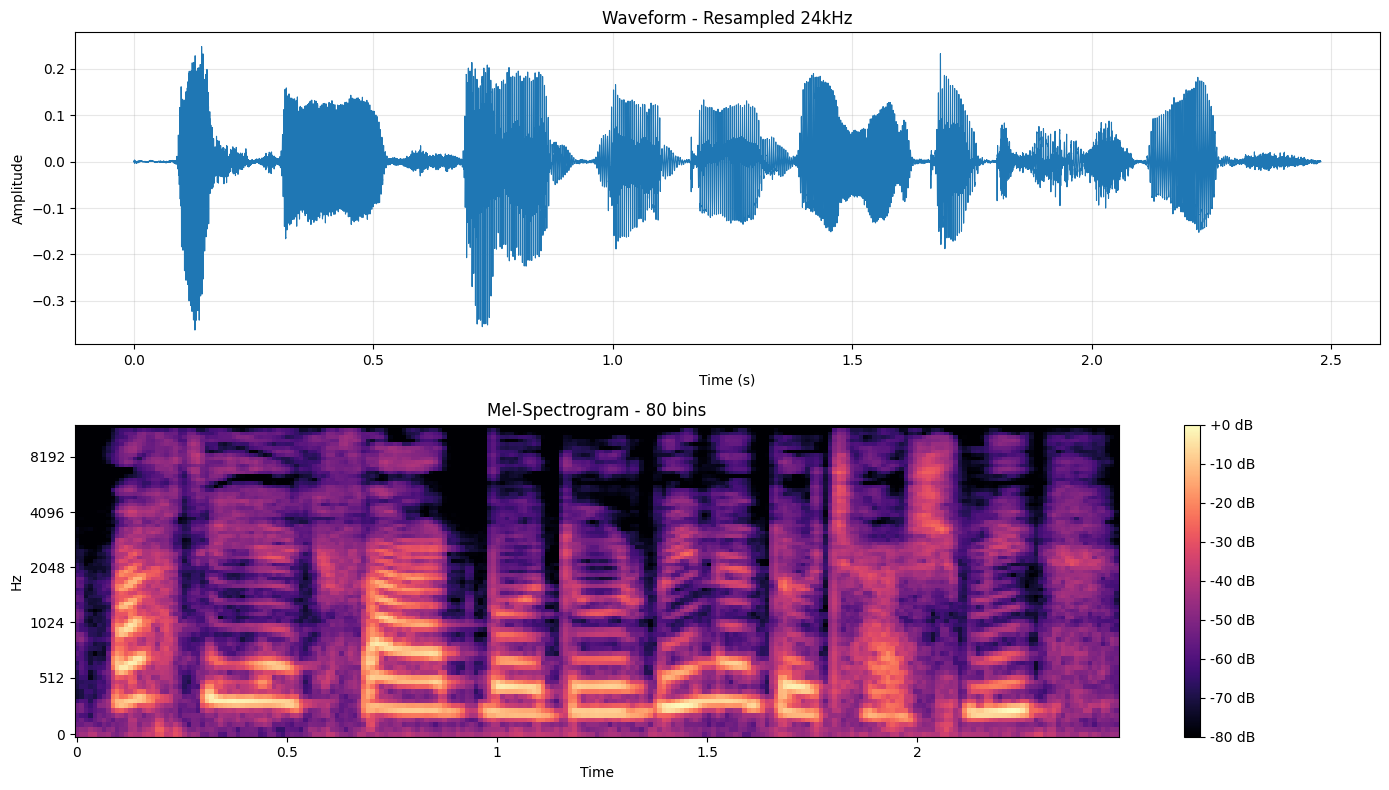

Figure saved to: /content/ManaTTS_Project/reports/figures/sample_000_waveform_mel.png

[12] Saving first part analysis summary
Summary saved to: /content/ManaTTS_Project/reports/dataset_part_001_analysis_summary.json
Summary also saved to: /content/drive/MyDrive/ManaTTS_Project/reports/dataset_part_001_analysis_summary.json
Figure also copied to: /content/drive/MyDrive/ManaTTS_Project/reports/sample_000_waveform_mel.png
Sample WAVs copied to: /content/drive/MyDrive/ManaTTS_Project/samples/dataset_part_001

Cell 4 finished successfully.


In [ ]:
# ============================================================
# Cell 4: Download and Inspect First ManaTTS Parquet Part
# ManaTTS Reimplementation Project
# ============================================================

import os
import json
import time
import shutil
import urllib.request
import urllib.error
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

from IPython.display import display, Audio

print("=" * 70)
print("Cell 4: Download and Inspect First ManaTTS Parquet Part")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
REPORTS_DIR = PROJECT_DIR / "reports"
DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"
SAMPLES_DIR = PROJECT_DIR / "samples" / "dataset_part_001"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

CONFIG_PATH = PROJECT_DIR / "project_config.json"
MANIFEST_CSV_PATH = REPORTS_DIR / "manatts_parquet_manifest.csv"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert MANIFEST_CSV_PATH.exists(), f"Manifest CSV not found: {MANIFEST_CSV_PATH}"

DATA_PARQUET_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

manifest_df = pd.read_csv(MANIFEST_CSV_PATH)

print("\n[1] Loaded project config and manifest")
print("Manifest rows:", len(manifest_df))

# ------------------------------------------------------------
# Select first file
# ------------------------------------------------------------
first_file = manifest_df.iloc[0].to_dict()

file_name = first_file["file_name"]
download_url = first_file["download_url"]
expected_size_bytes = int(first_file["size_bytes"])
expected_size_mb = expected_size_bytes / (1024 ** 2)

local_parquet_path = DATA_PARQUET_DIR / file_name
temp_download_path = DATA_PARQUET_DIR / f"{file_name}.part"

print("\n[2] Selected file")
print("File name:", file_name)
print("Expected size:", f"{expected_size_mb:.2f} MB")
print("Download URL:", download_url)
print("Local path:", local_parquet_path)

# ------------------------------------------------------------
# Disk space check before download
# ------------------------------------------------------------
print("\n[3] Disk space check")

total, used, free = shutil.disk_usage("/content")
free_mb = free / (1024 ** 2)

print(f"Free disk: {free_mb:.2f} MB")

if free < expected_size_bytes * 2:
    raise RuntimeError(
        "Not enough free disk space for safe download. "
        f"Need at least {expected_size_mb * 2:.2f} MB, available {free_mb:.2f} MB."
    )

print("Disk space check: OK")

# ------------------------------------------------------------
# Download helper
# ------------------------------------------------------------
def format_bytes(num_bytes):
    num_bytes = float(num_bytes)
    units = ["B", "KB", "MB", "GB"]
    idx = 0
    while num_bytes >= 1024 and idx < len(units) - 1:
        num_bytes /= 1024.0
        idx += 1
    return f"{num_bytes:.2f} {units[idx]}"

def download_file(url, output_path, expected_size=None, chunk_size=1024 * 1024):
    """
    Robust streaming download using urllib.
    Downloads to output_path.
    """
    output_path = Path(output_path)

    request = urllib.request.Request(
        url,
        headers={
            "User-Agent": "ManaTTS-Colab-Reimplementation/1.0"
        }
    )

    start_time = time.time()
    downloaded = 0
    last_print_time = start_time

    with urllib.request.urlopen(request, timeout=120) as response:
        status_code = getattr(response, "status", None)
        content_length = response.headers.get("Content-Length", None)

        print("HTTP status:", status_code)
        if content_length is not None:
            print("Server content length:", format_bytes(int(content_length)))
        else:
            print("Server content length: unknown")

        with open(output_path, "wb") as f:
            while True:
                chunk = response.read(chunk_size)
                if not chunk:
                    break

                f.write(chunk)
                downloaded += len(chunk)

                now = time.time()
                if now - last_print_time >= 5:
                    elapsed = now - start_time
                    speed = downloaded / max(elapsed, 1e-6)
                    if expected_size is not None:
                        percent = downloaded / expected_size * 100
                        print(
                            f"Downloaded {format_bytes(downloaded)} / "
                            f"{format_bytes(expected_size)} "
                            f"({percent:.1f}%) | "
                            f"Speed: {format_bytes(speed)}/s"
                        )
                    else:
                        print(
                            f"Downloaded {format_bytes(downloaded)} | "
                            f"Speed: {format_bytes(speed)}/s"
                        )
                    last_print_time = now

    elapsed = time.time() - start_time
    final_size = output_path.stat().st_size
    print(
        f"Download finished: {format_bytes(final_size)} "
        f"in {elapsed:.1f}s "
        f"({format_bytes(final_size / max(elapsed, 1e-6))}/s)"
    )

    return final_size

# ------------------------------------------------------------
# Download first parquet file if needed
# ------------------------------------------------------------
print("\n[4] Downloading file if needed")

download_needed = True

if local_parquet_path.exists():
    existing_size = local_parquet_path.stat().st_size
    print("Existing file found.")
    print("Existing size:", format_bytes(existing_size))

    size_diff = abs(existing_size - expected_size_bytes)

    if size_diff <= 1024:
        print("Existing file size matches expected size. Skipping download.")
        download_needed = False
    else:
        print("Existing file size does not match expected size. Re-downloading.")
        local_parquet_path.unlink()

if download_needed:
    if temp_download_path.exists():
        print("Removing previous temporary download file.")
        temp_download_path.unlink()

    try:
        final_size = download_file(
            url=download_url,
            output_path=temp_download_path,
            expected_size=expected_size_bytes,
        )

        size_diff = abs(final_size - expected_size_bytes)

        # HuggingFace sometimes reports exact LFS size. We allow tiny mismatch only.
        if size_diff > 1024:
            raise RuntimeError(
                f"Downloaded file size mismatch. "
                f"Expected {expected_size_bytes}, got {final_size}."
            )

        temp_download_path.rename(local_parquet_path)
        print("Downloaded file moved to:", local_parquet_path)

    except Exception as e:
        print("Download failed.")
        print("Error:", repr(e))
        if temp_download_path.exists():
            print("Temporary file remains at:", temp_download_path)
        raise

assert local_parquet_path.exists(), "Downloaded Parquet file not found."

actual_size = local_parquet_path.stat().st_size
print("Final local file size:", format_bytes(actual_size))

# ------------------------------------------------------------
# Inspect Parquet metadata using PyArrow
# ------------------------------------------------------------
print("\n[5] Inspecting Parquet metadata")

parquet_file = pq.ParquetFile(str(local_parquet_path))

print("Number of row groups:", parquet_file.num_row_groups)
print("Number of rows:", parquet_file.metadata.num_rows)
print("Number of columns:", parquet_file.metadata.num_columns)

print("\nParquet schema:")
print(parquet_file.schema)

# ------------------------------------------------------------
# Load dataset using Hugging Face datasets
# ------------------------------------------------------------
print("\n[6] Loading Parquet as Hugging Face Dataset")

try:
    from datasets import load_dataset

    ds = load_dataset(
        "parquet",
        data_files=str(local_parquet_path),
        split="train"
    )

    print("Dataset loaded successfully using datasets.load_dataset.")
    print(ds)
    print("Columns:", ds.column_names)
    print("Number of rows:", len(ds))

except Exception as e:
    print("Failed to load using datasets.load_dataset.")
    print("Error:", repr(e))
    print("Falling back to pandas read_parquet.")
    ds = None

# ------------------------------------------------------------
# Convert lightweight metadata to pandas for analysis
# ------------------------------------------------------------
print("\n[7] Loading lightweight metadata columns")

# We avoid loading the huge audio column into pandas unnecessarily.
metadata_columns = [
    "file name",
    "transcript",
    "duration",
    "match quality",
    "hypothesis",
    "CER",
    "search type",
    "ASRs",
    "samplerate",
]

available_columns = parquet_file.schema.names
metadata_columns = [c for c in metadata_columns if c in available_columns]

metadata_table = pq.read_table(
    str(local_parquet_path),
    columns=metadata_columns
)

metadata_df = metadata_table.to_pandas()

print("Metadata dataframe shape:", metadata_df.shape)
print("Metadata columns:", list(metadata_df.columns))

print("\nFirst 5 metadata rows:")
display(metadata_df.head(5))

# ------------------------------------------------------------
# Basic statistics for this part
# ------------------------------------------------------------
print("\n[8] Basic statistics for first Parquet part")

duration_sum = float(metadata_df["duration"].sum()) if "duration" in metadata_df.columns else None
duration_mean = float(metadata_df["duration"].mean()) if "duration" in metadata_df.columns else None
duration_min = float(metadata_df["duration"].min()) if "duration" in metadata_df.columns else None
duration_max = float(metadata_df["duration"].max()) if "duration" in metadata_df.columns else None

print("Rows:", len(metadata_df))

if duration_sum is not None:
    print(f"Total duration in this part: {duration_sum / 3600:.3f} hours")
    print(f"Mean duration: {duration_mean:.3f} sec")
    print(f"Min duration : {duration_min:.3f} sec")
    print(f"Max duration : {duration_max:.3f} sec")

if "match quality" in metadata_df.columns:
    print("\nMatch quality counts:")
    display(metadata_df["match quality"].value_counts(dropna=False).to_frame("count"))

if "samplerate" in metadata_df.columns:
    print("\nSample rate counts:")
    display(metadata_df["samplerate"].value_counts(dropna=False).to_frame("count"))

# ------------------------------------------------------------
# Extract one audio sample
# ------------------------------------------------------------
print("\n[9] Extracting one audio sample")

sample_index = 0

if ds is not None:
    sample = ds[int(sample_index)]
else:
    # Full pandas fallback, only if needed
    full_df = pd.read_parquet(str(local_parquet_path))
    sample = full_df.iloc[int(sample_index)].to_dict()

print("Sample index:", sample_index)

# Handle column names safely
transcript_key = "transcript"
audio_key = "audio"
sr_key = "samplerate" if "samplerate" in sample else "sample_rate"

assert transcript_key in sample, f"Missing transcript key: {transcript_key}"
assert audio_key in sample, f"Missing audio key: {audio_key}"
assert sr_key in sample, f"Missing sample rate key: {sr_key}"

transcript = sample[transcript_key]
sample_rate = int(sample[sr_key])

audio_value = sample[audio_key]

# The audio field can be a list, numpy array, or sometimes a dict depending on loader.
if isinstance(audio_value, dict):
    if "array" in audio_value:
        audio_array = np.asarray(audio_value["array"], dtype=np.float32)
    elif "bytes" in audio_value:
        raise RuntimeError("Audio is stored as bytes; this notebook expects array/list format.")
    else:
        raise RuntimeError(f"Unsupported audio dict keys: {audio_value.keys()}")
else:
    audio_array = np.asarray(audio_value, dtype=np.float32)

if audio_array.ndim > 1:
    audio_array = np.mean(audio_array, axis=-1).astype(np.float32)

assert audio_array.ndim == 1, "Audio array must be mono/1D."
assert sample_rate > 0, "Invalid sample rate."
assert len(audio_array) > 0, "Audio array is empty."

computed_duration = len(audio_array) / sample_rate

print("Transcript:", transcript)
print("Sample rate:", sample_rate)
print("Audio shape:", audio_array.shape)
print(f"Computed duration: {computed_duration:.3f} sec")

if "duration" in sample:
    print(f"Dataset duration: {float(sample['duration']):.3f} sec")

# Save extracted wav
sample_wav_path = SAMPLES_DIR / "sample_000_original_44100.wav"
sf.write(str(sample_wav_path), audio_array, sample_rate)

print("Extracted WAV saved to:", sample_wav_path)

# Display audio player
print("\nAudio preview:")
display(Audio(str(sample_wav_path)))

# ------------------------------------------------------------
# Resample to 24kHz and compute mel-spectrogram
# ------------------------------------------------------------
print("\n[10] Resampling to 24kHz and computing mel-spectrogram")

target_sr = 24000

audio_24k = librosa.resample(
    audio_array,
    orig_sr=sample_rate,
    target_sr=target_sr,
    res_type="soxr_hq"
).astype(np.float32)

sample_wav_24k_path = SAMPLES_DIR / "sample_000_resampled_24000.wav"
sf.write(str(sample_wav_24k_path), audio_24k, target_sr)

mel = librosa.feature.melspectrogram(
    y=audio_24k,
    sr=target_sr,
    n_fft=2048,
    hop_length=256,
    win_length=1024,
    n_mels=80,
    fmin=0,
    fmax=12000,
    power=1.0,
)

mel_db = librosa.amplitude_to_db(mel, ref=np.max)

print("Resampled audio shape:", audio_24k.shape)
print("Resampled WAV saved to:", sample_wav_24k_path)
print("Mel shape:", mel.shape)
print("Mel dB min/max:", float(mel_db.min()), float(mel_db.max()))

# ------------------------------------------------------------
# Plot waveform and mel
# ------------------------------------------------------------
print("\n[11] Saving waveform and mel plots")

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

time_axis = np.arange(len(audio_24k)) / target_sr
axes[0].plot(time_axis, audio_24k, linewidth=0.8)
axes[0].set_title("Waveform - Resampled 24kHz")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, alpha=0.3)

img = librosa.display.specshow(
    mel_db,
    sr=target_sr,
    hop_length=256,
    x_axis="time",
    y_axis="mel",
    ax=axes[1],
    cmap="magma"
)
axes[1].set_title("Mel-Spectrogram - 80 bins")
fig.colorbar(img, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()

figure_path = FIGURES_DIR / "sample_000_waveform_mel.png"
fig.savefig(str(figure_path), dpi=150, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)

# ------------------------------------------------------------
# Save first part analysis summary
# ------------------------------------------------------------
print("\n[12] Saving first part analysis summary")

summary = {
    "created_at": datetime.now().isoformat(),
    "file_name": file_name,
    "local_parquet_path": str(local_parquet_path),
    "file_size_bytes": int(actual_size),
    "num_rows": int(len(metadata_df)),
    "duration_total_hours": round(duration_sum / 3600, 6) if duration_sum is not None else None,
    "duration_mean_sec": round(duration_mean, 6) if duration_mean is not None else None,
    "duration_min_sec": round(duration_min, 6) if duration_min is not None else None,
    "duration_max_sec": round(duration_max, 6) if duration_max is not None else None,
    "sample_index": int(sample_index),
    "sample_transcript": transcript,
    "sample_rate_original": int(sample_rate),
    "sample_duration_computed_sec": round(computed_duration, 6),
    "sample_wav_original": str(sample_wav_path),
    "sample_wav_24k": str(sample_wav_24k_path),
    "sample_figure": str(figure_path),
}

if "match quality" in metadata_df.columns:
    summary["match_quality_counts"] = {
        str(k): int(v)
        for k, v in metadata_df["match quality"].value_counts(dropna=False).to_dict().items()
    }

summary_path = REPORTS_DIR / "dataset_part_001_analysis_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("Summary saved to:", summary_path)

# Copy useful outputs to Drive if available
drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports", None)
drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples", None)

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    drive_summary_path = drive_reports_dir / "dataset_part_001_analysis_summary.json"
    with open(drive_summary_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, ensure_ascii=False, indent=2)

    drive_figure_path = drive_reports_dir / "sample_000_waveform_mel.png"
    shutil.copy2(str(figure_path), str(drive_figure_path))

    print("Summary also saved to:", drive_summary_path)
    print("Figure also copied to:", drive_figure_path)

if drive_samples_dir is not None:
    drive_samples_dir = Path(drive_samples_dir) / "dataset_part_001"
    drive_samples_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(sample_wav_path), str(drive_samples_dir / sample_wav_path.name))
    shutil.copy2(str(sample_wav_24k_path), str(drive_samples_dir / sample_wav_24k_path.name))

    print("Sample WAVs copied to:", drive_samples_dir)

print("\n" + "=" * 70)
print("Cell 4 finished successfully.")
print("=" * 70)

Cell 5: Statistical Analysis of First ManaTTS Parquet Part

[1] Paths
Project directory: /content/ManaTTS_Project
Parquet file: /content/ManaTTS_Project/data/parquet/dataset_part_001.parquet
Reports directory: /content/ManaTTS_Project/reports
Figures directory: /content/ManaTTS_Project/reports/figures

[2] Loading metadata columns only
Loaded dataframe shape: (1102, 9)
Columns: ['file name', 'transcript', 'duration', 'match quality', 'hypothesis', 'CER', 'search type', 'ASRs', 'samplerate']

First 5 rows with derived columns:


,file_name,transcript,duration,match_quality,CER,samplerate,transcript_char_len,transcript_word_count,is_training_candidate
0,302-27.wav,وقتی یک فرد با دوربین دوچشمی,2.477982,HIGH,0.035714,44100.0,29,6,True
1,302-72.wav,علاوه‌بر این، تلسکوپ‌های بی‌وپتیک,2.413991,MIDDLE,0.062500,44100.0,34,4,True
2,125-41.wav,که به‌گفته وزیر تعاون، کار و رفاه اجتماعی، هر ...,7.840000,HIGH,0.012821,44100.0,83,14,True
3,131-1.wav,ابوذر سمیعی: دکتری سیاست‌گزاری فرهنگی,4.468980,MIDDLE,0.111111,44100.0,38,5,True
4,131-48.wav,به‌ویژه اگر چنین امری در کوتاه‌مدت محقق شود,4.103991,HIGH,0.000000,44100.0,44,8,True



[3] Summary statistics
Total rows: 1102
Rows with valid duration > 0: 1101
Training candidate rows: 1073
Total valid duration: 1.4681 hours
Training candidate duration: 1.4398 hours

Duration stats:


,duration_sec
count,1101.000000
mean,4.800324
std,2.208430
min,2.000000
25%,3.050998
50%,4.262993
75%,6.250000
max,11.946984



CER stats:


...


Sample rate counts:


,count
samplerate,
44100.0,1102



Training candidate by match quality:


,total_rows,training_candidates
match_quality,,
HIGH,634,634
MIDDLE,439,439
REJECT,29,0



[4] Saving metadata CSV files
Full metadata saved to: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_metadata_with_features.csv
Training candidates metadata saved to: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_training_candidates.csv
Training candidates shape: (1073, 19)

[5] Creating figures


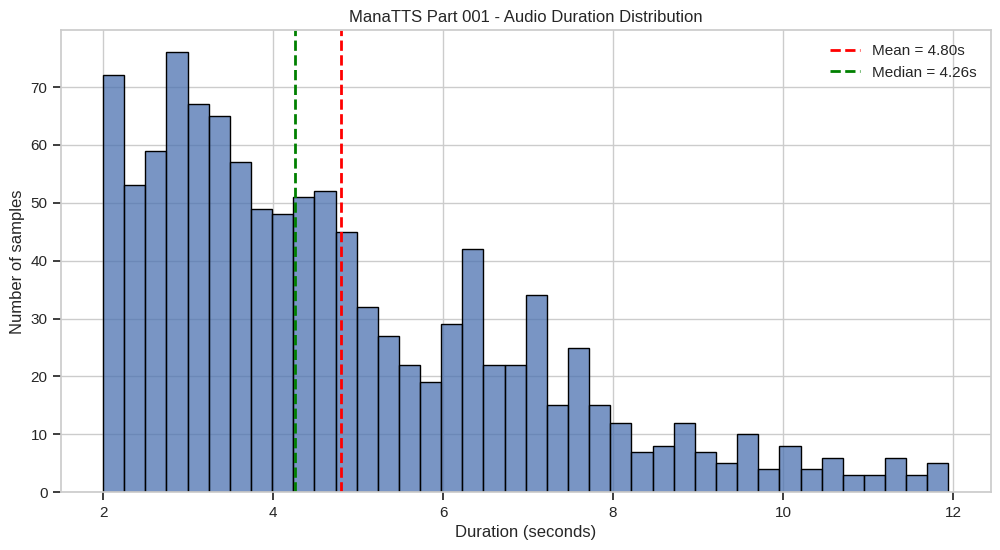

Saved: /content/ManaTTS_Project/reports/figures/part001_duration_distribution.png


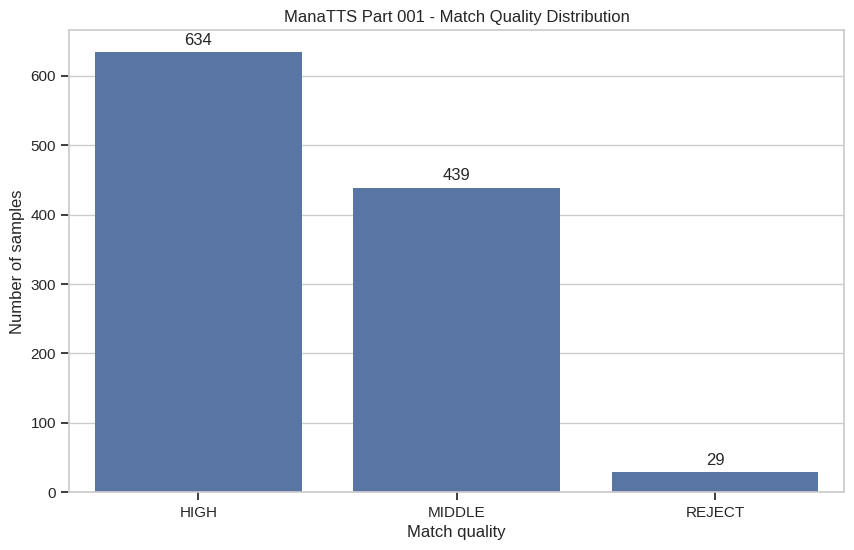

Saved: /content/ManaTTS_Project/reports/figures/part001_match_quality_distribution.png


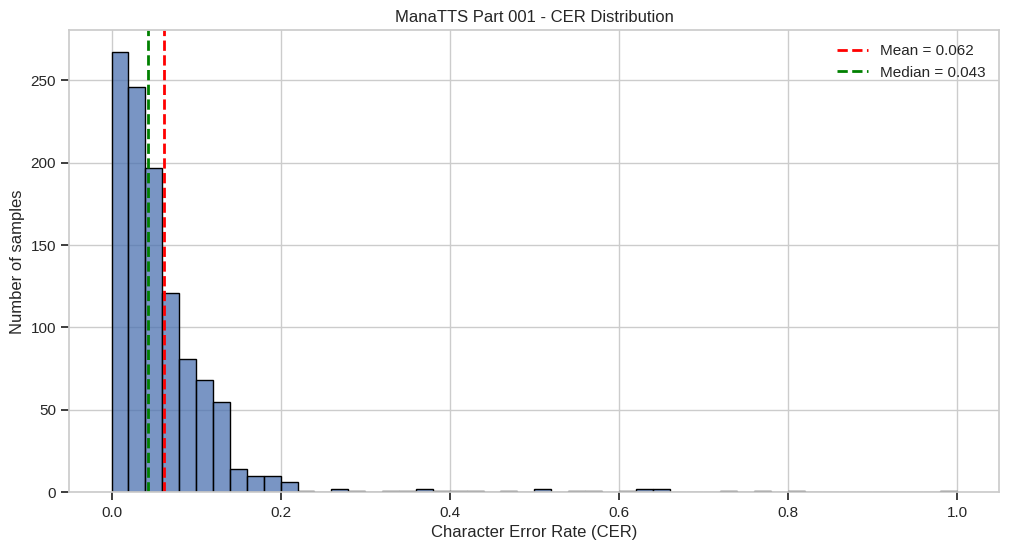

Saved: /content/ManaTTS_Project/reports/figures/part001_cer_distribution.png


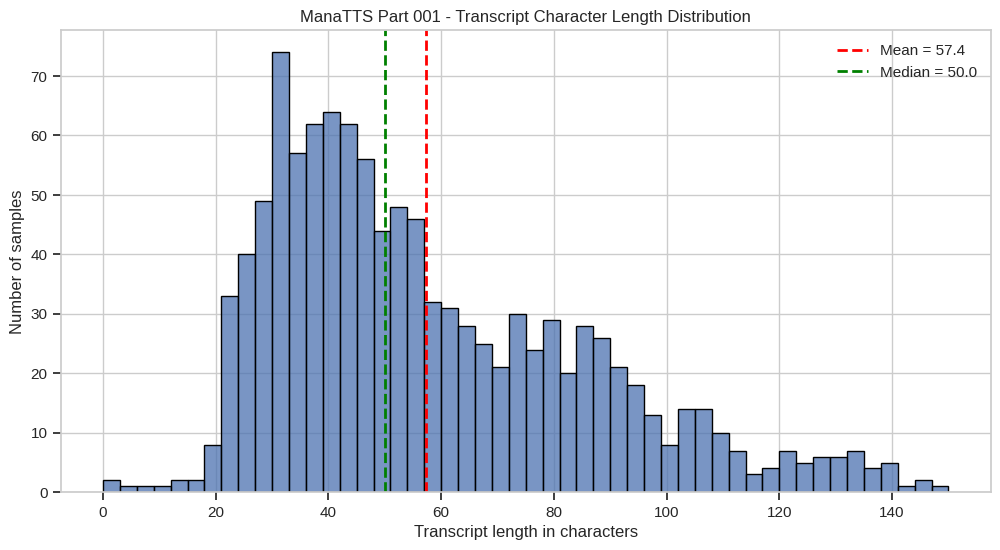

Saved: /content/ManaTTS_Project/reports/figures/part001_transcript_length_distribution.png


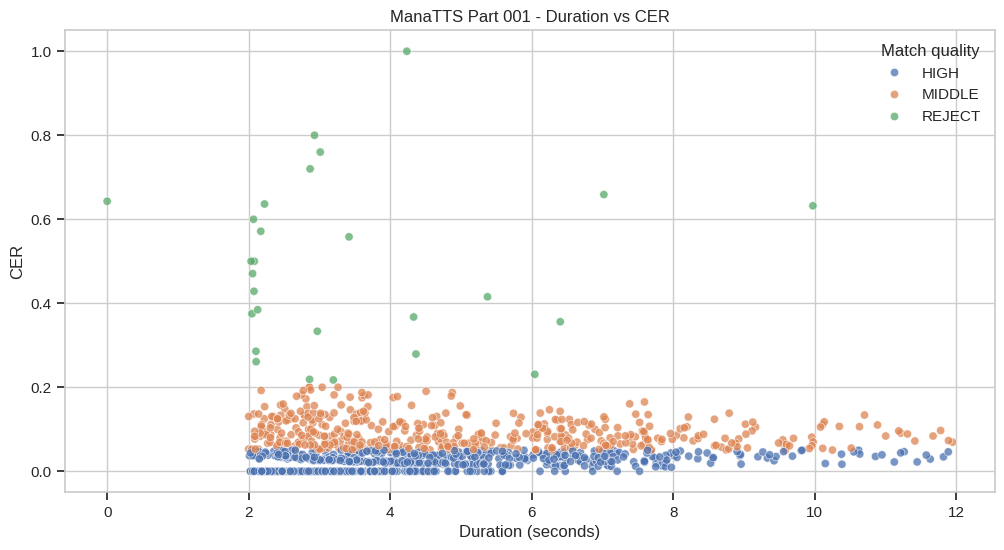

Saved: /content/ManaTTS_Project/reports/figures/part001_duration_vs_cer.png


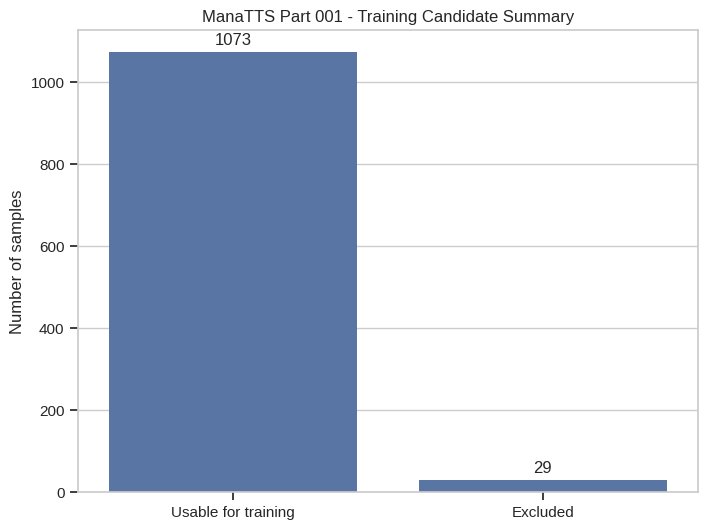

Saved: /content/ManaTTS_Project/reports/figures/part001_training_candidate_summary.png

[6] Saving analysis summary JSON
Analysis summary saved to: /content/ManaTTS_Project/reports/part001_statistical_analysis_summary.json

[7] Copying important outputs to Google Drive, if available
Summary and figures copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Metadata CSV backups copied to: /content/drive/MyDrive/ManaTTS_Project/backups

[8] Final summary
Rows in part001: 1102
Training candidates: 1073
Training candidate ratio: 97.37%
Total valid duration: 1.4681 hours
Training candidate duration: 1.4398 hours

Generated figures:
  duration_distribution: /content/ManaTTS_Project/reports/figures/part001_duration_distribution.png
  match_quality_distribution: /content/ManaTTS_Project/reports/figures/part001_match_quality_distribution.png
  cer_distribution: /content/ManaTTS_Project/reports/figures/part001_cer_distribution.png
  transcript_length_distribution: /content/ManaTTS_Project/rep

In [ ]:
# ============================================================
# Cell 5: Statistical Analysis of First ManaTTS Parquet Part
# ManaTTS Reimplementation Project
# ============================================================

import os
import json
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("=" * 70)
print("Cell 5: Statistical Analysis of First ManaTTS Parquet Part")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"

DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"
PROCESSED_METADATA_DIR = PROJECT_DIR / "data" / "processed" / "metadata"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

PARQUET_PATH = DATA_PARQUET_DIR / "dataset_part_001.parquet"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert PARQUET_PATH.exists(), f"Parquet file not found: {PARQUET_PATH}"

PROCESSED_METADATA_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

print("\n[1] Paths")
print("Project directory:", PROJECT_DIR)
print("Parquet file:", PARQUET_PATH)
print("Reports directory:", REPORTS_DIR)
print("Figures directory:", FIGURES_DIR)

# ------------------------------------------------------------
# Load metadata only
# ------------------------------------------------------------
print("\n[2] Loading metadata columns only")

metadata_columns = [
    "file name",
    "transcript",
    "duration",
    "match quality",
    "hypothesis",
    "CER",
    "search type",
    "ASRs",
    "samplerate",
]

parquet_file = pq.ParquetFile(str(PARQUET_PATH))
available_columns = parquet_file.schema.names

metadata_columns = [c for c in metadata_columns if c in available_columns]

metadata_table = pq.read_table(
    str(PARQUET_PATH),
    columns=metadata_columns
)

df = metadata_table.to_pandas()

print("Loaded dataframe shape:", df.shape)
print("Columns:", list(df.columns))

# Normalize column names for easier internal use
df = df.copy()
df["file_name"] = df["file name"].astype(str)
df["transcript"] = df["transcript"].fillna("").astype(str)
df["hypothesis"] = df["hypothesis"].fillna("").astype(str)
df["match_quality"] = df["match quality"].fillna("UNKNOWN").astype(str)

df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
df["CER"] = pd.to_numeric(df["CER"], errors="coerce")
df["samplerate"] = pd.to_numeric(df["samplerate"], errors="coerce")

# Derived text features
df["transcript_char_len"] = df["transcript"].str.len()
df["transcript_word_count"] = df["transcript"].str.split().apply(len)
df["hypothesis_char_len"] = df["hypothesis"].str.len()

# Basic validity flags
df["is_duration_valid"] = df["duration"].notna() & np.isfinite(df["duration"]) & (df["duration"] > 0)
df["is_audio_length_good_for_tts"] = df["duration"].between(1.0, 12.0, inclusive="both")
df["is_quality_usable"] = df["match_quality"].isin(["HIGH", "MIDDLE"])
df["is_not_reject"] = df["match_quality"] != "REJECT"
df["is_training_candidate"] = (
    df["is_duration_valid"]
    & df["is_audio_length_good_for_tts"]
    & df["is_quality_usable"]
    & (df["transcript_char_len"] > 0)
)

print("\nFirst 5 rows with derived columns:")
display(
    df[
        [
            "file_name",
            "transcript",
            "duration",
            "match_quality",
            "CER",
            "samplerate",
            "transcript_char_len",
            "transcript_word_count",
            "is_training_candidate",
        ]
    ].head(5)
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------
print("\n[3] Summary statistics")

num_rows = int(len(df))
num_valid_duration = int(df["is_duration_valid"].sum())
num_training_candidates = int(df["is_training_candidate"].sum())

total_duration_sec = float(df.loc[df["is_duration_valid"], "duration"].sum())
total_duration_hours = total_duration_sec / 3600

candidate_duration_sec = float(df.loc[df["is_training_candidate"], "duration"].sum())
candidate_duration_hours = candidate_duration_sec / 3600

duration_stats = df.loc[df["is_duration_valid"], "duration"].describe()
cer_stats = df["CER"].dropna().describe()
char_len_stats = df["transcript_char_len"].describe()
word_count_stats = df["transcript_word_count"].describe()

print(f"Total rows: {num_rows}")
print(f"Rows with valid duration > 0: {num_valid_duration}")
print(f"Training candidate rows: {num_training_candidates}")
print(f"Total valid duration: {total_duration_hours:.4f} hours")
print(f"Training candidate duration: {candidate_duration_hours:.4f} hours")

print("\nDuration stats:")
display(duration_stats.to_frame("duration_sec"))

print("\nCER stats:")
display(cer_stats.to_frame("CER"))

print("\nTranscript character length stats:")
display(char_len_stats.to_frame("transcript_char_len"))

print("\nTranscript word count stats:")
display(word_count_stats.to_frame("transcript_word_count"))

print("\nMatch quality counts:")
quality_counts = df["match_quality"].value_counts(dropna=False)
display(quality_counts.to_frame("count"))

print("\nSample rate counts:")
sample_rate_counts = df["samplerate"].value_counts(dropna=False).sort_index()
display(sample_rate_counts.to_frame("count"))

print("\nTraining candidate by match quality:")
candidate_by_quality = df.groupby("match_quality")["is_training_candidate"].agg(["count", "sum"])
candidate_by_quality = candidate_by_quality.rename(columns={"count": "total_rows", "sum": "training_candidates"})
display(candidate_by_quality)

# ------------------------------------------------------------
# Save metadata CSV files
# ------------------------------------------------------------
print("\n[4] Saving metadata CSV files")

full_metadata_csv = PROCESSED_METADATA_DIR / "dataset_part_001_metadata_with_features.csv"
training_candidates_csv = PROCESSED_METADATA_DIR / "dataset_part_001_training_candidates.csv"

df.to_csv(full_metadata_csv, index=False, encoding="utf-8")

training_df = df.loc[df["is_training_candidate"]].copy()
training_df.to_csv(training_candidates_csv, index=False, encoding="utf-8")

print("Full metadata saved to:", full_metadata_csv)
print("Training candidates metadata saved to:", training_candidates_csv)
print("Training candidates shape:", training_df.shape)

# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------
print("\n[5] Creating figures")

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

sns.set_context("notebook")
sns.set_palette("deep")

figure_paths = {}

# ------------------------------------------------------------
# Figure 1: Duration histogram
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

valid_duration = df.loc[df["is_duration_valid"], "duration"]

sns.histplot(
    valid_duration,
    bins=40,
    kde=False,
    ax=ax
)

ax.axvline(valid_duration.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {valid_duration.mean():.2f}s")
ax.axvline(valid_duration.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {valid_duration.median():.2f}s")

ax.set_title("ManaTTS Part 001 - Audio Duration Distribution")
ax.set_xlabel("Duration (seconds)")
ax.set_ylabel("Number of samples")
ax.legend()

duration_fig_path = FIGURES_DIR / "part001_duration_distribution.png"
fig.savefig(str(duration_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["duration_distribution"] = str(duration_fig_path)
print("Saved:", duration_fig_path)

# ------------------------------------------------------------
# Figure 2: Match quality distribution
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

quality_order = list(quality_counts.index)
sns.barplot(
    x=quality_counts.index,
    y=quality_counts.values,
    ax=ax,
    order=quality_order
)

ax.set_title("ManaTTS Part 001 - Match Quality Distribution")
ax.set_xlabel("Match quality")
ax.set_ylabel("Number of samples")

for i, value in enumerate(quality_counts.values):
    ax.text(i, value + max(quality_counts.values) * 0.01, str(value), ha="center", va="bottom")

quality_fig_path = FIGURES_DIR / "part001_match_quality_distribution.png"
fig.savefig(str(quality_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["match_quality_distribution"] = str(quality_fig_path)
print("Saved:", quality_fig_path)

# ------------------------------------------------------------
# Figure 3: CER histogram
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

cer_values = df["CER"].dropna()
cer_values = cer_values[np.isfinite(cer_values)]

sns.histplot(
    cer_values,
    bins=50,
    kde=False,
    ax=ax
)

ax.axvline(cer_values.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {cer_values.mean():.3f}")
ax.axvline(cer_values.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {cer_values.median():.3f}")

ax.set_title("ManaTTS Part 001 - CER Distribution")
ax.set_xlabel("Character Error Rate (CER)")
ax.set_ylabel("Number of samples")
ax.legend()

cer_fig_path = FIGURES_DIR / "part001_cer_distribution.png"
fig.savefig(str(cer_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["cer_distribution"] = str(cer_fig_path)
print("Saved:", cer_fig_path)

# ------------------------------------------------------------
# Figure 4: Transcript length distribution
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

char_len_values = df["transcript_char_len"].dropna()
char_len_values = char_len_values[np.isfinite(char_len_values)]

sns.histplot(
    char_len_values,
    bins=50,
    kde=False,
    ax=ax
)

ax.axvline(char_len_values.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {char_len_values.mean():.1f}")
ax.axvline(char_len_values.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {char_len_values.median():.1f}")

ax.set_title("ManaTTS Part 001 - Transcript Character Length Distribution")
ax.set_xlabel("Transcript length in characters")
ax.set_ylabel("Number of samples")
ax.legend()

text_len_fig_path = FIGURES_DIR / "part001_transcript_length_distribution.png"
fig.savefig(str(text_len_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["transcript_length_distribution"] = str(text_len_fig_path)
print("Saved:", text_len_fig_path)

# ------------------------------------------------------------
# Figure 5: Duration vs CER scatter
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 6))

scatter_df = df[
    df["duration"].notna()
    & df["CER"].notna()
    & np.isfinite(df["duration"])
    & np.isfinite(df["CER"])
].copy()

sns.scatterplot(
    data=scatter_df,
    x="duration",
    y="CER",
    hue="match_quality",
    alpha=0.75,
    ax=ax
)

ax.set_title("ManaTTS Part 001 - Duration vs CER")
ax.set_xlabel("Duration (seconds)")
ax.set_ylabel("CER")
ax.legend(title="Match quality")

duration_cer_fig_path = FIGURES_DIR / "part001_duration_vs_cer.png"
fig.savefig(str(duration_cer_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["duration_vs_cer"] = str(duration_cer_fig_path)
print("Saved:", duration_cer_fig_path)

# ------------------------------------------------------------
# Figure 6: Training candidate summary
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))

candidate_counts = pd.Series({
    "Usable for training": int(df["is_training_candidate"].sum()),
    "Excluded": int((~df["is_training_candidate"]).sum())
})

sns.barplot(
    x=candidate_counts.index,
    y=candidate_counts.values,
    ax=ax
)

ax.set_title("ManaTTS Part 001 - Training Candidate Summary")
ax.set_xlabel("")
ax.set_ylabel("Number of samples")

for i, value in enumerate(candidate_counts.values):
    ax.text(i, value + max(candidate_counts.values) * 0.01, str(value), ha="center", va="bottom")

candidate_fig_path = FIGURES_DIR / "part001_training_candidate_summary.png"
fig.savefig(str(candidate_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["training_candidate_summary"] = str(candidate_fig_path)
print("Saved:", candidate_fig_path)

# ------------------------------------------------------------
# Save analysis summary JSON
# ------------------------------------------------------------
print("\n[6] Saving analysis summary JSON")

summary = {
    "created_at": datetime.now().isoformat(),
    "source_parquet": str(PARQUET_PATH),
    "num_rows": num_rows,
    "num_valid_duration": num_valid_duration,
    "num_training_candidates": num_training_candidates,
    "total_valid_duration_hours": round(total_duration_hours, 6),
    "training_candidate_duration_hours": round(candidate_duration_hours, 6),
    "duration_stats": {
        k: float(v) for k, v in duration_stats.to_dict().items()
    },
    "cer_stats": {
        k: float(v) for k, v in cer_stats.to_dict().items()
    },
    "transcript_char_len_stats": {
        k: float(v) for k, v in char_len_stats.to_dict().items()
    },
    "transcript_word_count_stats": {
        k: float(v) for k, v in word_count_stats.to_dict().items()
    },
    "match_quality_counts": {
        str(k): int(v) for k, v in quality_counts.to_dict().items()
    },
    "sample_rate_counts": {
        str(k): int(v) for k, v in sample_rate_counts.to_dict().items()
    },
    "filtering_rules": {
        "duration": "1.0 <= duration <= 12.0 seconds",
        "match_quality": "HIGH or MIDDLE",
        "transcript_char_len": "> 0",
        "reject_removed": True
    },
    "full_metadata_csv": str(full_metadata_csv),
    "training_candidates_csv": str(training_candidates_csv),
    "figures": figure_paths,
}

summary_json_path = REPORTS_DIR / "part001_statistical_analysis_summary.json"

with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("Analysis summary saved to:", summary_json_path)

# ------------------------------------------------------------
# Copy results to Google Drive if available
# ------------------------------------------------------------
print("\n[7] Copying important outputs to Google Drive, if available")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports", None)
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups", None)

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    # Copy summary JSON
    shutil.copy2(str(summary_json_path), str(drive_reports_dir / summary_json_path.name))

    # Copy figures
    drive_figures_dir = drive_reports_dir / "figures_part001"
    drive_figures_dir.mkdir(parents=True, exist_ok=True)

    for _, fig_path in figure_paths.items():
        fig_path = Path(fig_path)
        if fig_path.exists():
            shutil.copy2(str(fig_path), str(drive_figures_dir / fig_path.name))

    print("Summary and figures copied to:", drive_reports_dir)

else:
    print("Drive reports directory not configured. Skipping Drive copy for reports.")

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)

    # Metadata CSVs are not huge for part001, so backup them too
    shutil.copy2(str(full_metadata_csv), str(drive_backups_dir / full_metadata_csv.name))
    shutil.copy2(str(training_candidates_csv), str(drive_backups_dir / training_candidates_csv.name))

    print("Metadata CSV backups copied to:", drive_backups_dir)

else:
    print("Drive backups directory not configured. Skipping metadata backup.")

# ------------------------------------------------------------
# Final report
# ------------------------------------------------------------
print("\n[8] Final summary")

print(f"Rows in part001: {num_rows}")
print(f"Training candidates: {num_training_candidates}")
print(f"Training candidate ratio: {num_training_candidates / max(num_rows, 1) * 100:.2f}%")
print(f"Total valid duration: {total_duration_hours:.4f} hours")
print(f"Training candidate duration: {candidate_duration_hours:.4f} hours")

print("\nGenerated figures:")
for name, path in figure_paths.items():
    print(f"  {name}: {path}")

print("\n" + "=" * 70)
print("Cell 5 finished successfully.")
print("=" * 70)

Cell 5B: Clean CER Statistics and Refine Training Metadata

[1] Paths OK
Parquet: /content/ManaTTS_Project/data/parquet/dataset_part_001.parquet

[2] Loading metadata columns
Loaded shape: (1102, 9)

[3] Cleaning columns
Cleaning done.

[4] Key counts
Total rows: 1102
CER raw inf count: 2
CER clean NaN count: 2
Training candidates HIGH+MIDDLE: 1073
Strict candidates HIGH only: 634
CER-aware candidates: 1073
Valid duration: 1.4681 hours
Training duration HIGH+MIDDLE: 1.4398 hours
Strict duration HIGH only: 0.8087 hours
CER-aware duration: 1.4398 hours

Match quality counts:


,count
match_quality,
HIGH,634
MIDDLE,439
REJECT,29



Candidate summary by quality:


,total_rows,training_candidates,strict_candidates,cer_aware_candidates,duration_hours
match_quality,,,,,
HIGH,634,634,634,634,0.808747
MIDDLE,439,439,0,439,0.631027
REJECT,29,0,0,0,0.028325



Clean CER statistics:


,CER_clean
count,1100.000000
mean,0.061699
std,0.085965
min,0.000000
25%,0.020727
50%,0.043478
75%,0.078947
max,1.000000



[5] Saving refined metadata files
Full clean metadata: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_metadata_clean.csv
Training candidates: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_training_candidates_clean.csv
Strict candidates: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_strict_training_candidates_clean.csv
CER-aware candidates: /content/ManaTTS_Project/data/processed/metadata/dataset_part_001_cer_aware_candidates_clean.csv

[6] Plotting clean CER distribution


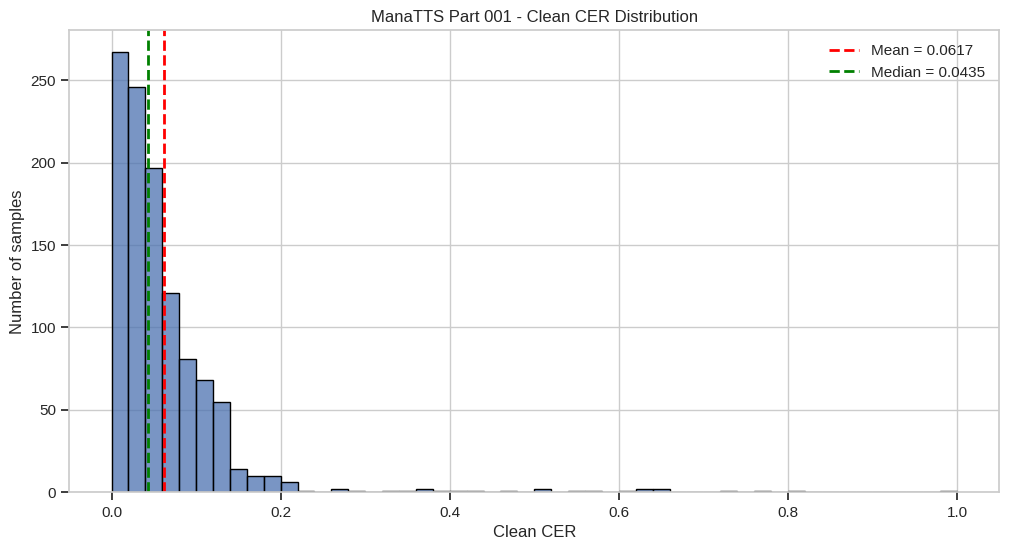

Saved figure: /content/ManaTTS_Project/reports/figures/part001_clean_cer_distribution.png

[7] Plotting candidate duration comparison


,subset,duration_hours,num_samples
0,All valid,1.468099,1101
1,HIGH+MIDDLE,1.439774,1073
2,HIGH only,0.808747,634
3,CER-aware,1.439774,1073


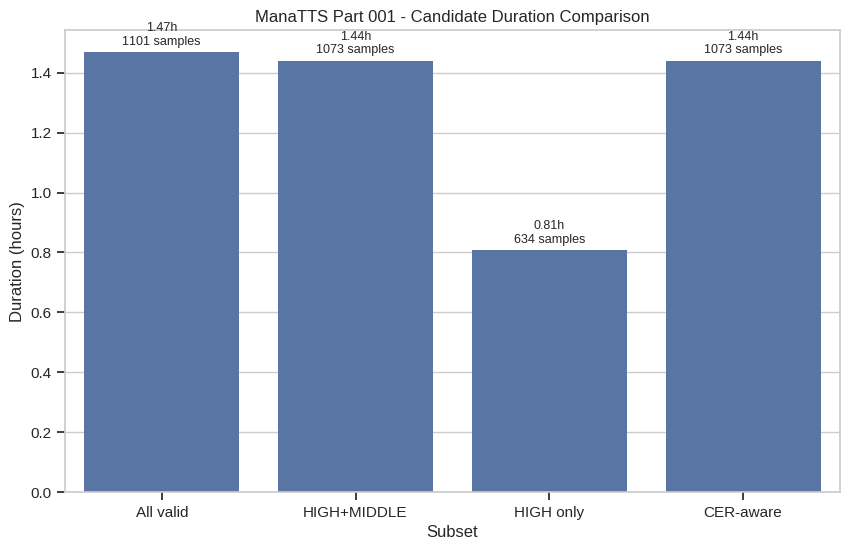

Saved figure: /content/ManaTTS_Project/reports/figures/part001_candidate_duration_comparison.png

[8] Saving clean summary JSON
Clean summary saved: /content/ManaTTS_Project/reports/part001_clean_analysis_summary.json

[9] Copying clean analysis outputs to Google Drive
Reports copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Metadata backups copied to: /content/drive/MyDrive/ManaTTS_Project/backups

Cell 5B finished successfully.


In [ ]:
# ============================================================
# Cell 5B: Clean CER Statistics and Refine Training Metadata
# ManaTTS Reimplementation Project
# ============================================================

import json
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("=" * 70)
print("Cell 5B: Clean CER Statistics and Refine Training Metadata")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PARQUET_PATH = PROJECT_DIR / "data" / "parquet" / "dataset_part_001.parquet"

REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
METADATA_DIR = PROJECT_DIR / "data" / "processed" / "metadata"

assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert PARQUET_PATH.exists(), f"Parquet file not found: {PARQUET_PATH}"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

print("\n[1] Paths OK")
print("Parquet:", PARQUET_PATH)

# ------------------------------------------------------------
# Load metadata columns only
# ------------------------------------------------------------
print("\n[2] Loading metadata columns")

metadata_columns = [
    "file name",
    "transcript",
    "duration",
    "match quality",
    "hypothesis",
    "CER",
    "search type",
    "ASRs",
    "samplerate",
]

table = pq.read_table(str(PARQUET_PATH), columns=metadata_columns)
df = table.to_pandas()

print("Loaded shape:", df.shape)

# ------------------------------------------------------------
# Normalize and clean
# ------------------------------------------------------------
print("\n[3] Cleaning columns")

df = df.copy()

df["file_name"] = df["file name"].fillna("").astype(str)
df["transcript"] = df["transcript"].fillna("").astype(str).str.strip()
df["hypothesis"] = df["hypothesis"].fillna("").astype(str).str.strip()
df["match_quality"] = df["match quality"].fillna("UNKNOWN").astype(str).str.strip()

df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
df["CER_raw"] = pd.to_numeric(df["CER"], errors="coerce")
df["samplerate"] = pd.to_numeric(df["samplerate"], errors="coerce")

# Replace +inf/-inf with NaN for clean statistics
df["CER_clean"] = df["CER_raw"].replace([np.inf, -np.inf], np.nan)

df["transcript_char_len"] = df["transcript"].str.len()
df["transcript_word_count"] = df["transcript"].apply(lambda x: len(x.split()) if isinstance(x, str) else 0)

# Flags
df["has_finite_duration"] = df["duration"].notna() & np.isfinite(df["duration"])
df["has_positive_duration"] = df["has_finite_duration"] & (df["duration"] > 0)
df["duration_in_tts_range"] = df["duration"].between(1.0, 12.0, inclusive="both")
df["has_text"] = df["transcript_char_len"] > 0
df["is_high"] = df["match_quality"] == "HIGH"
df["is_middle"] = df["match_quality"] == "MIDDLE"
df["is_reject"] = df["match_quality"] == "REJECT"
df["is_high_or_middle"] = df["match_quality"].isin(["HIGH", "MIDDLE"])
df["has_valid_samplerate"] = df["samplerate"] == 44100

# Main candidate: similar to our previous rule
df["training_candidate"] = (
    df["has_positive_duration"]
    & df["duration_in_tts_range"]
    & df["has_text"]
    & df["is_high_or_middle"]
    & df["has_valid_samplerate"]
)

# Strict candidate: safer subset for first training/debug
df["strict_training_candidate"] = (
    df["has_positive_duration"]
    & df["duration_in_tts_range"]
    & df["has_text"]
    & df["is_high"]
    & df["has_valid_samplerate"]
)

# Optional CER-aware candidate: avoid suspicious alignments
# We do NOT force this for final training yet; it is just for analysis.
df["cer_aware_candidate"] = (
    df["training_candidate"]
    & df["CER_clean"].notna()
    & (df["CER_clean"] <= 0.20)
)

print("Cleaning done.")

# ------------------------------------------------------------
# Key counts
# ------------------------------------------------------------
print("\n[4] Key counts")

num_rows = len(df)
num_inf_cer = int(np.isinf(df["CER_raw"].to_numpy(dtype=float)).sum())
num_nan_cer_clean = int(df["CER_clean"].isna().sum())
num_training = int(df["training_candidate"].sum())
num_strict = int(df["strict_training_candidate"].sum())
num_cer_aware = int(df["cer_aware_candidate"].sum())

valid_duration_hours = float(df.loc[df["has_positive_duration"], "duration"].sum()) / 3600
training_duration_hours = float(df.loc[df["training_candidate"], "duration"].sum()) / 3600
strict_duration_hours = float(df.loc[df["strict_training_candidate"], "duration"].sum()) / 3600
cer_aware_duration_hours = float(df.loc[df["cer_aware_candidate"], "duration"].sum()) / 3600

print("Total rows:", num_rows)
print("CER raw inf count:", num_inf_cer)
print("CER clean NaN count:", num_nan_cer_clean)
print("Training candidates HIGH+MIDDLE:", num_training)
print("Strict candidates HIGH only:", num_strict)
print("CER-aware candidates:", num_cer_aware)

print(f"Valid duration: {valid_duration_hours:.4f} hours")
print(f"Training duration HIGH+MIDDLE: {training_duration_hours:.4f} hours")
print(f"Strict duration HIGH only: {strict_duration_hours:.4f} hours")
print(f"CER-aware duration: {cer_aware_duration_hours:.4f} hours")

print("\nMatch quality counts:")
display(df["match_quality"].value_counts(dropna=False).to_frame("count"))

print("\nCandidate summary by quality:")
candidate_summary = df.groupby("match_quality").agg(
    total_rows=("file_name", "count"),
    training_candidates=("training_candidate", "sum"),
    strict_candidates=("strict_training_candidate", "sum"),
    cer_aware_candidates=("cer_aware_candidate", "sum"),
    duration_hours=("duration", lambda x: float(pd.to_numeric(x, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna().sum()) / 3600),
)
display(candidate_summary)

print("\nClean CER statistics:")
clean_cer_stats = df["CER_clean"].dropna().describe()
display(clean_cer_stats.to_frame("CER_clean"))

# ------------------------------------------------------------
# Save refined metadata files
# ------------------------------------------------------------
print("\n[5] Saving refined metadata files")

full_clean_csv = METADATA_DIR / "dataset_part_001_metadata_clean.csv"
training_csv = METADATA_DIR / "dataset_part_001_training_candidates_clean.csv"
strict_csv = METADATA_DIR / "dataset_part_001_strict_training_candidates_clean.csv"
cer_aware_csv = METADATA_DIR / "dataset_part_001_cer_aware_candidates_clean.csv"

df.to_csv(full_clean_csv, index=False, encoding="utf-8")
df.loc[df["training_candidate"]].to_csv(training_csv, index=False, encoding="utf-8")
df.loc[df["strict_training_candidate"]].to_csv(strict_csv, index=False, encoding="utf-8")
df.loc[df["cer_aware_candidate"]].to_csv(cer_aware_csv, index=False, encoding="utf-8")

print("Full clean metadata:", full_clean_csv)
print("Training candidates:", training_csv)
print("Strict candidates:", strict_csv)
print("CER-aware candidates:", cer_aware_csv)

# ------------------------------------------------------------
# Clean CER plot
# ------------------------------------------------------------
print("\n[6] Plotting clean CER distribution")

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

sns.set_context("notebook")

clean_cer = df["CER_clean"].dropna()
clean_cer = clean_cer[np.isfinite(clean_cer)]

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(clean_cer, bins=50, kde=False, ax=ax)

ax.axvline(clean_cer.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {clean_cer.mean():.4f}")
ax.axvline(clean_cer.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {clean_cer.median():.4f}")

ax.set_title("ManaTTS Part 001 - Clean CER Distribution")
ax.set_xlabel("Clean CER")
ax.set_ylabel("Number of samples")
ax.legend()

clean_cer_fig = FIGURES_DIR / "part001_clean_cer_distribution.png"
fig.savefig(str(clean_cer_fig), dpi=150, bbox_inches="tight")
plt.show()

print("Saved figure:", clean_cer_fig)

# ------------------------------------------------------------
# Candidate duration comparison plot
# ------------------------------------------------------------
print("\n[7] Plotting candidate duration comparison")

duration_summary = pd.DataFrame({
    "subset": [
        "All valid",
        "HIGH+MIDDLE",
        "HIGH only",
        "CER-aware"
    ],
    "duration_hours": [
        valid_duration_hours,
        training_duration_hours,
        strict_duration_hours,
        cer_aware_duration_hours
    ],
    "num_samples": [
        int(df["has_positive_duration"].sum()),
        num_training,
        num_strict,
        num_cer_aware
    ]
})

display(duration_summary)

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=duration_summary,
    x="subset",
    y="duration_hours",
    ax=ax
)

ax.set_title("ManaTTS Part 001 - Candidate Duration Comparison")
ax.set_xlabel("Subset")
ax.set_ylabel("Duration (hours)")

for i, row in duration_summary.iterrows():
    ax.text(
        i,
        row["duration_hours"] + max(duration_summary["duration_hours"]) * 0.01,
        f'{row["duration_hours"]:.2f}h\n{int(row["num_samples"])} samples',
        ha="center",
        va="bottom",
        fontsize=9
    )

candidate_duration_fig = FIGURES_DIR / "part001_candidate_duration_comparison.png"
fig.savefig(str(candidate_duration_fig), dpi=150, bbox_inches="tight")
plt.show()

print("Saved figure:", candidate_duration_fig)

# ------------------------------------------------------------
# Save clean summary JSON
# ------------------------------------------------------------
print("\n[8] Saving clean summary JSON")

summary = {
    "created_at": datetime.now().isoformat(),
    "source_parquet": str(PARQUET_PATH),
    "num_rows": int(num_rows),
    "cer_raw_inf_count": int(num_inf_cer),
    "cer_clean_nan_count": int(num_nan_cer_clean),
    "match_quality_counts": {
        str(k): int(v)
        for k, v in df["match_quality"].value_counts(dropna=False).to_dict().items()
    },
    "valid_duration_hours": round(valid_duration_hours, 6),
    "training_candidates_high_middle": {
        "num_samples": int(num_training),
        "duration_hours": round(training_duration_hours, 6),
        "rule": "duration 1-12s, non-empty text, sample rate 44100, match_quality in HIGH/MIDDLE"
    },
    "strict_candidates_high_only": {
        "num_samples": int(num_strict),
        "duration_hours": round(strict_duration_hours, 6),
        "rule": "duration 1-12s, non-empty text, sample rate 44100, match_quality == HIGH"
    },
    "cer_aware_candidates": {
        "num_samples": int(num_cer_aware),
        "duration_hours": round(cer_aware_duration_hours, 6),
        "rule": "training_candidate and finite CER <= 0.20"
    },
    "clean_cer_stats": {
        str(k): float(v)
        for k, v in clean_cer_stats.to_dict().items()
    },
    "metadata_files": {
        "full_clean_csv": str(full_clean_csv),
        "training_csv": str(training_csv),
        "strict_csv": str(strict_csv),
        "cer_aware_csv": str(cer_aware_csv),
    },
    "figures": {
        "clean_cer_distribution": str(clean_cer_fig),
        "candidate_duration_comparison": str(candidate_duration_fig),
    }
}

summary_path = REPORTS_DIR / "part001_clean_analysis_summary.json"

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, allow_nan=False)

print("Clean summary saved:", summary_path)

# ------------------------------------------------------------
# Copy to Google Drive
# ------------------------------------------------------------
print("\n[9] Copying clean analysis outputs to Google Drive")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(summary_path), str(drive_reports_dir / summary_path.name))
    shutil.copy2(str(clean_cer_fig), str(drive_reports_dir / clean_cer_fig.name))
    shutil.copy2(str(candidate_duration_fig), str(drive_reports_dir / candidate_duration_fig.name))

    print("Reports copied to:", drive_reports_dir)

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(full_clean_csv), str(drive_backups_dir / full_clean_csv.name))
    shutil.copy2(str(training_csv), str(drive_backups_dir / training_csv.name))
    shutil.copy2(str(strict_csv), str(drive_backups_dir / strict_csv.name))
    shutil.copy2(str(cer_aware_csv), str(drive_backups_dir / cer_aware_csv.name))

    print("Metadata backups copied to:", drive_backups_dir)

print("\n" + "=" * 70)
print("Cell 5B finished successfully.")
print("=" * 70)

In [ ]:
# ============================================================
# Cell 6_PRECHECK: Disk and Download Status Check
# ManaTTS Project
# ============================================================

import os
import json
import shutil
from pathlib import Path

import pandas as pd

print("=" * 70)
print("Cell 6_PRECHECK: Disk and Download Status Check")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
MANIFEST_CSV_PATH = PROJECT_DIR / "reports" / "manatts_parquet_manifest.csv"
DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert MANIFEST_CSV_PATH.exists(), f"Manifest CSV not found: {MANIFEST_CSV_PATH}"

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

manifest_df = pd.read_csv(MANIFEST_CSV_PATH)

print("\n[1] Basic paths")
print("Project directory:", PROJECT_DIR)
print("Parquet directory:", DATA_PARQUET_DIR)
print("Manifest:", MANIFEST_CSV_PATH)

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def human_size(num_bytes):
    num_bytes = float(num_bytes)
    units = ["B", "KB", "MB", "GB", "TB"]
    idx = 0

    while num_bytes >= 1024 and idx < len(units) - 1:
        num_bytes /= 1024.0
        idx += 1

    return f"{num_bytes:.2f} {units[idx]}"

def get_dir_size(path: Path):
    total = 0

    if not path.exists():
        return 0

    if path.is_file():
        return path.stat().st_size

    for root, dirs, files in os.walk(path):
        for file in files:
            fp = Path(root) / file
            try:
                total += fp.stat().st_size
            except Exception:
                pass

    return total

def disk_report(path):
    path = Path(path)

    if not path.exists():
        return None

    total, used, free = shutil.disk_usage(str(path))

    return {
        "path": str(path),
        "total": total,
        "used": used,
        "free": free,
        "total_h": human_size(total),
        "used_h": human_size(used),
        "free_h": human_size(free),
        "free_gb": free / (1024 ** 3),
    }

# ------------------------------------------------------------
# Disk reports
# ------------------------------------------------------------
print("\n[2] Disk space reports")

content_report = disk_report("/content")

print("/content")
print("  Total:", content_report["total_h"])
print("  Used :", content_report["used_h"])
print("  Free :", content_report["free_h"])

drive_path = Path("/content/drive/MyDrive")

if drive_path.exists():
    drive_report = disk_report(drive_path)
    print("\nGoogle Drive MyDrive")
    print("  Total:", drive_report["total_h"])
    print("  Used :", drive_report["used_h"])
    print("  Free :", drive_report["free_h"])
else:
    drive_report = None
    print("\nGoogle Drive MyDrive not mounted or not found.")

# ------------------------------------------------------------
# Project size
# ------------------------------------------------------------
print("\n[3] Project directory size")

project_size = get_dir_size(PROJECT_DIR)
print("Project total size:", human_size(project_size))

for sub in ["data", "reports", "samples", "src", "configs", "runs"]:
    sub_path = PROJECT_DIR / sub
    if sub_path.exists():
        print(f"  {sub:10s}: {human_size(get_dir_size(sub_path))}")

# ------------------------------------------------------------
# Check first 5 parquet files
# ------------------------------------------------------------
print("\n[4] Checking first 5 Parquet files")

TARGET_NUM_PARTS = 5
target_df = manifest_df.iloc[:TARGET_NUM_PARTS].copy()

rows = []

DATA_PARQUET_DIR.mkdir(parents=True, exist_ok=True)

for _, row in target_df.iterrows():
    file_name = str(row["file_name"])
    expected_size = int(row["size_bytes"])
    expected_size_mb = expected_size / (1024 ** 2)

    final_path = DATA_PARQUET_DIR / file_name
    part_path = final_path.with_suffix(final_path.suffix + ".part")

    exists = final_path.exists()
    actual_size = final_path.stat().st_size if exists else 0
    actual_size_mb = actual_size / (1024 ** 2)

    size_ok = exists and abs(actual_size - expected_size) <= 1024

    part_exists = part_path.exists()
    part_size = part_path.stat().st_size if part_exists else 0

    rows.append({
        "file_name": file_name,
        "expected_mb": round(expected_size_mb, 3),
        "exists": bool(exists),
        "actual_mb": round(actual_size_mb, 3) if exists else None,
        "size_ok": bool(size_ok),
        "partial_exists": bool(part_exists),
        "partial_mb": round(part_size / (1024 ** 2), 3) if part_exists else None,
        "final_path": str(final_path),
    })

status_df = pd.DataFrame(rows)
display(status_df)

complete_count = int(status_df["size_ok"].sum())
partial_count = int(status_df["partial_exists"].sum())

print(f"Complete verified files among first 5: {complete_count}/{TARGET_NUM_PARTS}")
print(f"Partial .part files among first 5: {partial_count}")

# ------------------------------------------------------------
# Estimate required extra space
# ------------------------------------------------------------
print("\n[5] Required extra download size estimate")

remaining_bytes = 0

for _, row in status_df.iterrows():
    if not bool(row["size_ok"]):
        expected_mb = float(row["expected_mb"])
        remaining_bytes += int(expected_mb * 1024 ** 2)

remaining_gb = remaining_bytes / (1024 ** 3)

print("Estimated remaining download size:", human_size(remaining_bytes))

# Need remaining size + 5 GB safety buffer
required_free_gb = remaining_gb + 5.0
available_free_gb = content_report["free_gb"]

print(f"Required free space with buffer: {required_free_gb:.2f} GB")
print(f"Available free space: {available_free_gb:.2f} GB")

if available_free_gb >= required_free_gb:
    print("Disk status: OK for Cell 6 download.")
else:
    print("Disk status: NOT ENOUGH SPACE for safe download.")
    print("We should clean cache or reduce download target before running Cell 6.")

# ------------------------------------------------------------
# Check suspicious large folders in /content
# ------------------------------------------------------------
print("\n[6] Top-level /content usage")

content_items = []

for item in Path("/content").iterdir():
    try:
        size = get_dir_size(item)
        content_items.append((str(item), size))
    except Exception:
        pass

content_items = sorted(content_items, key=lambda x: x[1], reverse=True)

for path, size in content_items[:15]:
    print(f"{human_size(size):>10s}  {path}")

# ------------------------------------------------------------
# Final recommendation
# ------------------------------------------------------------
print("\n[7] Recommendation")

if complete_count == TARGET_NUM_PARTS:
    print("All first 5 Parquet files are already downloaded and verified.")
    print("You can skip Cell 6 and go directly to Cell 7.")
elif available_free_gb >= required_free_gb:
    print("Not all files are complete, but disk space is sufficient.")
    print("You can run Cell 6 safely.")
else:
    print("Disk space is not sufficient.")
    print("Send this output so we decide what to clean before continuing.")

print("\n" + "=" * 70)
print("Cell 6_PRECHECK finished successfully.")
print("=" * 70)

Cell 6_PRECHECK: Disk and Download Status Check

[1] Basic paths
Project directory: /content/ManaTTS_Project
Parquet directory: /content/ManaTTS_Project/data/parquet
Manifest: /content/ManaTTS_Project/reports/manatts_parquet_manifest.csv

[2] Disk space reports
/content
  Total: 235.68 GB
  Used : 49.46 GB
  Free : 186.20 GB

Google Drive MyDrive
  Total: 15.00 GB
  Used : 242.00 MB
  Free : 14.76 GB

[3] Project directory size
Project total size: 445.49 MB
  data      : 444.28 MB
  reports   : 820.58 KB
  samples   : 415.85 KB
  src       : 0.00 B
  configs   : 0.00 B
  runs      : 0.00 B

[4] Checking first 5 Parquet files


,file_name,expected_mb,exists,actual_mb,size_ok,partial_exists,partial_mb,final_path
0,dataset_part_001.parquet,442.148,True,442.148,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
1,dataset_part_002.parquet,439.138,False,NaN,False,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
2,dataset_part_003.parquet,440.011,False,NaN,False,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
3,dataset_part_004.parquet,438.260,False,NaN,False,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
4,dataset_part_005.parquet,434.351,False,NaN,False,False,None,/content/ManaTTS_Project/data/parquet/dataset_...


Complete verified files among first 5: 1/5
Partial .part files among first 5: 0

[5] Required extra download size estimate
Estimated remaining download size: 1.71 GB
Required free space with buffer: 6.71 GB
Available free space: 186.20 GB
Disk status: OK for Cell 6 download.

[6] Top-level /content usage
 445.49 MB  /content/ManaTTS_Project
 151.06 MB  /content/drive
  54.19 MB  /content/sample_data
  88.50 KB  /content/.config

[7] Recommendation
Not all files are complete, but disk space is sufficient.
You can run Cell 6 safely.

Cell 6_PRECHECK finished successfully.


In [ ]:
# ============================================================
# Cell 6_FULL: Download / Verify Full ManaTTS Dataset
# Research Path: ManaTTS + Lightweight Persian Piper TTS
# ============================================================

import json
import time
import shutil
import urllib.request
import urllib.error
from pathlib import Path
from datetime import datetime

import pandas as pd

from IPython.display import display

print("=" * 70)
print("Cell 6_FULL: Download / Verify Full ManaTTS Dataset")
print("=" * 70)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
TARGET_NUM_PARTS = "ALL"   # "ALL" means download all parts from manifest
CHUNK_SIZE = 1024 * 1024   # 1 MB
MAX_RETRIES_PER_FILE = 3
RETRY_SLEEP_SECONDS = 5

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
MANIFEST_CSV_PATH = PROJECT_DIR / "reports" / "manatts_parquet_manifest.csv"

DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"
REPORTS_DIR = PROJECT_DIR / "reports"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert MANIFEST_CSV_PATH.exists(), f"Manifest CSV not found: {MANIFEST_CSV_PATH}"

DATA_PARQUET_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

manifest_df = pd.read_csv(MANIFEST_CSV_PATH)

if TARGET_NUM_PARTS == "ALL":
    target_df = manifest_df.copy()
else:
    target_num = int(TARGET_NUM_PARTS)
    if target_num < 1:
        raise ValueError("TARGET_NUM_PARTS must be at least 1 or 'ALL'.")
    if target_num > len(manifest_df):
        raise ValueError(
            f"TARGET_NUM_PARTS={target_num} is greater than manifest size={len(manifest_df)}"
        )
    target_df = manifest_df.iloc[:target_num].copy()

target_df = target_df.reset_index(drop=True)

print("\n[1] Download plan")
print("Total files in manifest:", len(manifest_df))
print("Target files:", len(target_df))

display(target_df[["file_name", "size_mb"]].head(10))
print("...")
display(target_df[["file_name", "size_mb"]].tail(5))

total_target_size_bytes = int(target_df["size_bytes"].sum())
total_target_size_gb = total_target_size_bytes / (1024 ** 3)

print(f"Total target size: {total_target_size_gb:.3f} GB")

# ------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------
def format_bytes(num_bytes):
    num_bytes = float(num_bytes)
    units = ["B", "KB", "MB", "GB", "TB"]
    idx = 0

    while num_bytes >= 1024 and idx < len(units) - 1:
        num_bytes /= 1024.0
        idx += 1

    return f"{num_bytes:.2f} {units[idx]}"


def get_existing_download_status(df):
    rows = []

    for _, row in df.iterrows():
        file_name = str(row["file_name"])
        expected_size = int(row["size_bytes"])

        final_path = DATA_PARQUET_DIR / file_name
        part_path = final_path.with_suffix(final_path.suffix + ".part")

        exists = final_path.exists()
        actual_size = final_path.stat().st_size if exists else 0
        size_ok = exists and abs(actual_size - expected_size) <= 1024

        part_exists = part_path.exists()
        part_size = part_path.stat().st_size if part_exists else 0

        rows.append({
            "file_name": file_name,
            "expected_size_bytes": expected_size,
            "exists": bool(exists),
            "actual_size_bytes": int(actual_size),
            "size_ok": bool(size_ok),
            "partial_exists": bool(part_exists),
            "partial_size_bytes": int(part_size),
            "final_path": str(final_path),
            "partial_path": str(part_path),
        })

    return pd.DataFrame(rows)


# ------------------------------------------------------------
# Disk space check based on remaining files
# ------------------------------------------------------------
print("\n[2] Current download status and disk space check")

status_before_df = get_existing_download_status(target_df)

complete_count_before = int(status_before_df["size_ok"].sum())
remaining_df_for_size = status_before_df.loc[~status_before_df["size_ok"]].copy()

remaining_bytes = int(remaining_df_for_size["expected_size_bytes"].sum())
remaining_gb = remaining_bytes / (1024 ** 3)

print(f"Already complete files: {complete_count_before}/{len(target_df)}")
print("Remaining download size:", format_bytes(remaining_bytes))

total, used, free = shutil.disk_usage("/content")
free_gb = free / (1024 ** 3)

print(f"/content total: {total / (1024 ** 3):.2f} GB")
print(f"/content used : {used / (1024 ** 3):.2f} GB")
print(f"/content free : {free_gb:.2f} GB")

# Need remaining size + safety buffer.
# Safety buffer is larger for full dataset because temporary and cache files may appear.
required_gb = remaining_gb + 10.0

if free_gb < required_gb:
    raise RuntimeError(
        f"Not enough disk space for full download. "
        f"Need about {required_gb:.2f} GB, available {free_gb:.2f} GB."
    )

print("Disk space check: OK")

# ------------------------------------------------------------
# Download function with resume
# ------------------------------------------------------------
def download_file_once(url, final_path, expected_size=None, chunk_size=1024 * 1024):
    """
    Download a file once, with basic resume support.
    If final file exists and size is correct, skip.
    """
    final_path = Path(final_path)
    temp_path = final_path.with_suffix(final_path.suffix + ".part")

    # If final file already exists and is complete, skip.
    if final_path.exists():
        existing_size = final_path.stat().st_size

        if expected_size is not None and abs(existing_size - expected_size) <= 1024:
            return {
                "status": "skipped_existing_complete",
                "final_size": existing_size,
                "elapsed_sec": 0.0,
                "path": str(final_path),
            }

        print("Existing final file has wrong size. Removing:", final_path)
        final_path.unlink()

    # Resume from .part if available.
    resume_from = 0

    if temp_path.exists():
        resume_from = temp_path.stat().st_size

        if expected_size is not None and resume_from > expected_size:
            print("Partial file larger than expected. Removing partial file.")
            temp_path.unlink()
            resume_from = 0

    headers = {
        "User-Agent": "ManaTTS-Colab-FullDownload/1.0"
    }

    if resume_from > 0:
        headers["Range"] = f"bytes={resume_from}-"
        print(f"Found partial file {format_bytes(resume_from)}. Trying resume...")

    request = urllib.request.Request(url, headers=headers)

    start_time = time.time()
    downloaded_this_session = 0
    last_print_time = start_time

    response = urllib.request.urlopen(request, timeout=240)
    status_code = getattr(response, "status", None)

    # If server ignored Range request, restart from zero.
    if resume_from > 0 and status_code == 200:
        print("Server ignored resume request. Restarting from zero.")
        temp_path.unlink(missing_ok=True)
        resume_from = 0

    mode = "ab" if resume_from > 0 and status_code == 206 else "wb"

    content_length = response.headers.get("Content-Length", None)

    print("HTTP status:", status_code)
    if content_length is not None:
        print("Server response length:", format_bytes(int(content_length)))
    else:
        print("Server response length: unknown")

    with response:
        with open(temp_path, mode) as f:
            while True:
                chunk = response.read(chunk_size)

                if not chunk:
                    break

                f.write(chunk)
                downloaded_this_session += len(chunk)

                total_downloaded = resume_from + downloaded_this_session
                now = time.time()

                if now - last_print_time >= 15:
                    elapsed = now - start_time
                    speed = downloaded_this_session / max(elapsed, 1e-6)

                    if expected_size is not None:
                        percent = total_downloaded / expected_size * 100
                        print(
                            f"Progress: {format_bytes(total_downloaded)} / "
                            f"{format_bytes(expected_size)} "
                            f"({percent:.1f}%) | Speed: {format_bytes(speed)}/s"
                        )
                    else:
                        print(
                            f"Progress: {format_bytes(total_downloaded)} | "
                            f"Speed: {format_bytes(speed)}/s"
                        )

                    last_print_time = now

    elapsed_sec = time.time() - start_time
    final_temp_size = temp_path.stat().st_size

    if expected_size is not None:
        size_diff = abs(final_temp_size - expected_size)

        if size_diff > 1024:
            raise RuntimeError(
                f"Downloaded size mismatch for {final_path.name}. "
                f"Expected {expected_size}, got {final_temp_size}. "
                f"Temporary file kept at: {temp_path}"
            )

    temp_path.rename(final_path)

    return {
        "status": "downloaded",
        "final_size": final_temp_size,
        "elapsed_sec": elapsed_sec,
        "path": str(final_path),
    }


def download_file_with_retries(url, final_path, expected_size=None, chunk_size=1024 * 1024, max_retries=3):
    """
    Download with retries.
    """
    last_error = None

    for attempt in range(1, max_retries + 1):
        try:
            print(f"Attempt {attempt}/{max_retries}")
            return download_file_once(
                url=url,
                final_path=final_path,
                expected_size=expected_size,
                chunk_size=chunk_size,
            )
        except Exception as e:
            last_error = e
            print(f"Attempt {attempt} failed: {repr(e)}")

            if attempt < max_retries:
                print(f"Sleeping {RETRY_SLEEP_SECONDS}s before retry...")
                time.sleep(RETRY_SLEEP_SECONDS)

    raise RuntimeError(f"All download attempts failed. Last error: {repr(last_error)}")


# ------------------------------------------------------------
# Download loop
# ------------------------------------------------------------
print("\n[3] Downloading / skipping all target files")

download_records = []
overall_start = time.time()

for local_i, (_, row) in enumerate(target_df.iterrows(), start=1):
    file_name = str(row["file_name"])
    url = str(row["download_url"])
    expected_size = int(row["size_bytes"])
    size_mb = float(row["size_mb"])

    final_path = DATA_PARQUET_DIR / file_name

    print("\n" + "-" * 70)
    print(f"File {local_i}/{len(target_df)}: {file_name}")
    print(f"Expected size: {size_mb:.2f} MB")
    print("Local path:", final_path)

    file_start = time.time()

    try:
        result = download_file_with_retries(
            url=url,
            final_path=final_path,
            expected_size=expected_size,
            chunk_size=CHUNK_SIZE,
            max_retries=MAX_RETRIES_PER_FILE,
        )

        file_elapsed_total = time.time() - file_start

        print("Result status:", result["status"])
        print("Final size:", format_bytes(result["final_size"]))
        print(f"Elapsed for this file: {file_elapsed_total:.1f}s")

        download_records.append({
            "file_index": int(local_i),
            "file_name": file_name,
            "expected_size_bytes": expected_size,
            "actual_size_bytes": int(result["final_size"]),
            "status": result["status"],
            "elapsed_sec": round(float(file_elapsed_total), 3),
            "local_path": str(final_path),
            "error": None,
        })

    except Exception as e:
        print("ERROR while downloading file:", file_name)
        print("Error:", repr(e))

        download_records.append({
            "file_index": int(local_i),
            "file_name": file_name,
            "expected_size_bytes": expected_size,
            "actual_size_bytes": None,
            "status": "failed",
            "elapsed_sec": round(float(time.time() - file_start), 3),
            "local_path": str(final_path),
            "error": repr(e),
        })

        # Save partial report before stopping.
        partial_download_df = pd.DataFrame(download_records)
        partial_report_path = REPORTS_DIR / "partial_full_download_report_before_error.csv"
        partial_download_df.to_csv(partial_report_path, index=False, encoding="utf-8")
        print("Partial report saved:", partial_report_path)

        raise

overall_elapsed = time.time() - overall_start

print("\n" + "-" * 70)
print(f"Full download / skip loop finished in {overall_elapsed:.1f}s")

# ------------------------------------------------------------
# Verify all files
# ------------------------------------------------------------
print("\n[4] Verifying all target files")

verification_rows = []

for _, row in target_df.iterrows():
    file_name = str(row["file_name"])
    expected_size = int(row["size_bytes"])
    local_path = DATA_PARQUET_DIR / file_name

    exists = local_path.exists()
    actual_size = local_path.stat().st_size if exists else None
    size_ok = exists and actual_size is not None and abs(actual_size - expected_size) <= 1024

    partial_path = local_path.with_suffix(local_path.suffix + ".part")
    partial_exists = partial_path.exists()
    partial_size = partial_path.stat().st_size if partial_exists else 0

    verification_rows.append({
        "file_name": file_name,
        "exists": bool(exists),
        "expected_size_mb": round(expected_size / (1024 ** 2), 3),
        "actual_size_mb": round(actual_size / (1024 ** 2), 3) if actual_size is not None else None,
        "size_ok": bool(size_ok),
        "partial_exists": bool(partial_exists),
        "partial_size_mb": round(partial_size / (1024 ** 2), 3) if partial_exists else None,
        "local_path": str(local_path),
    })

verification_df = pd.DataFrame(verification_rows)

display(verification_df.head(10))
print("...")
display(verification_df.tail(10))

complete_count = int(verification_df["size_ok"].sum())
partial_count = int(verification_df["partial_exists"].sum())

print(f"Verified complete files: {complete_count}/{len(target_df)}")
print(f"Partial .part files: {partial_count}")

if not verification_df["size_ok"].all():
    bad = verification_df.loc[~verification_df["size_ok"]]
    print("Some files failed verification:")
    display(bad)
    raise RuntimeError("Full dataset verification failed.")

print("All target files verified successfully.")

# ------------------------------------------------------------
# Save reports
# ------------------------------------------------------------
print("\n[5] Saving reports")

download_df = pd.DataFrame(download_records)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

download_report_csv = REPORTS_DIR / f"download_report_full_{len(target_df)}_parts_{timestamp}.csv"
verification_report_csv = REPORTS_DIR / f"verification_report_full_{len(target_df)}_parts_{timestamp}.csv"
summary_json_path = REPORTS_DIR / f"download_summary_full_{len(target_df)}_parts_{timestamp}.json"

download_df.to_csv(download_report_csv, index=False, encoding="utf-8")
verification_df.to_csv(verification_report_csv, index=False, encoding="utf-8")

verified_total_bytes = 0
for _, row in verification_df.iterrows():
    if pd.notna(row["actual_size_mb"]):
        verified_total_bytes += int(float(row["actual_size_mb"]) * (1024 ** 2))

total, used, free = shutil.disk_usage("/content")

summary = {
    "created_at": datetime.now().isoformat(),
    "target_num_parts": int(len(target_df)),
    "total_target_size_gb": round(float(total_target_size_gb), 6),
    "overall_elapsed_sec": round(float(overall_elapsed), 3),
    "complete_files": int(complete_count),
    "partial_files": int(partial_count),
    "all_verified": bool(verification_df["size_ok"].all()),
    "verified_total_size_gb": round(float(verified_total_bytes / (1024 ** 3)), 6),
    "download_report_csv": str(download_report_csv),
    "verification_report_csv": str(verification_report_csv),
    "content_disk_total_gb": round(float(total / (1024 ** 3)), 6),
    "content_disk_used_gb": round(float(used / (1024 ** 3)), 6),
    "content_disk_free_gb": round(float(free / (1024 ** 3)), 6),
}

with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("Download report saved:", download_report_csv)
print("Verification report saved:", verification_report_csv)
print("Summary JSON saved:", summary_json_path)

# ------------------------------------------------------------
# Copy small reports to Google Drive
# ------------------------------------------------------------
drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports", None)

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(download_report_csv), str(drive_reports_dir / download_report_csv.name))
    shutil.copy2(str(verification_report_csv), str(drive_reports_dir / verification_report_csv.name))
    shutil.copy2(str(summary_json_path), str(drive_reports_dir / summary_json_path.name))

    print("Reports copied to Google Drive:", drive_reports_dir)

# ------------------------------------------------------------
# Final disk usage
# ------------------------------------------------------------
print("\n[6] Final disk usage")

print(f"/content total: {total / (1024 ** 3):.2f} GB")
print(f"/content used : {used / (1024 ** 3):.2f} GB")
print(f"/content free : {free / (1024 ** 3):.2f} GB")
print("Verified full dataset total size:", format_bytes(verified_total_bytes))

print("\n" + "=" * 70)
print("Cell 6_FULL finished successfully.")
print("=" * 70)

Cell 6_FULL: Download / Verify Full ManaTTS Dataset

[1] Download plan
Total files in manifest: 77
Target files: 77


,file_name,size_mb
0,dataset_part_001.parquet,442.148
1,dataset_part_002.parquet,439.138
2,dataset_part_003.parquet,440.011
3,dataset_part_004.parquet,438.260
4,dataset_part_005.parquet,434.351
5,dataset_part_006.parquet,451.552
6,dataset_part_007.parquet,432.996
7,dataset_part_008.parquet,447.206
8,dataset_part_009.parquet,445.534
9,dataset_part_010.parquet,433.236


...


,file_name,size_mb
72,dataset_part_073.parquet,463.165
73,dataset_part_074.parquet,486.253
74,dataset_part_075.parquet,473.756
75,dataset_part_076.parquet,486.264
76,dataset_part_077.parquet,280.306


Total target size: 33.437 GB

[2] Current download status and disk space check
Already complete files: 1/77
Remaining download size: 33.00 GB
/content total: 235.68 GB
/content used : 49.46 GB
/content free : 186.20 GB
Disk space check: OK

[3] Downloading / skipping all target files

----------------------------------------------------------------------
File 1/77: dataset_part_001.parquet
Expected size: 442.15 MB
Local path: /content/ManaTTS_Project/data/parquet/dataset_part_001.parquet
Attempt 1/3
Result status: skipped_existing_complete
Final size: 442.15 MB
Elapsed for this file: 0.0s

----------------------------------------------------------------------
File 2/77: dataset_part_002.parquet
Expected size: 439.14 MB
Local path: /content/ManaTTS_Project/data/parquet/dataset_part_002.parquet
Attempt 1/3
HTTP status: 200
Server response length: 439.14 MB
Progress: 290.00 MB / 439.14 MB (66.0%) | Speed: 19.25 MB/s
Result status: downloaded
Final size: 439.14 MB
Elapsed for this file: 25

,file_name,exists,expected_size_mb,actual_size_mb,size_ok,partial_exists,partial_size_mb,local_path
0,dataset_part_001.parquet,True,442.148,442.148,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
1,dataset_part_002.parquet,True,439.138,439.138,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
2,dataset_part_003.parquet,True,440.011,440.011,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
3,dataset_part_004.parquet,True,438.260,438.260,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
4,dataset_part_005.parquet,True,434.351,434.351,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
5,dataset_part_006.parquet,True,451.552,451.552,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
6,dataset_part_007.parquet,True,432.996,432.996,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
7,dataset_part_008.parquet,True,447.206,447.206,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
8,dataset_part_009.parquet,True,445.534,445.534,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
9,dataset_part_010.parquet,True,433.236,433.236,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...


...


,file_name,exists,expected_size_mb,actual_size_mb,size_ok,partial_exists,partial_size_mb,local_path
67,dataset_part_068.parquet,True,496.700,496.700,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
68,dataset_part_069.parquet,True,283.486,283.486,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
69,dataset_part_070.parquet,True,466.879,466.879,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
70,dataset_part_071.parquet,True,470.206,470.206,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
71,dataset_part_072.parquet,True,472.789,472.789,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
72,dataset_part_073.parquet,True,463.165,463.165,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
73,dataset_part_074.parquet,True,486.253,486.253,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
74,dataset_part_075.parquet,True,473.756,473.756,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
75,dataset_part_076.parquet,True,486.264,486.264,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...
76,dataset_part_077.parquet,True,280.306,280.306,True,False,None,/content/ManaTTS_Project/data/parquet/dataset_...


Verified complete files: 77/77
Partial .part files: 0
All target files verified successfully.

[5] Saving reports
Download report saved: /content/ManaTTS_Project/reports/download_report_full_77_parts_20260727_140445.csv
Verification report saved: /content/ManaTTS_Project/reports/verification_report_full_77_parts_20260727_140445.csv
Summary JSON saved: /content/ManaTTS_Project/reports/download_summary_full_77_parts_20260727_140445.json
Reports copied to Google Drive: /content/drive/MyDrive/ManaTTS_Project/reports

[6] Final disk usage
/content total: 235.68 GB
/content used : 82.47 GB
/content free : 153.19 GB
Verified full dataset total size: 33.44 GB

Cell 6_FULL finished successfully.


Cell 7_FULL: Full ManaTTS Metadata Analysis

[1] Settings
Total parts in manifest: 77
Valid qualities: ['HIGH', 'MIDDLE']
Duration filter: 1.0 to 12.0 seconds
Required sample rate: 44100

[2] Checking all downloaded Parquet files
All 77 Parquet files are present and verified.

First 5 files:
  dataset_part_001.parquet
  dataset_part_002.parquet
  dataset_part_003.parquet
  dataset_part_004.parquet
  dataset_part_005.parquet

Last 5 files:
  dataset_part_073.parquet
  dataset_part_074.parquet
  dataset_part_075.parquet
  dataset_part_076.parquet
  dataset_part_077.parquet

[3] Loading metadata columns from all Parquet files
Reading part 1/77: dataset_part_001.parquet
Reading part 10/77: dataset_part_010.parquet
Reading part 20/77: dataset_part_020.parquet
Reading part 30/77: dataset_part_030.parquet
Reading part 40/77: dataset_part_040.parquet
Reading part 50/77: dataset_part_050.parquet
Reading part 60/77: dataset_part_060.parquet
Reading part 70/77: dataset_part_070.parquet
Reading pa

,global_id,part_id,row_in_part,file_name,transcript,duration,match_quality,CER_clean,training_candidate_high_middle,training_candidate_high_only
0,0,1,0,302-27.wav,وقتی یک فرد با دوربین دوچشمی,2.477982,HIGH,0.035714,True,True
1,1,1,1,302-72.wav,علاوه‌بر این، تلسکوپ‌های بی‌وپتیک,2.413991,MIDDLE,0.062500,True,False
2,2,1,2,125-41.wav,که به‌گفته وزیر تعاون، کار و رفاه اجتماعی، هر ...,7.840000,HIGH,0.012821,True,True
3,3,1,3,131-1.wav,ابوذر سمیعی: دکتری سیاست‌گزاری فرهنگی,4.468980,MIDDLE,0.111111,True,False
4,4,1,4,131-48.wav,به‌ویژه اگر چنین امری در کوتاه‌مدت محقق شود,4.103991,HIGH,0.000000,True,True



[5] Full dataset summary statistics
Total rows: 87017
Rows with positive duration: 86923
Candidate rows HIGH+MIDDLE: 85340
Candidate rows HIGH only: 50049
CER-aware candidate rows: 85340
Total valid duration: 115.0566 hours
HIGH+MIDDLE candidate duration: 113.4463 hours
HIGH-only candidate duration: 64.4549 hours
CER-aware candidate duration: 113.4463 hours

Match quality counts:


,count
match_quality,
HIGH,50058
MIDDLE,35305
REJECT,1654



Sample rate counts:


...


[6] Part-wise statistics
Part summary head:


,part_id,parquet_file,total_rows,valid_duration_hours,high_middle_rows,high_middle_duration_hours,high_only_rows,high_only_duration_hours
0,1,dataset_part_001.parquet,1102,1.468099,1073,1.439774,634,0.808747
1,2,dataset_part_002.parquet,1102,1.456986,1077,1.431520,613,0.779607
2,3,dataset_part_003.parquet,1102,1.458580,1078,1.438111,606,0.761877
3,4,dataset_part_004.parquet,1102,1.453468,1078,1.432210,578,0.736233
4,5,dataset_part_005.parquet,1102,1.444316,1086,1.432230,598,0.759641
5,6,dataset_part_006.parquet,1102,1.498390,1082,1.479450,609,0.827307
6,7,dataset_part_007.parquet,1102,1.440122,1085,1.421948,609,0.760861
7,8,dataset_part_008.parquet,1102,1.482319,1085,1.468404,603,0.806625
8,9,dataset_part_009.parquet,1102,1.482761,1079,1.460132,612,0.790646
9,10,dataset_part_010.parquet,1102,1.435405,1081,1.418984,581,0.726058


Part summary tail:


,part_id,parquet_file,total_rows,valid_duration_hours,high_middle_rows,high_middle_duration_hours,high_only_rows,high_only_duration_hours
67,68,dataset_part_068.parquet,1500,1.748945,1489,1.740985,1115,1.304439
68,69,dataset_part_069.parquet,877,0.998070,871,0.992114,617,0.691957
69,70,dataset_part_070.parquet,1131,1.648942,1106,1.623048,756,1.111728
70,71,dataset_part_071.parquet,1209,1.651450,1182,1.624552,757,1.070348
71,72,dataset_part_072.parquet,1057,1.651499,1032,1.610428,635,1.015327
72,73,dataset_part_073.parquet,1207,1.649812,1178,1.619612,804,1.081137
73,74,dataset_part_074.parquet,887,1.650649,875,1.634733,578,1.062950
74,75,dataset_part_075.parquet,872,1.650507,852,1.617693,492,0.939518
75,76,dataset_part_076.parquet,1072,1.649268,1031,1.604821,636,0.972970
76,77,dataset_part_077.parquet,533,0.991602,519,0.977412,329,0.603879



[7] Saving metadata CSV files
Combined metadata saved: /content/ManaTTS_Project/data/processed/metadata/combined_metadata_full_manatts.csv
HIGH+MIDDLE candidates saved: /content/ManaTTS_Project/data/processed/metadata/candidate_high_middle_full_manatts.csv
HIGH-only candidates saved: /content/ManaTTS_Project/data/processed/metadata/candidate_high_only_full_manatts.csv
CER-aware candidates saved: /content/ManaTTS_Project/data/processed/metadata/candidate_cer_aware_full_manatts.csv
Part summary saved: /content/ManaTTS_Project/data/processed/metadata/part_summary_full_manatts.csv

[8] Creating full dataset figures


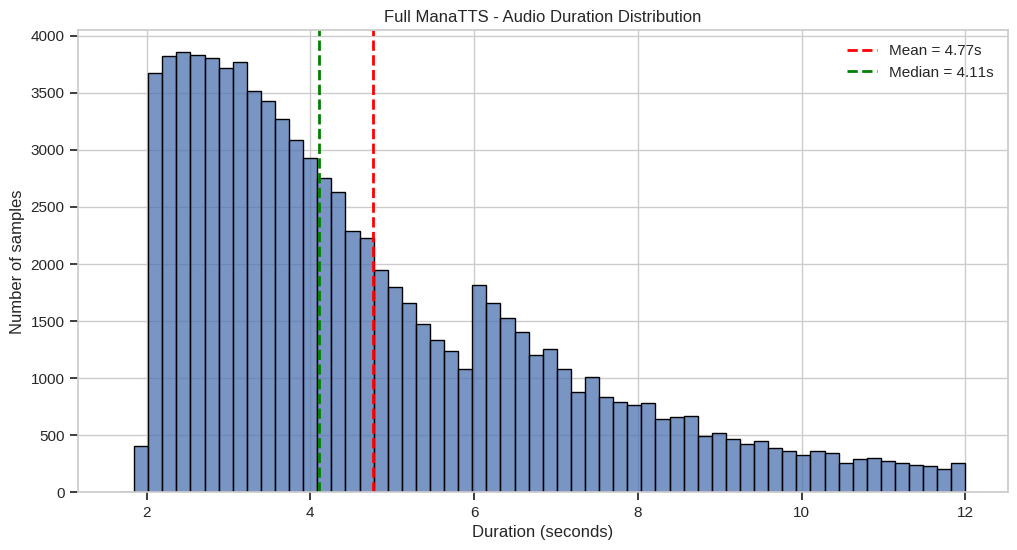

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_duration_distribution.png


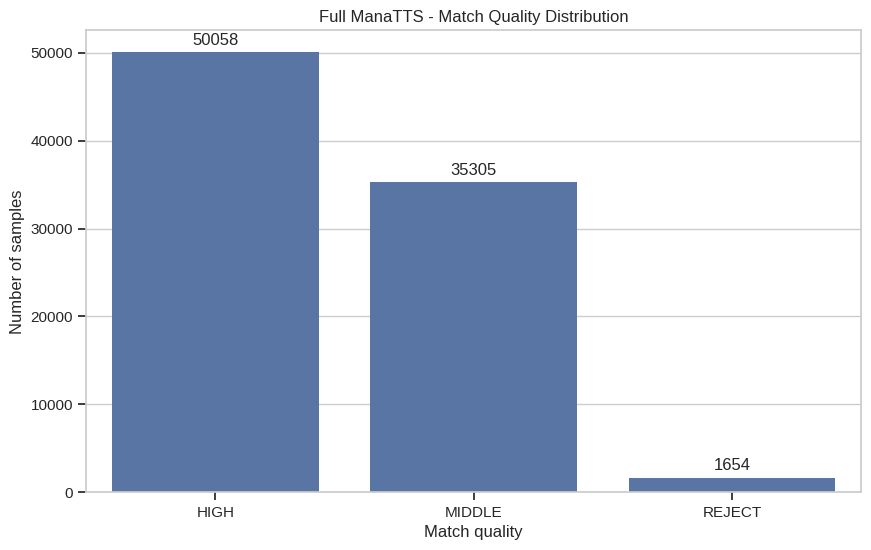

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_match_quality_distribution.png


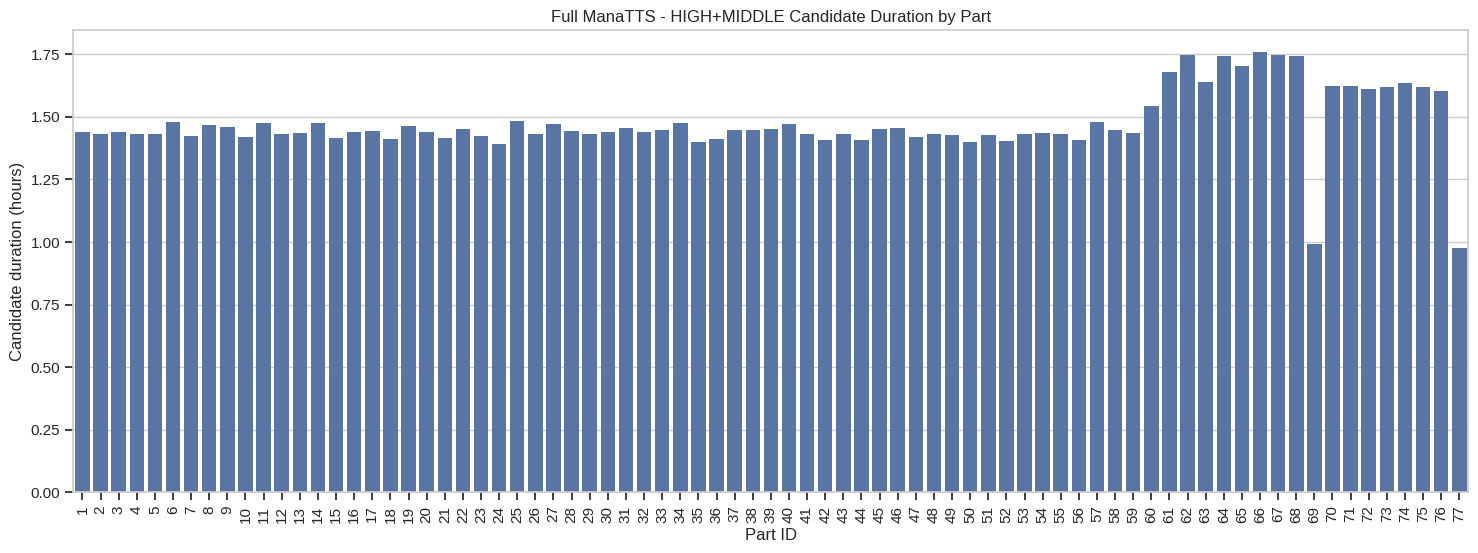

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_candidate_duration_by_part.png


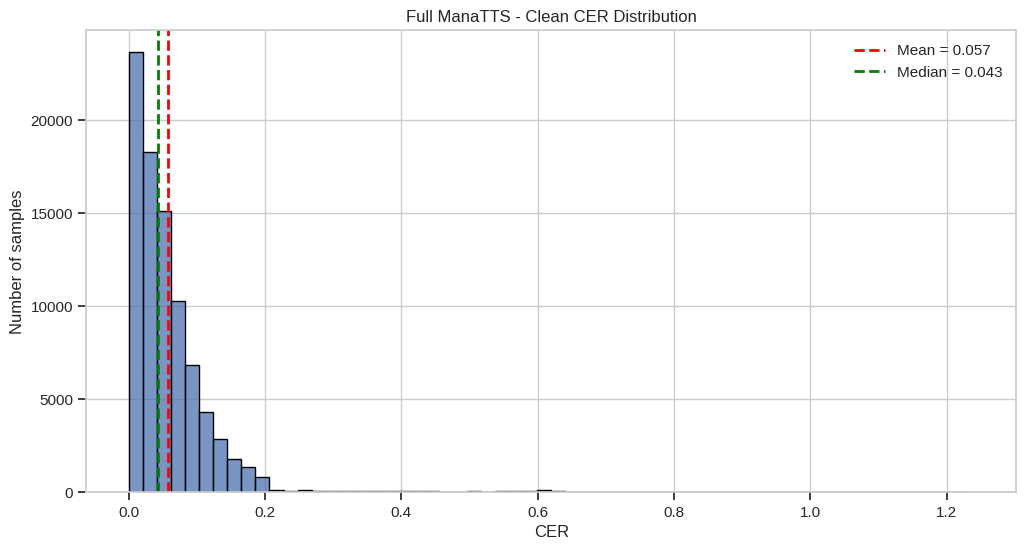

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_clean_cer_distribution.png


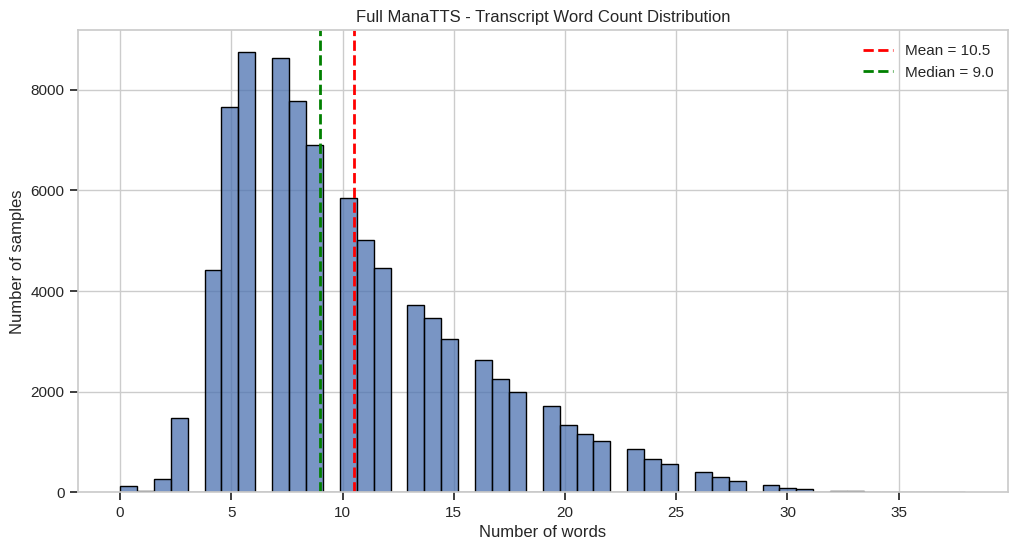

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_transcript_word_count_distribution.png


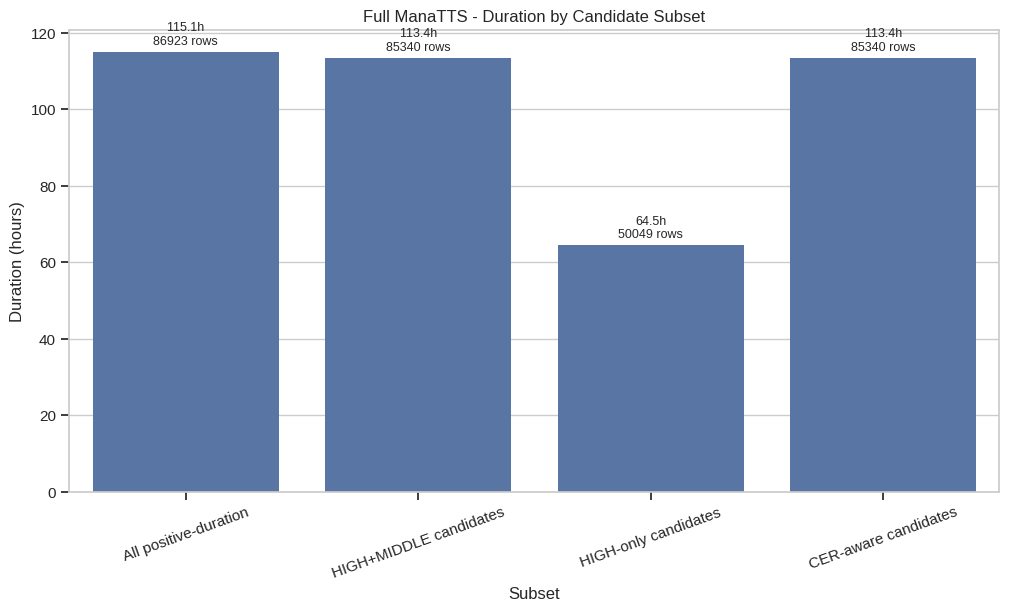

Saved: /content/ManaTTS_Project/reports/figures/full_manatts_candidate_subset_duration_comparison.png

[9] Saving full analysis JSON summary
Summary JSON saved: /content/ManaTTS_Project/reports/full_manatts_metadata_analysis_summary.json

[10] Copying reports to Google Drive if available
Summary and figures copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Metadata CSV backups copied to: /content/drive/MyDrive/ManaTTS_Project/backups

[11] Final summary
Full ManaTTS rows: 87017
HIGH+MIDDLE usable candidate rows: 85340
HIGH+MIDDLE usable candidate duration: 113.446 hours
HIGH-only candidate duration: 64.455 hours
CER-aware candidate duration: 113.446 hours
Next cell will install Piper and download Mana-Persian-Piper.

Cell 7_FULL finished successfully.


In [ ]:
# ============================================================
# Cell 7_FULL: Full ManaTTS Metadata Analysis
# Research Path: ManaTTS + Lightweight Persian Piper TTS
# ============================================================

import json
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

print("=" * 70)
print("Cell 7_FULL: Full ManaTTS Metadata Analysis")
print("=" * 70)

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------
MIN_DURATION_SEC = 1.0
MAX_DURATION_SEC = 12.0
VALID_QUALITIES = ["HIGH", "MIDDLE"]
STRICT_QUALITY = "HIGH"
REQUIRED_SAMPLE_RATE = 44100

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
MANIFEST_CSV_PATH = PROJECT_DIR / "reports" / "manatts_parquet_manifest.csv"

DATA_PARQUET_DIR = PROJECT_DIR / "data" / "parquet"
METADATA_DIR = PROJECT_DIR / "data" / "processed" / "metadata"
REPORTS_DIR = PROJECT_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"
assert MANIFEST_CSV_PATH.exists(), f"Manifest CSV not found: {MANIFEST_CSV_PATH}"

DATA_PARQUET_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

manifest_df = pd.read_csv(MANIFEST_CSV_PATH)

print("\n[1] Settings")
print("Total parts in manifest:", len(manifest_df))
print("Valid qualities:", VALID_QUALITIES)
print("Duration filter:", MIN_DURATION_SEC, "to", MAX_DURATION_SEC, "seconds")
print("Required sample rate:", REQUIRED_SAMPLE_RATE)

# ------------------------------------------------------------
# Check all downloaded Parquet files
# ------------------------------------------------------------
print("\n[2] Checking all downloaded Parquet files")

parquet_paths = []

for idx, row in manifest_df.iterrows():
    file_name = str(row["file_name"])
    expected_size = int(row["size_bytes"])
    path = DATA_PARQUET_DIR / file_name

    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

    actual_size = path.stat().st_size
    size_ok = abs(actual_size - expected_size) <= 1024

    if not size_ok:
        raise RuntimeError(f"File size mismatch for {file_name}")

    parquet_paths.append(path)

print(f"All {len(parquet_paths)} Parquet files are present and verified.")

print("\nFirst 5 files:")
for p in parquet_paths[:5]:
    print(" ", p.name)

print("\nLast 5 files:")
for p in parquet_paths[-5:]:
    print(" ", p.name)

# ------------------------------------------------------------
# Load metadata only from all Parquet files
# ------------------------------------------------------------
print("\n[3] Loading metadata columns from all Parquet files")

metadata_columns = [
    "file name",
    "transcript",
    "duration",
    "match quality",
    "hypothesis",
    "CER",
    "search type",
    "ASRs",
    "samplerate",
]

all_parts = []

for part_id, parquet_path in enumerate(parquet_paths, start=1):
    if part_id == 1 or part_id % 10 == 0 or part_id == len(parquet_paths):
        print(f"Reading part {part_id}/{len(parquet_paths)}: {parquet_path.name}")

    parquet_file = pq.ParquetFile(str(parquet_path))
    available_columns = parquet_file.schema.names
    columns_to_read = [c for c in metadata_columns if c in available_columns]

    table = pq.read_table(str(parquet_path), columns=columns_to_read)
    part_df = table.to_pandas()

    part_df["part_id"] = int(part_id)
    part_df["parquet_file"] = parquet_path.name
    part_df["row_in_part"] = np.arange(len(part_df), dtype=np.int64)

    all_parts.append(part_df)

combined_df = pd.concat(all_parts, ignore_index=True)

print("Combined raw metadata shape:", combined_df.shape)

# ------------------------------------------------------------
# Clean metadata
# ------------------------------------------------------------
print("\n[4] Cleaning metadata")

df = combined_df.copy()

df["file_name"] = df["file name"].fillna("").astype(str)
df["transcript"] = df["transcript"].fillna("").astype(str).str.strip()
df["hypothesis"] = df["hypothesis"].fillna("").astype(str).str.strip()
df["match_quality"] = df["match quality"].fillna("UNKNOWN").astype(str).str.strip()

df["duration"] = pd.to_numeric(df["duration"], errors="coerce")
df["CER_raw"] = pd.to_numeric(df["CER"], errors="coerce")
df["CER_clean"] = df["CER_raw"].replace([np.inf, -np.inf], np.nan)
df["samplerate"] = pd.to_numeric(df["samplerate"], errors="coerce")

df["transcript_char_len"] = df["transcript"].str.len()
df["transcript_word_count"] = df["transcript"].apply(
    lambda x: len(x.split()) if isinstance(x, str) and len(x.strip()) > 0 else 0
)
df["hypothesis_char_len"] = df["hypothesis"].str.len()

df["has_text"] = df["transcript_char_len"] > 0
df["has_positive_duration"] = df["duration"].notna() & np.isfinite(df["duration"]) & (df["duration"] > 0)
df["duration_in_tts_range"] = df["duration"].between(MIN_DURATION_SEC, MAX_DURATION_SEC, inclusive="both")
df["has_valid_samplerate"] = df["samplerate"] == REQUIRED_SAMPLE_RATE
df["quality_high_or_middle"] = df["match_quality"].isin(VALID_QUALITIES)
df["quality_high_only"] = df["match_quality"] == STRICT_QUALITY

df["training_candidate_high_middle"] = (
    df["has_text"]
    & df["has_positive_duration"]
    & df["duration_in_tts_range"]
    & df["has_valid_samplerate"]
    & df["quality_high_or_middle"]
)

df["training_candidate_high_only"] = (
    df["has_text"]
    & df["has_positive_duration"]
    & df["duration_in_tts_range"]
    & df["has_valid_samplerate"]
    & df["quality_high_only"]
)

df["cer_aware_candidate"] = (
    df["training_candidate_high_middle"]
    & df["CER_clean"].notna()
    & (df["CER_clean"] <= 0.20)
)

df["global_id"] = np.arange(len(df), dtype=np.int64)

print("Cleaning done.")

print("\nFirst 5 cleaned rows:")
display(
    df[
        [
            "global_id",
            "part_id",
            "row_in_part",
            "file_name",
            "transcript",
            "duration",
            "match_quality",
            "CER_clean",
            "training_candidate_high_middle",
            "training_candidate_high_only",
        ]
    ].head(5)
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------
print("\n[5] Full dataset summary statistics")

total_rows = int(len(df))
positive_duration_rows = int(df["has_positive_duration"].sum())

high_middle_rows = int(df["training_candidate_high_middle"].sum())
high_only_rows = int(df["training_candidate_high_only"].sum())
cer_aware_rows = int(df["cer_aware_candidate"].sum())

total_valid_duration_hours = float(df.loc[df["has_positive_duration"], "duration"].sum()) / 3600.0
high_middle_duration_hours = float(df.loc[df["training_candidate_high_middle"], "duration"].sum()) / 3600.0
high_only_duration_hours = float(df.loc[df["training_candidate_high_only"], "duration"].sum()) / 3600.0
cer_aware_duration_hours = float(df.loc[df["cer_aware_candidate"], "duration"].sum()) / 3600.0

print("Total rows:", total_rows)
print("Rows with positive duration:", positive_duration_rows)
print("Candidate rows HIGH+MIDDLE:", high_middle_rows)
print("Candidate rows HIGH only:", high_only_rows)
print("CER-aware candidate rows:", cer_aware_rows)

print(f"Total valid duration: {total_valid_duration_hours:.4f} hours")
print(f"HIGH+MIDDLE candidate duration: {high_middle_duration_hours:.4f} hours")
print(f"HIGH-only candidate duration: {high_only_duration_hours:.4f} hours")
print(f"CER-aware candidate duration: {cer_aware_duration_hours:.4f} hours")

print("\nMatch quality counts:")
quality_counts = df["match_quality"].value_counts(dropna=False)
display(quality_counts.to_frame("count"))

print("\nSample rate counts:")
sample_rate_counts = df["samplerate"].value_counts(dropna=False).sort_index()
display(sample_rate_counts.to_frame("count"))

print("\nDuration statistics:")
duration_values = df.loc[df["has_positive_duration"], "duration"]
duration_stats = duration_values.describe()
display(duration_stats.to_frame("duration_sec"))

print("\nClean CER statistics:")
clean_cer = df["CER_clean"].dropna()
clean_cer = clean_cer[np.isfinite(clean_cer)]
clean_cer_stats = clean_cer.describe()
display(clean_cer_stats.to_frame("CER_clean"))

print("\nTranscript character length statistics:")
char_len_values = df["transcript_char_len"].dropna()
char_len_values = char_len_values[np.isfinite(char_len_values)]
char_len_stats = char_len_values.describe()
display(char_len_stats.to_frame("transcript_char_len"))

print("\nTranscript word count statistics:")
word_count_values = df["transcript_word_count"].dropna()
word_count_values = word_count_values[np.isfinite(word_count_values)]
word_count_stats = word_count_values.describe()
display(word_count_stats.to_frame("transcript_word_count"))

# ------------------------------------------------------------
# Part-wise statistics
# ------------------------------------------------------------
print("\n[6] Part-wise statistics")

part_rows = []

for part_id, part_df in df.groupby("part_id"):
    part_total_rows = int(len(part_df))
    part_valid_duration_hours = float(part_df.loc[part_df["has_positive_duration"], "duration"].sum()) / 3600.0

    part_high_middle_rows = int(part_df["training_candidate_high_middle"].sum())
    part_high_middle_duration_hours = (
        float(part_df.loc[part_df["training_candidate_high_middle"], "duration"].sum()) / 3600.0
    )

    part_high_only_rows = int(part_df["training_candidate_high_only"].sum())
    part_high_only_duration_hours = (
        float(part_df.loc[part_df["training_candidate_high_only"], "duration"].sum()) / 3600.0
    )

    part_rows.append({
        "part_id": int(part_id),
        "parquet_file": str(part_df["parquet_file"].iloc[0]),
        "total_rows": part_total_rows,
        "valid_duration_hours": round(part_valid_duration_hours, 6),
        "high_middle_rows": part_high_middle_rows,
        "high_middle_duration_hours": round(part_high_middle_duration_hours, 6),
        "high_only_rows": part_high_only_rows,
        "high_only_duration_hours": round(part_high_only_duration_hours, 6),
    })

part_summary_df = pd.DataFrame(part_rows)

print("Part summary head:")
display(part_summary_df.head(10))

print("Part summary tail:")
display(part_summary_df.tail(10))

# ------------------------------------------------------------
# Save CSV files
# ------------------------------------------------------------
print("\n[7] Saving metadata CSV files")

combined_metadata_csv = METADATA_DIR / "combined_metadata_full_manatts.csv"
candidate_high_middle_csv = METADATA_DIR / "candidate_high_middle_full_manatts.csv"
candidate_high_only_csv = METADATA_DIR / "candidate_high_only_full_manatts.csv"
candidate_cer_aware_csv = METADATA_DIR / "candidate_cer_aware_full_manatts.csv"
part_summary_csv = METADATA_DIR / "part_summary_full_manatts.csv"

df.to_csv(combined_metadata_csv, index=False, encoding="utf-8")
df.loc[df["training_candidate_high_middle"]].to_csv(candidate_high_middle_csv, index=False, encoding="utf-8")
df.loc[df["training_candidate_high_only"]].to_csv(candidate_high_only_csv, index=False, encoding="utf-8")
df.loc[df["cer_aware_candidate"]].to_csv(candidate_cer_aware_csv, index=False, encoding="utf-8")
part_summary_df.to_csv(part_summary_csv, index=False, encoding="utf-8")

print("Combined metadata saved:", combined_metadata_csv)
print("HIGH+MIDDLE candidates saved:", candidate_high_middle_csv)
print("HIGH-only candidates saved:", candidate_high_only_csv)
print("CER-aware candidates saved:", candidate_cer_aware_csv)
print("Part summary saved:", part_summary_csv)

# ------------------------------------------------------------
# Create figures
# ------------------------------------------------------------
print("\n[8] Creating full dataset figures")

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    pass

sns.set_context("notebook")
figure_paths = {}

# Figure 1: Duration distribution
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(duration_values, bins=60, kde=False, ax=ax)

ax.axvline(duration_values.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {duration_values.mean():.2f}s")
ax.axvline(duration_values.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {duration_values.median():.2f}s")

ax.set_title("Full ManaTTS - Audio Duration Distribution")
ax.set_xlabel("Duration (seconds)")
ax.set_ylabel("Number of samples")
ax.legend()

duration_fig_path = FIGURES_DIR / "full_manatts_duration_distribution.png"
fig.savefig(str(duration_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["duration_distribution"] = str(duration_fig_path)
print("Saved:", duration_fig_path)

# Figure 2: Match quality
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=quality_counts.index, y=quality_counts.values, ax=ax)

ax.set_title("Full ManaTTS - Match Quality Distribution")
ax.set_xlabel("Match quality")
ax.set_ylabel("Number of samples")

for i, value in enumerate(quality_counts.values):
    ax.text(i, value + max(quality_counts.values) * 0.01, str(value), ha="center", va="bottom")

quality_fig_path = FIGURES_DIR / "full_manatts_match_quality_distribution.png"
fig.savefig(str(quality_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["match_quality_distribution"] = str(quality_fig_path)
print("Saved:", quality_fig_path)

# Figure 3: Candidate duration by part
fig, ax = plt.subplots(figsize=(18, 6))
sns.barplot(
    data=part_summary_df,
    x="part_id",
    y="high_middle_duration_hours",
    ax=ax,
    color="#4C72B0"
)

ax.set_title("Full ManaTTS - HIGH+MIDDLE Candidate Duration by Part")
ax.set_xlabel("Part ID")
ax.set_ylabel("Candidate duration (hours)")
ax.tick_params(axis="x", rotation=90)

part_duration_fig_path = FIGURES_DIR / "full_manatts_candidate_duration_by_part.png"
fig.savefig(str(part_duration_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["candidate_duration_by_part"] = str(part_duration_fig_path)
print("Saved:", part_duration_fig_path)

# Figure 4: Clean CER distribution
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(clean_cer, bins=60, kde=False, ax=ax)

ax.axvline(clean_cer.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {clean_cer.mean():.3f}")
ax.axvline(clean_cer.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {clean_cer.median():.3f}")

ax.set_title("Full ManaTTS - Clean CER Distribution")
ax.set_xlabel("CER")
ax.set_ylabel("Number of samples")
ax.legend()

cer_fig_path = FIGURES_DIR / "full_manatts_clean_cer_distribution.png"
fig.savefig(str(cer_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["clean_cer_distribution"] = str(cer_fig_path)
print("Saved:", cer_fig_path)

# Figure 5: Transcript word count
fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(word_count_values, bins=50, kde=False, ax=ax)

ax.axvline(word_count_values.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean = {word_count_values.mean():.1f}")
ax.axvline(word_count_values.median(), color="green", linestyle="--", linewidth=2, label=f"Median = {word_count_values.median():.1f}")

ax.set_title("Full ManaTTS - Transcript Word Count Distribution")
ax.set_xlabel("Number of words")
ax.set_ylabel("Number of samples")
ax.legend()

word_count_fig_path = FIGURES_DIR / "full_manatts_transcript_word_count_distribution.png"
fig.savefig(str(word_count_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["transcript_word_count_distribution"] = str(word_count_fig_path)
print("Saved:", word_count_fig_path)

# Figure 6: Candidate subset duration comparison
subset_duration_df = pd.DataFrame({
    "subset": [
        "All positive-duration",
        "HIGH+MIDDLE candidates",
        "HIGH-only candidates",
        "CER-aware candidates"
    ],
    "duration_hours": [
        total_valid_duration_hours,
        high_middle_duration_hours,
        high_only_duration_hours,
        cer_aware_duration_hours
    ],
    "rows": [
        positive_duration_rows,
        high_middle_rows,
        high_only_rows,
        cer_aware_rows
    ]
})

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=subset_duration_df, x="subset", y="duration_hours", ax=ax)

ax.set_title("Full ManaTTS - Duration by Candidate Subset")
ax.set_xlabel("Subset")
ax.set_ylabel("Duration (hours)")
ax.tick_params(axis="x", rotation=20)

for i, row in subset_duration_df.iterrows():
    ax.text(
        i,
        row["duration_hours"] + max(subset_duration_df["duration_hours"]) * 0.01,
        f'{row["duration_hours"]:.1f}h\n{int(row["rows"])} rows',
        ha="center",
        va="bottom",
        fontsize=9
    )

subset_duration_fig_path = FIGURES_DIR / "full_manatts_candidate_subset_duration_comparison.png"
fig.savefig(str(subset_duration_fig_path), dpi=150, bbox_inches="tight")
plt.show()

figure_paths["candidate_subset_duration_comparison"] = str(subset_duration_fig_path)
print("Saved:", subset_duration_fig_path)

# ------------------------------------------------------------
# Save JSON summary
# ------------------------------------------------------------
print("\n[9] Saving full analysis JSON summary")

summary = {
    "created_at": datetime.now().isoformat(),
    "num_parts": int(len(parquet_paths)),
    "parquet_files": [p.name for p in parquet_paths],
    "filtering_rules": {
        "min_duration_sec": float(MIN_DURATION_SEC),
        "max_duration_sec": float(MAX_DURATION_SEC),
        "valid_qualities": VALID_QUALITIES,
        "strict_quality": STRICT_QUALITY,
        "required_sample_rate": int(REQUIRED_SAMPLE_RATE),
        "non_empty_transcript": True
    },
    "total_rows": int(total_rows),
    "rows_with_positive_duration": int(positive_duration_rows),
    "candidate_rows_high_middle": int(high_middle_rows),
    "candidate_rows_high_only": int(high_only_rows),
    "candidate_rows_cer_aware": int(cer_aware_rows),
    "total_valid_duration_hours": round(float(total_valid_duration_hours), 6),
    "candidate_duration_high_middle_hours": round(float(high_middle_duration_hours), 6),
    "candidate_duration_high_only_hours": round(float(high_only_duration_hours), 6),
    "candidate_duration_cer_aware_hours": round(float(cer_aware_duration_hours), 6),
    "match_quality_counts": {
        str(k): int(v) for k, v in quality_counts.to_dict().items()
    },
    "sample_rate_counts": {
        str(k): int(v) for k, v in sample_rate_counts.to_dict().items()
    },
    "duration_stats": {
        str(k): float(v) for k, v in duration_stats.to_dict().items()
    },
    "clean_cer_stats": {
        str(k): float(v) for k, v in clean_cer_stats.to_dict().items()
    },
    "transcript_char_len_stats": {
        str(k): float(v) for k, v in char_len_stats.to_dict().items()
    },
    "transcript_word_count_stats": {
        str(k): float(v) for k, v in word_count_stats.to_dict().items()
    },
    "metadata_files": {
        "combined_metadata_csv": str(combined_metadata_csv),
        "candidate_high_middle_csv": str(candidate_high_middle_csv),
        "candidate_high_only_csv": str(candidate_high_only_csv),
        "candidate_cer_aware_csv": str(candidate_cer_aware_csv),
        "part_summary_csv": str(part_summary_csv),
    },
    "figures": figure_paths,
    "research_note": (
        "This full-dataset analysis documents the ManaTTS corpus used in the lightweight Persian TTS project. "
        "The final synthesis system will use a ManaTTS-finetuned Piper model with punctuation-aware "
        "automatic pause control and pause-preserving speed control."
    )
}

summary_json_path = REPORTS_DIR / "full_manatts_metadata_analysis_summary.json"

with open(summary_json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, allow_nan=False)

print("Summary JSON saved:", summary_json_path)

# ------------------------------------------------------------
# Copy reports to Google Drive
# ------------------------------------------------------------
print("\n[10] Copying reports to Google Drive if available")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(summary_json_path), str(drive_reports_dir / summary_json_path.name))

    drive_figures_dir = drive_reports_dir / "figures_full_manatts"
    drive_figures_dir.mkdir(parents=True, exist_ok=True)

    for _, fig_path in figure_paths.items():
        fig_path = Path(fig_path)
        if fig_path.exists():
            shutil.copy2(str(fig_path), str(drive_figures_dir / fig_path.name))

    print("Summary and figures copied to:", drive_reports_dir)

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)

    # Metadata files are not audio, so they should be manageable.
    for csv_path in [
        combined_metadata_csv,
        candidate_high_middle_csv,
        candidate_high_only_csv,
        candidate_cer_aware_csv,
        part_summary_csv,
    ]:
        if csv_path.exists():
            shutil.copy2(str(csv_path), str(drive_backups_dir / csv_path.name))

    print("Metadata CSV backups copied to:", drive_backups_dir)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n[11] Final summary")
print(f"Full ManaTTS rows: {total_rows}")
print(f"HIGH+MIDDLE usable candidate rows: {high_middle_rows}")
print(f"HIGH+MIDDLE usable candidate duration: {high_middle_duration_hours:.3f} hours")
print(f"HIGH-only candidate duration: {high_only_duration_hours:.3f} hours")
print(f"CER-aware candidate duration: {cer_aware_duration_hours:.3f} hours")
print("Next cell will install Piper and download Mana-Persian-Piper.")

print("\n" + "=" * 70)
print("Cell 7_FULL finished successfully.")
print("=" * 70)

In [3]:
# ============================================================
# Cell 8: Install Piper and Download Mana-Persian-Piper Model
# Research Path: ManaTTS + Lightweight Persian Piper TTS
# ============================================================

import os
import sys
import json
import shutil
import subprocess
from pathlib import Path
from datetime import datetime

print("=" * 70)
print("Cell 8: Install Piper and Download Mana-Persian-Piper Model")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"

MODELS_DIR = PROJECT_DIR / "models"
PIPER_MODELS_DIR = MODELS_DIR / "piper"
MANA_PIPER_DIR = PIPER_MODELS_DIR / "Mana-Persian-Piper"

CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Config file not found: {CONFIG_PATH}"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
PIPER_MODELS_DIR.mkdir(parents=True, exist_ok=True)
MANA_PIPER_DIR.mkdir(parents=True, exist_ok=True)
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

print("\n[1] Paths")
print("Project directory:", PROJECT_DIR)
print("Piper models directory:", PIPER_MODELS_DIR)
print("Mana-Persian-Piper directory:", MANA_PIPER_DIR)

# ------------------------------------------------------------
# Disk space check
# ------------------------------------------------------------
print("\n[2] Disk space check")

total, used, free = shutil.disk_usage("/content")

print(f"/content total: {total / (1024 ** 3):.2f} GB")
print(f"/content used : {used / (1024 ** 3):.2f} GB")
print(f"/content free : {free / (1024 ** 3):.2f} GB")

if free / (1024 ** 3) < 2.0:
    raise RuntimeError("Not enough disk space for Piper model download.")

print("Disk space check: OK")

# ------------------------------------------------------------
# Install system dependencies
# ------------------------------------------------------------
print("\n[3] Installing system dependencies")

# Piper normally uses espeak-ng / phonemization components.
# We install espeak-ng to avoid missing frontend issues.
apt_cmd = [
    "apt-get",
    "update",
    "-qq"
]

result = subprocess.run(
    apt_cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    check=False
)

if result.returncode != 0:
    print("apt-get update warning/error:")
    print(result.stderr[-2000:])
else:
    print("apt-get update: OK")

apt_install_cmd = [
    "apt-get",
    "install",
    "-y",
    "-qq",
    "espeak-ng",
    "ffmpeg"
]

result = subprocess.run(
    apt_install_cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    check=False
)

if result.returncode != 0:
    print("System dependency installation failed.")
    print("STDOUT:")
    print(result.stdout[-3000:])
    print("STDERR:")
    print(result.stderr[-3000:])
    raise RuntimeError("Failed to install system dependencies.")
else:
    print("System dependencies installed: OK")

# ------------------------------------------------------------
# Install Python dependencies
# ------------------------------------------------------------
print("\n[4] Installing Python packages")

# We do not reinstall torch.
# piper-tts should install Piper runtime and its dependencies.
pip_packages = [
    "piper-tts",
    "huggingface_hub>=0.23.0",
    "onnxruntime",
    "soundfile",
]

pip_cmd = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",
    "--upgrade",
] + pip_packages

print("Running:", " ".join(pip_cmd))

result = subprocess.run(
    pip_cmd,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE,
    text=True,
    check=False
)

if result.returncode != 0:
    print("pip install failed.")
    print("STDOUT:")
    print(result.stdout[-4000:])
    print("STDERR:")
    print(result.stderr[-4000:])
    raise RuntimeError("Failed to install Python packages.")
else:
    print("Python packages installed: OK")

# ------------------------------------------------------------
# Verify imports
# ------------------------------------------------------------
print("\n[5] Verifying imports")

import importlib
import importlib.metadata as importlib_metadata

packages_to_check = [
    ("huggingface_hub", "huggingface_hub"),
    ("onnxruntime", "onnxruntime"),
    ("soundfile", "soundfile"),
]

versions = {}

for package_name, import_name in packages_to_check:
    try:
        module = importlib.import_module(import_name)
        try:
            version = importlib_metadata.version(package_name)
        except Exception:
            version = getattr(module, "__version__", "unknown")

        versions[package_name] = version
        print(f"{package_name:18s}: OK | version={version}")
    except Exception as e:
        versions[package_name] = None
        print(f"{package_name:18s}: FAILED | error={repr(e)}")
        raise

# Piper import can vary by package version.
PiperVoice = None
piper_import_style = None

try:
    from piper import PiperVoice as _PiperVoice
    PiperVoice = _PiperVoice
    piper_import_style = "from piper import PiperVoice"
    print("piper import: OK | from piper import PiperVoice")
except Exception as e1:
    try:
        from piper.voice import PiperVoice as _PiperVoice
        PiperVoice = _PiperVoice
        piper_import_style = "from piper.voice import PiperVoice"
        print("piper import: OK | from piper.voice import PiperVoice")
    except Exception as e2:
        print("piper import failed.")
        print("Error 1:", repr(e1))
        print("Error 2:", repr(e2))
        raise RuntimeError("Could not import PiperVoice from piper package.")

assert PiperVoice is not None, "PiperVoice import failed unexpectedly."

# ------------------------------------------------------------
# Download Mana-Persian-Piper from Hugging Face
# ------------------------------------------------------------
print("\n[6] Downloading Mana-Persian-Piper model from Hugging Face")

from huggingface_hub import snapshot_download

PIPER_REPO_ID = "MahtaFetrat/Mana-Persian-Piper"

print("Hugging Face repo:", PIPER_REPO_ID)
print("Local directory:", MANA_PIPER_DIR)

# Download only useful model files.
# This avoids pulling unnecessary git metadata.
try:
    downloaded_path = snapshot_download(
        repo_id=PIPER_REPO_ID,
        repo_type="model",
        local_dir=str(MANA_PIPER_DIR),
        allow_patterns=[
            "*.onnx",
            "*.json",
            "*.txt",
            "*.md",
            "README*",
            "MODEL_CARD*",
            "LICENSE*",
        ],
    )

    print("Model snapshot downloaded to:", downloaded_path)

except Exception as e:
    print("Failed to download model snapshot.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Locate model files
# ------------------------------------------------------------
print("\n[7] Locating ONNX and JSON config files")

onnx_files = sorted(MANA_PIPER_DIR.rglob("*.onnx"))
json_files = sorted(MANA_PIPER_DIR.rglob("*.json"))

print("ONNX files found:", len(onnx_files))
for p in onnx_files:
    print(f"  {p.name} | {p.stat().st_size / (1024 ** 2):.2f} MB")

print("JSON files found:", len(json_files))
for p in json_files:
    print(f"  {p.name} | {p.stat().st_size / 1024:.2f} KB")

if len(onnx_files) == 0:
    raise FileNotFoundError("No .onnx model file found in Mana-Persian-Piper directory.")

# Choose largest ONNX file as model, safest if extra ONNX files exist.
model_onnx_path = max(onnx_files, key=lambda p: p.stat().st_size)

# Piper config is usually model.onnx.json
expected_config_path = Path(str(model_onnx_path) + ".json")

if expected_config_path.exists():
    model_json_path = expected_config_path
else:
    # Fallback: choose JSON with closest stem
    same_stem_candidates = [
        p for p in json_files
        if model_onnx_path.stem in p.name or p.stem in model_onnx_path.name
    ]

    if len(same_stem_candidates) > 0:
        model_json_path = same_stem_candidates[0]
    elif len(json_files) == 1:
        model_json_path = json_files[0]
    else:
        raise FileNotFoundError(
            f"Could not determine Piper JSON config for {model_onnx_path.name}. "
            f"JSON files found: {[p.name for p in json_files]}"
        )

print("\nSelected model ONNX:", model_onnx_path)
print("Selected model JSON:", model_json_path)

if not model_onnx_path.exists():
    raise FileNotFoundError(f"ONNX file not found: {model_onnx_path}")

if not model_json_path.exists():
    raise FileNotFoundError(f"JSON config file not found: {model_json_path}")

# ------------------------------------------------------------
# Inspect Piper JSON config
# ------------------------------------------------------------
print("\n[8] Inspecting Piper model config")

with open(model_json_path, "r", encoding="utf-8") as f:
    piper_json = json.load(f)

print("Piper config top-level keys:", list(piper_json.keys()))

sample_rate = None
num_speakers = None
phoneme_type = None
language_info = None

# Piper config structures can vary, so access safely.
if "audio" in piper_json and isinstance(piper_json["audio"], dict):
    sample_rate = piper_json["audio"].get("sample_rate", None)

if sample_rate is None:
    sample_rate = piper_json.get("sample_rate", None)

if "num_speakers" in piper_json:
    num_speakers = piper_json.get("num_speakers")

if "phoneme_type" in piper_json:
    phoneme_type = piper_json.get("phoneme_type")

if "language" in piper_json:
    language_info = piper_json.get("language")

print("Model sample_rate:", sample_rate)
print("Model num_speakers:", num_speakers)
print("Model phoneme_type:", phoneme_type)
print("Model language:", language_info)

# ------------------------------------------------------------
# Load Piper model once
# ------------------------------------------------------------
print("\n[9] Loading Piper model once for sanity check")

try:
    # Different versions accept config_path; most can infer config as model.onnx.json.
    try:
        voice = PiperVoice.load(str(model_onnx_path), config_path=str(model_json_path), use_cuda=False)
    except TypeError:
        # Older/newer API fallback
        voice = PiperVoice.load(str(model_onnx_path))

    print("Piper model loaded successfully.")
    print("Voice object type:", type(voice))

except Exception as e:
    print("Piper model load failed.")
    print("Error:", repr(e))
    raise

# Avoid keeping model object unnecessarily in memory for now.
del voice

# ------------------------------------------------------------
# Save project model config
# ------------------------------------------------------------
print("\n[10] Saving Piper model project config")

piper_project_config = {
    "created_at": datetime.now().isoformat(),
    "repo_id": PIPER_REPO_ID,
    "local_dir": str(MANA_PIPER_DIR),
    "model_onnx_path": str(model_onnx_path),
    "model_json_path": str(model_json_path),
    "model_onnx_size_mb": round(model_onnx_path.stat().st_size / (1024 ** 2), 3),
    "model_json_size_kb": round(model_json_path.stat().st_size / 1024, 3),
    "sample_rate": sample_rate,
    "num_speakers": num_speakers,
    "phoneme_type": phoneme_type,
    "language": language_info,
    "piper_import_style": piper_import_style,
    "python_package_versions": versions,
    "notes": (
        "Mana-Persian-Piper is the selected lightweight Persian TTS model. "
        "It is a Piper/VITS/ONNX model fine-tuned on ManaTTS and suitable for "
        "low-latency and on-device inference."
    ),
}

piper_config_path = CONFIGS_DIR / "mana_persian_piper_model_config.json"

with open(piper_config_path, "w", encoding="utf-8") as f:
    json.dump(piper_project_config, f, ensure_ascii=False, indent=2)

print("Piper model config saved to:", piper_config_path)

# ------------------------------------------------------------
# Save report
# ------------------------------------------------------------
print("\n[11] Saving Cell 8 report")

cell8_report = {
    "created_at": datetime.now().isoformat(),
    "status": "success",
    "piper_repo_id": PIPER_REPO_ID,
    "model_onnx_path": str(model_onnx_path),
    "model_json_path": str(model_json_path),
    "model_onnx_size_mb": round(model_onnx_path.stat().st_size / (1024 ** 2), 3),
    "sample_rate": sample_rate,
    "piper_config_path": str(piper_config_path),
    "piper_import_style": piper_import_style,
}

cell8_report_path = REPORTS_DIR / "cell8_piper_install_download_report.json"

with open(cell8_report_path, "w", encoding="utf-8") as f:
    json.dump(cell8_report, f, ensure_ascii=False, indent=2)

print("Cell 8 report saved to:", cell8_report_path)

# ------------------------------------------------------------
# Copy small configs/reports to Google Drive
# ------------------------------------------------------------
print("\n[12] Copying small config/report files to Google Drive")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(cell8_report_path), str(drive_reports_dir / cell8_report_path.name))
    print("Report copied to:", drive_reports_dir)

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(piper_config_path), str(drive_backups_dir / piper_config_path.name))
    print("Piper config copied to:", drive_backups_dir)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n[13] Final summary")
print("Selected model:", model_onnx_path.name)
print("Model size:", f"{model_onnx_path.stat().st_size / (1024 ** 2):.2f} MB")
print("Selected config:", model_json_path.name)
print("Sample rate:", sample_rate)
print("Piper model load: OK")
print("Next cell will synthesize a simple Persian sentence.")

print("\n" + "=" * 70)
print("Cell 8 finished successfully.")
print("=" * 70)

Cell 8: Install Piper and Download Mana-Persian-Piper Model

[1] Paths
Project directory: /content/ManaTTS_Project
Piper models directory: /content/ManaTTS_Project/models/piper
Mana-Persian-Piper directory: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper

[2] Disk space check
/content total: 112.64 GB
/content used : 47.37 GB
/content free : 65.25 GB
Disk space check: OK

[3] Installing system dependencies
apt-get update: OK
System dependencies installed: OK

[4] Installing Python packages
Running: /usr/bin/python3 -m pip install -q --upgrade piper-tts huggingface_hub>=0.23.0 onnxruntime soundfile
Python packages installed: OK

[5] Verifying imports
huggingface_hub   : OK | version=1.31.0
onnxruntime       : OK | version=1.30.0
soundfile         : OK | version=0.14.0
piper import: OK | from piper import PiperVoice

[6] Downloading Mana-Persian-Piper model from Hugging Face
Hugging Face repo: MahtaFetrat/Mana-Persian-Piper
Local directory: /content/ManaTTS_Project/models/piper/

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Model snapshot downloaded to: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper

[7] Locating ONNX and JSON config files
ONNX files found: 1
  fa_IR-mana-medium.onnx | 60.59 MB
JSON files found: 3
  ad9dd8518bedf517bd7cbc9f63b8e5c844bf5bc0.json | 1.05 KB
  config.json | 6.92 KB
  fa_IR-mana-medium.onnx.json | 6.92 KB

Selected model ONNX: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx
Selected model JSON: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx.json

[8] Inspecting Piper model config
Piper config top-level keys: ['dataset', 'audio', 'espeak', 'language', 'inference', 'phoneme_type', 'phoneme_map', 'phoneme_id_map', 'num_symbols', 'num_speakers', 'speaker_id_map', 'piper_version']
Model sample_rate: 22050
Model num_speakers: 1
Model phoneme_type: espeak
Model language: {'code': 'fa'}

[9] Loading Piper model once for sanity check
Piper model loaded successfully.
Voice object type: <class 'piper.voice.PiperVo

In [4]:
# ============================================================
# Cell 9: Basic Persian Inference Test with Mana-Persian-Piper
# Research Path: ManaTTS + Lightweight Persian Piper TTS
# ============================================================

import json
import time
import wave
import shutil
from pathlib import Path
from datetime import datetime

import numpy as np
import soundfile as sf

from IPython.display import Audio, display

print("=" * 70)
print("Cell 9: Basic Persian Inference Test with Mana-Persian-Piper")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SAMPLES_DIR = PROJECT_DIR / "samples" / "piper_basic_inference"
REPORTS_DIR = PROJECT_DIR / "reports"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}. Please run Cell 8 first."

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper JSON config not found: {model_json_path}"

print("\n[1] Model paths")
print("ONNX:", model_onnx_path)
print("JSON:", model_json_path)
print("Model size:", f"{model_onnx_path.stat().st_size / (1024 ** 2):.2f} MB")

# ------------------------------------------------------------
# Import Piper
# ------------------------------------------------------------
print("\n[2] Importing Piper")

PiperVoice = None

try:
    from piper import PiperVoice as _PiperVoice
    PiperVoice = _PiperVoice
    print("Import OK: from piper import PiperVoice")
except Exception as e1:
    try:
        from piper.voice import PiperVoice as _PiperVoice
        PiperVoice = _PiperVoice
        print("Import OK: from piper.voice import PiperVoice")
    except Exception as e2:
        print("Piper import failed.")
        print("Error 1:", repr(e1))
        print("Error 2:", repr(e2))
        raise

assert PiperVoice is not None, "PiperVoice import failed."

# ------------------------------------------------------------
# Load model
# ------------------------------------------------------------
print("\n[3] Loading Piper model")

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start

    print("Piper model loaded successfully.")
    print(f"Model load time: {load_time:.3f} seconds")
    print("Voice object type:", type(voice))

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Inspect available synthesis methods
# ------------------------------------------------------------
print("\n[4] Inspecting available Piper methods")

available_methods = [m for m in dir(voice) if not m.startswith("_")]
important_methods = [m for m in available_methods if "synth" in m.lower() or "wav" in m.lower()]

print("Synthesis-related methods:")
for m in important_methods:
    print(" ", m)

# ------------------------------------------------------------
# Define robust synthesis helper
# ------------------------------------------------------------
print("\n[5] Defining robust synthesis helper")

def synthesize_piper_to_wav(
    voice,
    text,
    output_wav_path,
    length_scale=None,
    noise_scale=None,
    noise_w=None,
    sentence_silence=0.0
):
    """
    Robust wrapper around Piper Python API.
    Saves one WAV file.
    """
    output_wav_path = Path(output_wav_path)

    if output_wav_path.exists():
        output_wav_path.unlink()

    text = str(text).strip()

    if not text:
        raise ValueError("Input text is empty.")

    # Piper normally writes to an opened wave file.
    with wave.open(str(output_wav_path), "wb") as wav_file:
        # Newer/standard API
        if hasattr(voice, "synthesize_wav"):
            try:
                voice.synthesize_wav(
                    text,
                    wav_file,
                    length_scale=length_scale,
                    noise_scale=noise_scale,
                    noise_w=noise_w,
                    sentence_silence=sentence_silence,
                )
                return output_wav_path
            except TypeError:
                # Some versions may not accept all keyword args
                voice.synthesize_wav(text, wav_file)
                return output_wav_path

        # Alternative API
        if hasattr(voice, "synthesize"):
            try:
                voice.synthesize(
                    text,
                    wav_file,
                    length_scale=length_scale,
                    noise_scale=noise_scale,
                    noise_w=noise_w,
                    sentence_silence=sentence_silence,
                )
                return output_wav_path
            except TypeError:
                voice.synthesize(text, wav_file)
                return output_wav_path

    raise RuntimeError("No supported Piper synthesis method found.")

print("Synthesis helper ready.")

# ------------------------------------------------------------
# Basic test sentence
# ------------------------------------------------------------
print("\n[6] Synthesizing one Persian sentence")

test_text = "سلام این یک آزمایش ساده برای سامانه متن به گفتار فارسی است."

output_wav_path = SAMPLES_DIR / "basic_persian_piper_output.wav"

print("Input text:")
print(test_text)
print("Output path:", output_wav_path)

synth_start = time.time()

try:
    synthesize_piper_to_wav(
        voice=voice,
        text=test_text,
        output_wav_path=output_wav_path,
        length_scale=1.0,
        sentence_silence=0.0
    )

    synth_time = time.time() - synth_start
    print("Synthesis completed successfully.")
    print(f"Synthesis time: {synth_time:.3f} seconds")

except Exception as e:
    print("Synthesis failed.")
    print("Error:", repr(e))
    raise

assert output_wav_path.exists(), f"Output WAV was not created: {output_wav_path}"

# ------------------------------------------------------------
# Inspect generated audio
# ------------------------------------------------------------
print("\n[7] Inspecting generated audio")

audio, sr = sf.read(str(output_wav_path), dtype="float32")

if audio.ndim > 1:
    audio_mono = np.mean(audio, axis=1).astype(np.float32)
else:
    audio_mono = audio.astype(np.float32)

duration_sec = len(audio_mono) / sr
rtf = synth_time / max(duration_sec, 1e-8)

peak = float(np.max(np.abs(audio_mono))) if len(audio_mono) > 0 else 0.0
rms = float(np.sqrt(np.mean(audio_mono ** 2))) if len(audio_mono) > 0 else 0.0

print("Sample rate:", sr)
print("Audio shape:", audio_mono.shape)
print(f"Audio duration: {duration_sec:.3f} seconds")
print(f"RTF = synthesis_time / audio_duration = {rtf:.4f}")
print(f"Generation speed = {1.0 / max(rtf, 1e-8):.2f}x real-time")
print(f"Peak amplitude: {peak:.4f}")
print(f"RMS amplitude: {rms:.4f}")
print("File size:", f"{output_wav_path.stat().st_size / 1024:.2f} KB")

if duration_sec <= 0:
    raise RuntimeError("Generated audio duration is zero.")

if peak < 1e-5:
    raise RuntimeError("Generated audio seems silent or near-silent.")

print("Generated audio sanity check: OK")

# ------------------------------------------------------------
# Play audio
# ------------------------------------------------------------
print("\n[8] Audio preview")
display(Audio(str(output_wav_path)))

# ------------------------------------------------------------
# Save report
# ------------------------------------------------------------
print("\n[9] Saving inference report")

report = {
    "created_at": datetime.now().isoformat(),
    "model_onnx_path": str(model_onnx_path),
    "model_json_path": str(model_json_path),
    "model_size_mb": round(model_onnx_path.stat().st_size / (1024 ** 2), 3),
    "input_text": test_text,
    "output_wav_path": str(output_wav_path),
    "model_load_time_sec": round(float(load_time), 6),
    "synthesis_time_sec": round(float(synth_time), 6),
    "audio_duration_sec": round(float(duration_sec), 6),
    "rtf": round(float(rtf), 6),
    "generation_speed_x_realtime": round(float(1.0 / max(rtf, 1e-8)), 6),
    "sample_rate": int(sr),
    "peak_amplitude": round(float(peak), 6),
    "rms_amplitude": round(float(rms), 6),
    "file_size_bytes": int(output_wav_path.stat().st_size),
    "status": "success",
    "research_note": (
        "This is the first successful inference test with the lightweight "
        "Mana-Persian-Piper model. Later cells will add punctuation-aware "
        "automatic pause and pause-preserving speed control."
    )
}

report_path = REPORTS_DIR / "cell9_basic_piper_inference_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("Report saved:", report_path)

# ------------------------------------------------------------
# Copy small outputs to Google Drive
# ------------------------------------------------------------
print("\n[10] Copying report and sample audio to Google Drive if available")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(report_path), str(drive_reports_dir / report_path.name))
    print("Report copied to:", drive_reports_dir)

if drive_samples_dir is not None:
    drive_samples_dir = Path(drive_samples_dir) / "piper_basic_inference"
    drive_samples_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(output_wav_path), str(drive_samples_dir / output_wav_path.name))
    print("Audio sample copied to:", drive_samples_dir)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n[11] Final summary")
print("Basic Persian Piper inference: OK")
print("Output WAV:", output_wav_path)
print(f"Duration: {duration_sec:.3f}s")
print(f"Synthesis time: {synth_time:.3f}s")
print(f"RTF: {rtf:.4f}")
print(f"Speed: {1.0 / max(rtf, 1e-8):.2f}x real-time")
print("Next cell will implement intelligent punctuation-aware pause and pause-preserving speed control.")

print("\n" + "=" * 70)
print("Cell 9 finished successfully.")
print("=" * 70)

Cell 9: Basic Persian Inference Test with Mana-Persian-Piper

[1] Model paths
ONNX: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx
JSON: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx.json
Model size: 60.59 MB

[2] Importing Piper
Import OK: from piper import PiperVoice

[3] Loading Piper model
Piper model loaded successfully.
Model load time: 1.900 seconds
Voice object type: <class 'piper.voice.PiperVoice'>

[4] Inspecting available Piper methods
Synthesis-related methods:
  synthesize
  synthesize_wav

[5] Defining robust synthesis helper
Synthesis helper ready.

[6] Synthesizing one Persian sentence
Input text:
سلام این یک آزمایش ساده برای سامانه متن به گفتار فارسی است.
Output path: /content/ManaTTS_Project/samples/piper_basic_inference/basic_persian_piper_output.wav
Synthesis completed successfully.
Synthesis time: 0.836 seconds

[7] Inspecting generated audio
Sample rate: 22050
Audio shape: (99584,)
Audio duration: 


[9] Saving inference report
Report saved: /content/ManaTTS_Project/reports/cell9_basic_piper_inference_report.json

[10] Copying report and sample audio to Google Drive if available
Report copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Audio sample copied to: /content/drive/MyDrive/ManaTTS_Project/samples/piper_basic_inference

[11] Final summary
Basic Persian Piper inference: OK
Output WAV: /content/ManaTTS_Project/samples/piper_basic_inference/basic_persian_piper_output.wav
Duration: 4.516s
Synthesis time: 0.836s
RTF: 0.1851
Speed: 5.40x real-time
Next cell will implement intelligent punctuation-aware pause and pause-preserving speed control.

Cell 9 finished successfully.


In [5]:
# ============================================================
# Cell 10_FINAL: Interactive Controlled Persian TTS
# One Output + Speaker Selector + Speed Selector
# Innovation: Intelligent Pause + Pause-Preserving Speed + Short Segment Handling
# ============================================================

import json
import time
import wave
import re
import shutil
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import soundfile as sf

from IPython.display import Audio, display, clear_output

print("=" * 70)
print("Cell 10_FINAL: Interactive Controlled Persian TTS")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SRC_DIR = PROJECT_DIR / "src"
CONFIGS_DIR = PROJECT_DIR / "configs"
SAMPLES_DIR = PROJECT_DIR / "samples" / "final_interactive_tts"
TEMP_DIR = SAMPLES_DIR / "temp_segments"
REPORTS_DIR = PROJECT_DIR / "reports"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}. Please run Cell 8 first."

SRC_DIR.mkdir(parents=True, exist_ok=True)
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)
SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper JSON config not found: {model_json_path}"

print("\n[1] Paths OK")
print("ONNX:", model_onnx_path)
print("JSON:", model_json_path)
print("Final samples dir:", SAMPLES_DIR)

# ------------------------------------------------------------
# Save final UI/prosody config
# ------------------------------------------------------------
print("\n[2] Saving final TTS control config")

final_tts_config = {
    "created_at": datetime.now().isoformat(),
    "model": {
        "name": "Mana-Persian-Piper",
        "onnx_path": str(model_onnx_path),
        "json_path": str(model_json_path),
        "sample_rate": piper_project_config.get("sample_rate", 22050),
        "model_size_mb": piper_project_config.get("model_onnx_size_mb", None),
    },
    "speaker_profiles": {
        "female": {
            "label_fa": "زن",
            "available": True,
            "description": "صدای فعال پروژه بر پایه Mana-Persian-Piper"
        },
        "male": {
            "label_fa": "مرد",
            "available": False,
            "description": "توسعه آینده؛ نیازمند مدل مردانه جداگانه"
        }
    },
    "speed_levels": {
        "slow": {
            "label_fa": "آرام",
            "piper_length_scale": 1.20
        },
        "normal": {
            "label_fa": "عادی",
            "piper_length_scale": 1.00
        },
        "fast": {
            "label_fa": "تند",
            "piper_length_scale": 0.85
        }
    },
    "default_speaker": "female",
    "default_speed": "normal",
    "punctuation_pause_seconds": {
        "،": 0.25,
        ",": 0.25,
        "؛": 0.45,
        ";": 0.45,
        ".": 0.75,
        "؟": 0.85,
        "?": 0.85,
        "!": 0.80,
        "\n": 1.20
    },
    "short_segment_handling": {
        "enabled": True,
        "max_words": 2,
        "max_chars": 12,
        "strategy": "merge short segment with next segment using Persian comma",
        "standalone_replacements": {
            "سلام": "سلام به شما.",
            "سلام.": "سلام به شما.",
            "بله": "بله درست است.",
            "بله.": "بله درست است.",
            "خیر": "خیر.",
            "خیر.": "خیر."
        }
    },
    "innovation": [
        "Punctuation-aware automatic pause",
        "Pause-preserving speed control",
        "Safe short-segment handling for Persian lightweight TTS",
        "Single-output interactive inference interface"
    ]
}

final_config_path = CONFIGS_DIR / "final_interactive_tts_config.json"

with open(final_config_path, "w", encoding="utf-8") as f:
    json.dump(final_tts_config, f, ensure_ascii=False, indent=2)

print("Final TTS config saved:", final_config_path)

# ------------------------------------------------------------
# Create reusable final module
# ------------------------------------------------------------
print("\n[3] Creating final module src/final_persian_tts.py")

module_code = r'''
import re
import wave
import time
from pathlib import Path
from typing import Dict, Any, Optional, Tuple, List

import numpy as np
import soundfile as sf


DEFAULT_SPEED_LEVELS = {
    "slow": 1.20,
    "normal": 1.00,
    "fast": 0.85,
}

DEFAULT_PAUSE_MAP = {
    "،": 0.35,
    ",": 0.35,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.95,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

DEFAULT_STANDALONE_REPLACEMENTS = {
    "سلام": "سلام به شما.",
    "سلام.": "سلام به شما.",
    "بله": "بله درست است.",
    "بله.": "بله درست است.",
    "خیر": "خیر.",
    "خیر.": "خیر.",
}


def validate_speaker(speaker: str) -> str:
    speaker = str(speaker).strip().lower()

    if speaker == "female":
        return "female"

    if speaker == "male":
        raise NotImplementedError(
            "صدای مرد در نسخه فعلی متصل نیست. "
            "مدل Mana-Persian-Piper فعلاً صدای فعال زن/تک‌گوینده را فراهم می‌کند. "
            "برای صدای مرد باید مدل فارسی مردانه جداگانه اضافه شود."
        )

    raise ValueError("speaker must be 'female' or 'male'.")


def normalize_persian_text(text: str) -> str:
    if text is None:
        return ""

    text = str(text)

    # Normalize Arabic/Persian variants
    text = text.replace("ي", "ی").replace("ك", "ک")
    text = text.replace("ۀ", "ه")

    # Normalize spaces but preserve paragraph boundaries
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


def clean_segment_text(text: str) -> str:
    text = str(text).strip()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def strip_terminal_punctuation(text: str) -> str:
    return re.sub(r"[،,؛;.!؟?\s]+$", "", str(text).strip()).strip()


def word_count(text: str) -> int:
    base = strip_terminal_punctuation(text)
    if not base:
        return 0
    return len(base.split())


def is_short_segment(text: str, max_words: int = 2, max_chars: int = 12) -> bool:
    base = strip_terminal_punctuation(text)

    if not base:
        return False

    return word_count(base) <= max_words or len(base) <= max_chars


def pause_for_punctuation(punct: str, pause_map: Optional[Dict[str, float]] = None, default_pause: float = 0.75) -> float:
    if pause_map is None:
        pause_map = DEFAULT_PAUSE_MAP

    if punct is None:
        return 0.0

    punct = str(punct)

    if not punct:
        return 0.0

    if "\n" in punct:
        return float(pause_map.get("\n", 1.20))

    pauses = []

    for ch in punct:
        if ch in pause_map:
            pauses.append(float(pause_map[ch]))

    if pauses:
        return max(pauses)

    return float(default_pause)


def segment_text_with_punctuation(text: str, pause_map: Optional[Dict[str, float]] = None) -> List[Dict[str, Any]]:
    if pause_map is None:
        pause_map = DEFAULT_PAUSE_MAP

    text = normalize_persian_text(text)

    if not text:
        return []

    punctuation_chars = set(["،", ",", "؛", ";", ".", "؟", "?", "!"])

    segments = []
    buffer = ""

    i = 0

    while i < len(text):
        ch = text[i]

        if ch == "\n":
            if buffer.strip():
                seg_text = clean_segment_text(buffer)
                segments.append({
                    "text": seg_text,
                    "punct": "\n",
                    "pause_after": pause_for_punctuation("\n", pause_map),
                    "source": "paragraph"
                })
                buffer = ""

            while i + 1 < len(text) and text[i + 1] == "\n":
                i += 1

        elif ch in punctuation_chars:
            buffer += ch
            seg_text = clean_segment_text(buffer)

            if seg_text:
                segments.append({
                    "text": seg_text,
                    "punct": ch,
                    "pause_after": pause_for_punctuation(ch, pause_map),
                    "source": "punctuation"
                })

            buffer = ""

        else:
            buffer += ch

        i += 1

    if buffer.strip():
        seg_text = clean_segment_text(buffer)
        segments.append({
            "text": seg_text,
            "punct": "",
            "pause_after": 0.0,
            "source": "final"
        })

    return segments


def apply_safe_short_segment_handling(
    segments: List[Dict[str, Any]],
    max_words: int = 2,
    max_chars: int = 12,
    merge_separator: str = "، ",
    standalone_replacements: Optional[Dict[str, str]] = None
) -> List[Dict[str, Any]]:
    if standalone_replacements is None:
        standalone_replacements = DEFAULT_STANDALONE_REPLACEMENTS

    if not segments:
        return []

    result = []
    i = 0

    while i < len(segments):
        current = dict(segments[i])
        current_text = str(current.get("text", "")).strip()
        current_base = strip_terminal_punctuation(current_text)
        current_is_short = is_short_segment(current_text, max_words=max_words, max_chars=max_chars)

        # Merge short segment with next segment if available.
        if current_is_short and i + 1 < len(segments):
            nxt = dict(segments[i + 1])

            merged_text = (
                strip_terminal_punctuation(current_text)
                + merge_separator
                + str(nxt.get("text", "")).strip()
            )

            merged = dict(nxt)
            merged["text"] = clean_segment_text(merged_text)
            merged["merged_from_short_segment"] = True
            merged["short_segment_original"] = current_text
            merged["next_segment_original"] = nxt.get("text", "")

            result.append(merged)
            i += 2
            continue

        # Standalone short segment replacement.
        if current_is_short and i + 1 >= len(segments):
            replacement = standalone_replacements.get(current_text)
            if replacement is None:
                replacement = standalone_replacements.get(current_base)

            if replacement is not None:
                current["text"] = replacement
                current["short_segment_replaced"] = True
                current["short_segment_original"] = current_text

        result.append(current)
        i += 1

    return result


def make_silence(sample_rate: int, seconds: float) -> np.ndarray:
    sample_rate = int(sample_rate)
    seconds = float(seconds)

    if seconds <= 0:
        return np.zeros(0, dtype=np.float32)

    return np.zeros(int(round(sample_rate * seconds)), dtype=np.float32)


def peak_normalize(audio: np.ndarray, peak: float = 0.95) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)

    if len(audio) == 0:
        return audio

    max_abs = float(np.max(np.abs(audio)))

    if max_abs < 1e-8:
        return audio

    return (audio / max_abs * float(peak)).astype(np.float32)


def synthesize_piper_to_wav(
    voice,
    text: str,
    output_wav_path,
    length_scale: float = 1.0,
    sentence_silence: float = 0.0
):
    output_wav_path = Path(output_wav_path)

    if output_wav_path.exists():
        output_wav_path.unlink()

    text = str(text).strip()

    if not text:
        raise ValueError("Input text is empty.")

    with wave.open(str(output_wav_path), "wb") as wav_file:
        if hasattr(voice, "synthesize_wav"):
            try:
                voice.synthesize_wav(
                    text,
                    wav_file,
                    length_scale=length_scale,
                    sentence_silence=sentence_silence
                )
            except TypeError:
                voice.synthesize_wav(text, wav_file)
        elif hasattr(voice, "synthesize"):
            try:
                voice.synthesize(
                    text,
                    wav_file,
                    length_scale=length_scale,
                    sentence_silence=sentence_silence
                )
            except TypeError:
                voice.synthesize(text, wav_file)
        else:
            raise RuntimeError("No supported Piper synthesis method found.")

    return output_wav_path


def read_wav_mono(path) -> Tuple[np.ndarray, int]:
    audio, sr = sf.read(str(path), dtype="float32")

    if audio.ndim > 1:
        audio = np.mean(audio, axis=1).astype(np.float32)
    else:
        audio = audio.astype(np.float32)

    return audio, int(sr)


def synthesize_final_tts(
    voice,
    text: str,
    output_wav_path,
    temp_dir,
    speaker: str = "female",
    speed: str = "normal",
    speed_levels: Optional[Dict[str, float]] = None,
    pause_map: Optional[Dict[str, float]] = None,
    normalize_output: bool = True
) -> Dict[str, Any]:
    """
    Final one-output synthesis pipeline.

    Processing:
    1. Validate speaker.
    2. Normalize Persian text.
    3. Segment text based on punctuation.
    4. Merge/replace unsafe short segments.
    5. Synthesize each safe segment with Piper using selected speed.
    6. Insert punctuation-aware pause after each segment.
    7. Concatenate into exactly one final output wav.
    """
    validate_speaker(speaker)

    if speed_levels is None:
        speed_levels = DEFAULT_SPEED_LEVELS

    if pause_map is None:
        pause_map = DEFAULT_PAUSE_MAP

    speed = str(speed).strip().lower()

    if speed not in speed_levels:
        raise ValueError(f"Invalid speed={speed!r}. Available: {list(speed_levels.keys())}")

    length_scale = float(speed_levels[speed])

    output_wav_path = Path(output_wav_path)
    temp_dir = Path(temp_dir)

    temp_dir.mkdir(parents=True, exist_ok=True)

    # Remove old temp wavs.
    for old_wav in temp_dir.glob("*.wav"):
        old_wav.unlink()

    # Remove previous final output.
    if output_wav_path.exists():
        output_wav_path.unlink()

    normalized_text = normalize_persian_text(text)

    if not normalized_text:
        raise ValueError("Input text is empty after normalization.")

    raw_segments = segment_text_with_punctuation(normalized_text, pause_map=pause_map)

    safe_segments = apply_safe_short_segment_handling(
        raw_segments,
        max_words=2,
        max_chars=12,
        merge_separator="، ",
        standalone_replacements=DEFAULT_STANDALONE_REPLACEMENTS
    )

    if not safe_segments:
        raise ValueError("No valid segments after preprocessing.")

    audio_parts = []
    sample_rates = []
    segment_infos = []

    total_start = time.time()

    for idx, seg in enumerate(safe_segments, start=1):
        seg_text = str(seg.get("text", "")).strip()
        pause_after = float(seg.get("pause_after", 0.0))

        if not seg_text:
            continue

        segment_wav_path = temp_dir / f"segment_{idx:03d}.wav"

        seg_start = time.time()

        synthesize_piper_to_wav(
            voice=voice,
            text=seg_text,
            output_wav_path=segment_wav_path,
            length_scale=length_scale,
            sentence_silence=0.0
        )

        seg_synthesis_time = time.time() - seg_start

        segment_audio, sr = read_wav_mono(segment_wav_path)

        if len(segment_audio) == 0:
            raise RuntimeError(f"Generated empty audio for segment {idx}: {seg_text}")

        sample_rates.append(sr)
        audio_parts.append(segment_audio)

        is_last = idx == len(safe_segments)

        if is_last:
            actual_pause_after = 0.0
        else:
            actual_pause_after = pause_after
            silence = make_silence(sr, actual_pause_after)
            if len(silence) > 0:
                audio_parts.append(silence)

        segment_infos.append({
            "index": idx,
            "text": seg_text,
            "punct": seg.get("punct", ""),
            "pause_after_sec": round(float(actual_pause_after), 6),
            "segment_duration_sec": round(float(len(segment_audio) / sr), 6),
            "segment_synthesis_time_sec": round(float(seg_synthesis_time), 6),
            "merged_from_short_segment": bool(seg.get("merged_from_short_segment", False)),
            "short_segment_replaced": bool(seg.get("short_segment_replaced", False)),
            "short_segment_original": seg.get("short_segment_original", None),
            "wav_path": str(segment_wav_path),
        })

    if not audio_parts:
        raise RuntimeError("No audio parts were generated.")

    if len(set(sample_rates)) != 1:
        raise RuntimeError(f"Inconsistent sample rates: {sample_rates}")

    sample_rate = sample_rates[0]

    final_audio = np.concatenate(audio_parts).astype(np.float32)

    if normalize_output:
        final_audio = peak_normalize(final_audio, peak=0.95)

    sf.write(str(output_wav_path), final_audio, sample_rate)

    total_time = time.time() - total_start
    duration_sec = len(final_audio) / sample_rate
    rtf = total_time / max(duration_sec, 1e-8)

    return {
        "input_text": text,
        "normalized_text": normalized_text,
        "speaker": speaker,
        "speed": speed,
        "length_scale": length_scale,
        "raw_segments": raw_segments,
        "safe_segments": safe_segments,
        "segment_infos": segment_infos,
        "output_wav_path": str(output_wav_path),
        "sample_rate": int(sample_rate),
        "audio_duration_sec": round(float(duration_sec), 6),
        "total_synthesis_time_sec": round(float(total_time), 6),
        "rtf": round(float(rtf), 6),
        "speed_x_realtime": round(float(1.0 / max(rtf, 1e-8)), 6),
    }
'''

module_path = SRC_DIR / "final_persian_tts.py"

with open(module_path, "w", encoding="utf-8") as f:
    f.write(module_code)

print("Module saved:", module_path)

# ------------------------------------------------------------
# Import module
# ------------------------------------------------------------
print("\n[4] Importing final module")

import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)

print("Final module import: OK")

# ------------------------------------------------------------
# Load Piper model
# ------------------------------------------------------------
print("\n[5] Loading Piper model")

try:
    from piper import PiperVoice
except Exception:
    from piper.voice import PiperVoice

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start
    print("Piper model loaded successfully.")
    print(f"Model load time: {load_time:.3f}s")

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Build interactive UI
# ------------------------------------------------------------
print("\n[6] Building interactive UI")

try:
    import ipywidgets as widgets
except Exception as e:
    raise RuntimeError("ipywidgets is required for this interface.") from e

# Exactly one final output file.
FINAL_OUTPUT_WAV = SAMPLES_DIR / "current_final_tts_output.wav"
FINAL_OUTPUT_REPORT = SAMPLES_DIR / "current_final_tts_report.json"

speed_levels = {
    "slow": 1.20,
    "normal": 1.00,
    "fast": 0.85,
}

pause_map = {
    "،": 0.25,
    ",": 0.25,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.75,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

default_text = "سلام. این یک آزمایش ساده برای سامانه متن به گفتار فارسی است. آیا مکث‌ها درست رعایت می‌شوند؟ این یک تست مهم است!"

text_area = widgets.Textarea(
    value=default_text,
    placeholder="متن فارسی را وارد کنید...",
    description="متن:",
    layout=widgets.Layout(width="98%", height="120px")
)

speaker_dropdown = widgets.Dropdown(
    options=[
        ("زن - فعال", "female"),
        ("مرد - توسعه آینده", "male"),
    ],
    value="female",
    description="گوینده:",
    layout=widgets.Layout(width="45%")
)

speed_dropdown = widgets.Dropdown(
    options=[
        ("آرام", "slow"),
        ("عادی", "normal"),
        ("تند", "fast"),
    ],
    value="normal",
    description="سرعت:",
    layout=widgets.Layout(width="45%")
)

generate_button = widgets.Button(
    description="تولید / به‌روزرسانی خروجی",
    button_style="success",
    icon="play",
    layout=widgets.Layout(width="45%")
)

info_output = widgets.Output()
audio_output = widgets.Output()


def copy_final_outputs_to_drive():
    drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
    drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")

    if drive_reports_dir is not None and FINAL_OUTPUT_REPORT.exists():
        drive_reports_dir = Path(drive_reports_dir)
        drive_reports_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(str(FINAL_OUTPUT_REPORT), str(drive_reports_dir / FINAL_OUTPUT_REPORT.name))

    if drive_samples_dir is not None and FINAL_OUTPUT_WAV.exists():
        drive_samples_dir = Path(drive_samples_dir) / "final_interactive_tts"
        drive_samples_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(str(FINAL_OUTPUT_WAV), str(drive_samples_dir / FINAL_OUTPUT_WAV.name))


def on_generate_clicked(button):
    with info_output:
        clear_output()

        selected_speaker = speaker_dropdown.value
        selected_speed = speed_dropdown.value
        input_text = text_area.value.strip()

        print("=" * 60)
        print("Final Interactive Persian TTS")
        print("=" * 60)
        print("Speaker:", selected_speaker)
        print("Speed:", selected_speed)
        print("Output file:", FINAL_OUTPUT_WAV)

        if not input_text:
            print("خطا: متن ورودی خالی است.")
            with audio_output:
                clear_output()
            return

        if selected_speaker == "male":
            print("\nصدای مرد فعلاً در نسخه فعلی متصل نیست.")
            print("برای تولید صدای مرد باید مدل فارسی مردانه جداگانه اضافه شود.")
            print("در این پروژه، صدای فعال بر پایه Mana-Persian-Piper است.")
            with audio_output:
                clear_output()
            return

        try:
            result = ftts.synthesize_final_tts(
                voice=voice,
                text=input_text,
                output_wav_path=FINAL_OUTPUT_WAV,
                temp_dir=TEMP_DIR,
                speaker=selected_speaker,
                speed=selected_speed,
                speed_levels=speed_levels,
                pause_map=pause_map,
                normalize_output=True
            )

            with open(FINAL_OUTPUT_REPORT, "w", encoding="utf-8") as f:
                json.dump(result, f, ensure_ascii=False, indent=2)

            copy_final_outputs_to_drive()

            print("\nتولید خروجی با موفقیت انجام شد.")
            print("Audio duration:", result["audio_duration_sec"], "sec")
            print("Synthesis time:", result["total_synthesis_time_sec"], "sec")
            print("RTF:", result["rtf"])
            print("Speed x real-time:", result["speed_x_realtime"])

            print("\nSegments:")
            for seg in result["segment_infos"]:
                print(
                    f"{seg['index']}. {seg['text']} | "
                    f"pause={seg['pause_after_sec']}s | "
                    f"merged={seg['merged_from_short_segment']} | "
                    f"replaced={seg['short_segment_replaced']}"
                )

            print("\nReport:", FINAL_OUTPUT_REPORT)

        except Exception as e:
            print("خطا در تولید خروجی:")
            print(repr(e))
            with audio_output:
                clear_output()
            return

    with audio_output:
        clear_output()
        display(Audio(str(FINAL_OUTPUT_WAV)))


generate_button.on_click(on_generate_clicked)

toolbar = widgets.HBox([speaker_dropdown, speed_dropdown, generate_button])
ui = widgets.VBox([text_area, toolbar, info_output, audio_output])

display(ui)

# Generate once by default
on_generate_clicked(None)

# ------------------------------------------------------------
# Save setup report
# ------------------------------------------------------------
print("\n[7] Saving setup report")

setup_report = {
    "created_at": datetime.now().isoformat(),
    "module_path": str(module_path),
    "config_path": str(final_config_path),
    "model_onnx_path": str(model_onnx_path),
    "model_json_path": str(model_json_path),
    "final_output_wav": str(FINAL_OUTPUT_WAV),
    "final_output_report": str(FINAL_OUTPUT_REPORT),
    "features": [
        "one final output file",
        "speaker selector",
        "speed selector",
        "punctuation-aware pause",
        "pause-preserving speed control",
        "safe short-segment handling"
    ]
}

setup_report_path = REPORTS_DIR / "cell10_final_interactive_tts_setup_report.json"

with open(setup_report_path, "w", encoding="utf-8") as f:
    json.dump(setup_report, f, ensure_ascii=False, indent=2)

print("Setup report saved:", setup_report_path)

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(setup_report_path), str(drive_reports_dir / setup_report_path.name))
    shutil.copy2(str(final_config_path), str(drive_reports_dir / final_config_path.name))

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(module_path), str(drive_backups_dir / module_path.name))
    shutil.copy2(str(final_config_path), str(drive_backups_dir / final_config_path.name))

print("\n" + "=" * 70)
print("Cell 10_FINAL finished successfully.")
print("=" * 70)

Cell 10_FINAL: Interactive Controlled Persian TTS

[1] Paths OK
ONNX: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx
JSON: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx.json
Final samples dir: /content/ManaTTS_Project/samples/final_interactive_tts

[2] Saving final TTS control config
Final TTS config saved: /content/ManaTTS_Project/configs/final_interactive_tts_config.json

[3] Creating final module src/final_persian_tts.py
Module saved: /content/ManaTTS_Project/src/final_persian_tts.py

[4] Importing final module
Final module import: OK

[5] Loading Piper model
Piper model loaded successfully.
Model load time: 7.720s

[6] Building interactive UI



[7] Saving setup report
Setup report saved: /content/ManaTTS_Project/reports/cell10_final_interactive_tts_setup_report.json

Cell 10_FINAL finished successfully.


In [6]:
# ============================================================
# Cell 11: Benchmark Final Lightweight Persian TTS System
# Metrics: RTF, speed, segment count, output duration
# ============================================================

import json
import time
import shutil
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf

from IPython.display import display, Audio

print("=" * 70)
print("Cell 11: Benchmark Final Lightweight Persian TTS System")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SRC_DIR = PROJECT_DIR / "src"
SAMPLES_DIR = PROJECT_DIR / "samples" / "benchmark_final_tts"
TEMP_DIR = SAMPLES_DIR / "temp_segments"
REPORTS_DIR = PROJECT_DIR / "reports"

assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}"

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper JSON config not found: {model_json_path}"

# ------------------------------------------------------------
# Import final module
# ------------------------------------------------------------
print("\n[1] Importing final module")

import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)

print("Final module import: OK")

# ------------------------------------------------------------
# Load Piper model
# ------------------------------------------------------------
print("\n[2] Loading Piper model")

try:
    from piper import PiperVoice
except Exception:
    from piper.voice import PiperVoice

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start
    print("Piper model loaded successfully.")
    print(f"Load time: {load_time:.3f}s")

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Benchmark settings
# ------------------------------------------------------------
print("\n[3] Benchmark settings")

speed_levels = {
    "slow": 1.20,
    "normal": 1.00,
    "fast": 0.85,
}

pause_map = {
    "،": 0.25,
    ",": 0.25,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.75,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

test_texts = [
    {
        "id": "short_sentence",
        "label": "Short sentence",
        "text": "سلام. این یک تست کوتاه است."
    },
    {
        "id": "punctuation_rich",
        "label": "Punctuation rich",
        "text": "امروز هوا خوب است، اما کمی سرد است. آیا برای پیاده‌روی مناسب است؟ بله، اگر لباس گرم بپوشیم!"
    },
    {
        "id": "paragraph_text",
        "label": "Paragraph text",
        "text": "فناوری متن به گفتار فارسی، برای دسترسی‌پذیری بسیار مهم است.\nاین سامانه می‌تواند متن‌های آموزشی، خبری و عمومی را با صدایی طبیعی بخواند."
    },
    {
        "id": "longer_text",
        "label": "Longer text",
        "text": "در این پروژه، از دیتاست ManaTTS و یک مدل سبک مبتنی بر Piper استفاده شده است. هدف ما تولید گفتار فارسی با تأخیر کم، کیفیت مناسب و قابلیت اجرا روی سخت‌افزارهای سبک است. همچنین برای طبیعی‌تر شدن خروجی، مکث‌ها بر اساس نشانه‌های نگارشی تنظیم می‌شوند."
    }
]

print("Number of test texts:", len(test_texts))
print("Speed levels:", list(speed_levels.keys()))

# ------------------------------------------------------------
# Run benchmark
# ------------------------------------------------------------
print("\n[4] Running benchmark")

benchmark_records = []

overall_start = time.time()

for item in test_texts:
    text_id = item["id"]
    text_label = item["label"]
    text = item["text"]

    print("\n" + "=" * 60)
    print("Text ID:", text_id)
    print("Text:", text)

    for speed_name, length_scale in speed_levels.items():
        print("\n" + "-" * 60)
        print("Speed:", speed_name)

        output_path = SAMPLES_DIR / f"{text_id}_{speed_name}.wav"
        temp_dir = TEMP_DIR / f"{text_id}_{speed_name}"

        start = time.time()

        result = ftts.synthesize_final_tts(
            voice=voice,
            text=text,
            output_wav_path=output_path,
            temp_dir=temp_dir,
            speaker="female",
            speed=speed_name,
            speed_levels=speed_levels,
            pause_map=pause_map,
            normalize_output=True
        )

        elapsed = time.time() - start

        # Read output for additional sanity
        audio, sr = sf.read(str(output_path), dtype="float32")
        if audio.ndim > 1:
            audio = np.mean(audio, axis=1).astype(np.float32)

        duration_sec = len(audio) / sr
        file_size_kb = output_path.stat().st_size / 1024
        rtf = elapsed / max(duration_sec, 1e-8)
        speed_x = 1.0 / max(rtf, 1e-8)

        num_segments = len(result["segment_infos"])
        total_pause_sec = sum(float(seg["pause_after_sec"]) for seg in result["segment_infos"])
        merged_count = sum(1 for seg in result["segment_infos"] if seg["merged_from_short_segment"])
        replaced_count = sum(1 for seg in result["segment_infos"] if seg["short_segment_replaced"])

        print(f"Output: {output_path.name}")
        print(f"Audio duration: {duration_sec:.3f}s")
        print(f"Synthesis time: {elapsed:.3f}s")
        print(f"RTF: {rtf:.4f}")
        print(f"Speed: {speed_x:.2f}x real-time")
        print(f"Segments: {num_segments}")
        print(f"Total intelligent pause: {total_pause_sec:.3f}s")
        print(f"File size: {file_size_kb:.2f} KB")

        benchmark_records.append({
            "text_id": text_id,
            "text_label": text_label,
            "text": text,
            "speed": speed_name,
            "length_scale": float(length_scale),
            "output_path": str(output_path),
            "sample_rate": int(sr),
            "audio_duration_sec": round(float(duration_sec), 6),
            "synthesis_time_sec": round(float(elapsed), 6),
            "rtf": round(float(rtf), 6),
            "speed_x_realtime": round(float(speed_x), 6),
            "num_segments": int(num_segments),
            "total_pause_sec": round(float(total_pause_sec), 6),
            "merged_short_segments": int(merged_count),
            "replaced_short_segments": int(replaced_count),
            "file_size_kb": round(float(file_size_kb), 3),
        })

overall_elapsed = time.time() - overall_start

print("\nBenchmark finished.")
print(f"Overall benchmark time: {overall_elapsed:.3f}s")

# ------------------------------------------------------------
# Results dataframe
# ------------------------------------------------------------
print("\n[5] Benchmark results")

benchmark_df = pd.DataFrame(benchmark_records)

display(
    benchmark_df[
        [
            "text_id",
            "speed",
            "audio_duration_sec",
            "synthesis_time_sec",
            "rtf",
            "speed_x_realtime",
            "num_segments",
            "total_pause_sec",
            "merged_short_segments",
            "file_size_kb",
        ]
    ]
)

# ------------------------------------------------------------
# Summary statistics
# ------------------------------------------------------------
print("\n[6] Summary by speed")

summary_by_speed = benchmark_df.groupby("speed").agg(
    count=("text_id", "count"),
    mean_audio_duration_sec=("audio_duration_sec", "mean"),
    mean_synthesis_time_sec=("synthesis_time_sec", "mean"),
    mean_rtf=("rtf", "mean"),
    median_rtf=("rtf", "median"),
    mean_speed_x_realtime=("speed_x_realtime", "mean"),
    median_speed_x_realtime=("speed_x_realtime", "median"),
    mean_num_segments=("num_segments", "mean"),
    mean_total_pause_sec=("total_pause_sec", "mean"),
).reset_index()

display(summary_by_speed)

overall_summary = {
    "num_tests": int(len(benchmark_df)),
    "mean_rtf": float(benchmark_df["rtf"].mean()),
    "median_rtf": float(benchmark_df["rtf"].median()),
    "min_rtf": float(benchmark_df["rtf"].min()),
    "max_rtf": float(benchmark_df["rtf"].max()),
    "mean_speed_x_realtime": float(benchmark_df["speed_x_realtime"].mean()),
    "median_speed_x_realtime": float(benchmark_df["speed_x_realtime"].median()),
    "model_size_mb": float(model_onnx_path.stat().st_size / (1024 ** 2)),
    "model_load_time_sec": float(load_time),
}

print("\nOverall summary:")
for k, v in overall_summary.items():
    if isinstance(v, float):
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

# ------------------------------------------------------------
# Play a few representative outputs
# ------------------------------------------------------------
print("\n[7] Representative audio previews")

preview_items = [
    ("short_sentence", "normal"),
    ("punctuation_rich", "normal"),
    ("punctuation_rich", "slow"),
    ("punctuation_rich", "fast"),
]

for text_id, speed_name in preview_items:
    row = benchmark_df[
        (benchmark_df["text_id"] == text_id)
        & (benchmark_df["speed"] == speed_name)
    ].iloc[0]

    print(f"\nPreview: {text_id} | {speed_name}")
    display(Audio(row["output_path"]))

# ------------------------------------------------------------
# Save reports
# ------------------------------------------------------------
print("\n[8] Saving benchmark reports")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

benchmark_csv = REPORTS_DIR / f"final_tts_benchmark_{timestamp}.csv"
summary_speed_csv = REPORTS_DIR / f"final_tts_benchmark_summary_by_speed_{timestamp}.csv"
benchmark_json = REPORTS_DIR / f"final_tts_benchmark_summary_{timestamp}.json"

benchmark_df.to_csv(benchmark_csv, index=False, encoding="utf-8")
summary_by_speed.to_csv(summary_speed_csv, index=False, encoding="utf-8")

benchmark_report = {
    "created_at": datetime.now().isoformat(),
    "model_onnx_path": str(model_onnx_path),
    "model_size_mb": round(float(model_onnx_path.stat().st_size / (1024 ** 2)), 6),
    "model_load_time_sec": round(float(load_time), 6),
    "num_test_texts": int(len(test_texts)),
    "speed_levels": speed_levels,
    "pause_map": pause_map,
    "overall_summary": {
        k: round(float(v), 6) if isinstance(v, float) else v
        for k, v in overall_summary.items()
    },
    "csv_paths": {
        "benchmark_csv": str(benchmark_csv),
        "summary_speed_csv": str(summary_speed_csv),
    },
    "research_interpretation": (
        "RTF below 1.0 means faster-than-real-time synthesis. "
        "The measured RTF values demonstrate that the selected Piper/ONNX model "
        "is suitable for low-latency server-side inference and potentially on-device usage."
    )
}

with open(benchmark_json, "w", encoding="utf-8") as f:
    json.dump(benchmark_report, f, ensure_ascii=False, indent=2)

print("Benchmark CSV saved:", benchmark_csv)
print("Summary CSV saved:", summary_speed_csv)
print("Benchmark JSON saved:", benchmark_json)

# ------------------------------------------------------------
# Copy reports and selected samples to Google Drive
# ------------------------------------------------------------
print("\n[9] Copying reports and selected samples to Google Drive")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(str(benchmark_csv), str(drive_reports_dir / benchmark_csv.name))
    shutil.copy2(str(summary_speed_csv), str(drive_reports_dir / summary_speed_csv.name))
    shutil.copy2(str(benchmark_json), str(drive_reports_dir / benchmark_json.name))

    print("Reports copied to:", drive_reports_dir)

if drive_samples_dir is not None:
    drive_samples_dir = Path(drive_samples_dir) / "benchmark_final_tts"
    drive_samples_dir.mkdir(parents=True, exist_ok=True)

    # Copy only benchmark outputs, not temp segments
    for wav_path in SAMPLES_DIR.glob("*.wav"):
        shutil.copy2(str(wav_path), str(drive_samples_dir / wav_path.name))

    print("Audio samples copied to:", drive_samples_dir)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n[10] Final summary")
print("Final TTS benchmark completed.")
print(f"Mean RTF: {overall_summary['mean_rtf']:.4f}")
print(f"Median RTF: {overall_summary['median_rtf']:.4f}")
print(f"Mean speed: {overall_summary['mean_speed_x_realtime']:.2f}x real-time")
print(f"Model size: {overall_summary['model_size_mb']:.2f} MB")
print("Next cell will create final demonstration samples and prepare report content.")

print("\n" + "=" * 70)
print("Cell 11 finished successfully.")
print("=" * 70)

Cell 11: Benchmark Final Lightweight Persian TTS System

[1] Importing final module
Final module import: OK

[2] Loading Piper model
Piper model loaded successfully.
Load time: 4.180s

[3] Benchmark settings
Number of test texts: 4
Speed levels: ['slow', 'normal', 'fast']

[4] Running benchmark

Text ID: short_sentence
Text: سلام. این یک تست کوتاه است.

------------------------------------------------------------
Speed: slow
Output: short_sentence_slow.wav
Audio duration: 2.415s
Synthesis time: 1.335s
RTF: 0.5529
Speed: 1.81x real-time
Segments: 1
Total intelligent pause: 0.000s
File size: 104.04 KB

------------------------------------------------------------
Speed: normal
Output: short_sentence_normal.wav
Audio duration: 2.310s
Synthesis time: 2.139s
RTF: 0.9256
Speed: 1.08x real-time
Segments: 1
Total intelligent pause: 0.000s
File size: 99.54 KB

------------------------------------------------------------
Speed: fast
Output: short_sentence_fast.wav
Audio duration: 2.392s
Synthesis

,text_id,speed,audio_duration_sec,synthesis_time_sec,rtf,speed_x_realtime,num_segments,total_pause_sec,merged_short_segments,file_size_kb
0,short_sentence,slow,2.414875,1.335251,0.552927,1.808556,1,0.00,1,104.043
1,short_sentence,normal,2.310385,2.138536,0.925619,1.080358,1,0.00,1,99.543
2,short_sentence,fast,2.391655,1.135969,0.474972,2.105388,1,0.00,1,103.043
3,punctuation_rich,slow,9.442902,3.027973,0.320661,3.118555,4,1.85,1,406.715
4,punctuation_rich,normal,9.907302,1.727755,0.174392,5.734206,4,1.85,1,426.715
5,punctuation_rich,fast,10.348481,1.045077,0.100988,9.902122,4,1.85,1,445.715
6,paragraph_text,slow,12.105306,1.347306,0.111299,8.984823,4,1.25,0,521.375
7,paragraph_text,normal,11.965986,1.293816,0.108124,9.248599,4,1.25,0,515.375
8,paragraph_text,fast,12.186576,1.340471,0.109996,9.091266,4,1.25,0,524.875
9,longer_text,slow,22.085261,2.741953,0.124153,8.054574,5,2.00,1,951.176



[6] Summary by speed


,speed,count,mean_audio_duration_sec,mean_synthesis_time_sec,mean_rtf,median_rtf,mean_speed_x_realtime,median_speed_x_realtime,mean_num_segments,mean_total_pause_sec
0,fast,4,12.040340,1.628870,0.203703,0.119427,7.214818,8.425881,3.5,1.275
1,normal,4,11.575941,2.271553,0.346406,0.175941,5.424318,5.684157,3.5,1.275
2,slow,4,11.512086,2.113121,0.277260,0.222407,5.491627,5.586565,3.5,1.275



Overall summary:
num_tests: 12
mean_rtf: 0.2758
median_rtf: 0.1516
min_rtf: 0.1010
max_rtf: 0.9256
mean_speed_x_realtime: 6.0436
median_speed_x_realtime: 6.7474
model_size_mb: 60.5882
model_load_time_sec: 4.1803

[7] Representative audio previews

Preview: short_sentence | normal



Preview: punctuation_rich | normal



Preview: punctuation_rich | slow



Preview: punctuation_rich | fast



[8] Saving benchmark reports
Benchmark CSV saved: /content/ManaTTS_Project/reports/final_tts_benchmark_20260916_103926.csv
Summary CSV saved: /content/ManaTTS_Project/reports/final_tts_benchmark_summary_by_speed_20260916_103926.csv
Benchmark JSON saved: /content/ManaTTS_Project/reports/final_tts_benchmark_summary_20260916_103926.json

[9] Copying reports and selected samples to Google Drive
Reports copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Audio samples copied to: /content/drive/MyDrive/ManaTTS_Project/samples/benchmark_final_tts

[10] Final summary
Final TTS benchmark completed.
Mean RTF: 0.2758
Median RTF: 0.1516
Mean speed: 6.04x real-time
Model size: 60.59 MB
Next cell will create final demonstration samples and prepare report content.

Cell 11 finished successfully.


In [7]:
# ============================================================
# Cell 11B_FIXED: Restore Reliable Pause-Preserving Speed Control
# Run AFTER pronunciation/diacritics patches and BEFORE final UI cell
# ============================================================

import json
import time
import shutil
import importlib
from pathlib import Path
from datetime import datetime

from IPython.display import Audio, display

print("=" * 70)
print("Cell 11B_FIXED: Restore Reliable Speed Control")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SRC_DIR = PROJECT_DIR / "src"
MODULE_PATH = SRC_DIR / "final_persian_tts.py"

SAMPLES_DIR = PROJECT_DIR / "samples" / "speed_control_patch_test"
TEMP_DIR = SAMPLES_DIR / "temp_segments"
REPORTS_DIR = PROJECT_DIR / "reports"

assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}"
assert MODULE_PATH.exists(), f"Final TTS module not found: {MODULE_PATH}"

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper JSON config not found: {model_json_path}"

print("\n[1] Paths OK")
print("Module:", MODULE_PATH)

# ------------------------------------------------------------
# Append reliable speed-control patch
# ------------------------------------------------------------
print("\n[2] Patching final_persian_tts.py")

original_code = MODULE_PATH.read_text(encoding="utf-8")

patch_code = r'''

# === PATCH: RELIABLE_PAUSE_PRESERVING_SPEED_CONTROL_FIXED ===
# This patch overrides synthesize_final_tts to make speed control deterministic.
# It MUST be placed after pronunciation/diacritics patches.
# It synthesizes each segment with Piper at normal speed, then applies audio
# time-stretch to the segment, then inserts punctuation-aware pauses.

import time
from pathlib import Path
from typing import Dict, Any

import numpy as np
import soundfile as sf
import librosa


def _fixed_resolve_speed_rate(speed: str, speed_levels=None) -> float:
    """
    Resolve speed to librosa time_stretch rate.
    rate < 1.0 => slower/longer
    rate = 1.0 => normal
    rate > 1.0 => faster/shorter

    Supports both:
    - direct time-stretch rates: slow=0.85, normal=1.0, fast=1.2
    - old Piper length_scale style: slow=1.2, normal=1.0, fast=0.85
    """
    default_rates = {
        "slow": 0.85,
        "normal": 1.00,
        "fast": 1.20,
    }

    speed = str(speed).strip().lower()

    if speed_levels is None:
        speed_levels = default_rates

    if speed not in speed_levels:
        raise ValueError(f"Invalid speed={speed!r}. Available: {list(speed_levels.keys())}")

    value = float(speed_levels[speed])

    if value <= 0:
        raise ValueError("Speed value must be positive.")

    # Detect old length_scale mapping:
    # slow > normal and fast < normal
    try:
        slow_v = float(speed_levels.get("slow"))
        normal_v = float(speed_levels.get("normal"))
        fast_v = float(speed_levels.get("fast"))

        if slow_v > normal_v and fast_v < normal_v:
            return 1.0 / value
    except Exception:
        pass

    return value


def _fixed_apply_audio_speed(audio: np.ndarray, speed_rate: float) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)

    if audio.ndim != 1:
        raise ValueError("audio must be mono/1D")

    if len(audio) == 0:
        return audio

    speed_rate = float(speed_rate)

    if speed_rate <= 0:
        raise ValueError("speed_rate must be positive")

    if abs(speed_rate - 1.0) < 1e-6:
        return audio.copy()

    stretched = librosa.effects.time_stretch(y=audio, rate=speed_rate)
    return np.asarray(stretched, dtype=np.float32)


def synthesize_final_tts(
    voice,
    text: str,
    output_wav_path,
    temp_dir,
    speaker: str = "female",
    speed: str = "normal",
    speed_levels=None,
    pause_map=None,
    normalize_output: bool = True
) -> Dict[str, Any]:
    """
    Final patched one-output synthesis pipeline.

    Order:
    1. Validate speaker
    2. Normalize Persian text using current frontend
    3. Segment text by punctuation
    4. Handle unsafe short segments
    5. Synthesize each segment with Piper at normal speed
    6. Apply selected speed to each segment audio
    7. Insert punctuation-aware pause after speed control
    8. Concatenate into one final WAV

    Guarantees:
    - slow duration > normal duration > fast duration
    - pause duration remains stable across speeds
    """
    validate_speaker(speaker)

    if pause_map is None:
        pause_map = DEFAULT_PAUSE_MAP

    speed = str(speed).strip().lower()
    speed_rate = _fixed_resolve_speed_rate(speed, speed_levels=speed_levels)

    output_wav_path = Path(output_wav_path)
    temp_dir = Path(temp_dir)
    temp_dir.mkdir(parents=True, exist_ok=True)

    # Clean previous temporary segment files
    for old_wav in temp_dir.glob("*.wav"):
        old_wav.unlink()

    if output_wav_path.exists():
        output_wav_path.unlink()

    normalized_text = normalize_persian_text(text)

    if not normalized_text:
        raise ValueError("Input text is empty after normalization.")

    raw_segments = segment_text_with_punctuation(
        normalized_text,
        pause_map=pause_map
    )

    safe_segments = apply_safe_short_segment_handling(
        raw_segments,
        max_words=2,
        max_chars=12,
        merge_separator="، ",
        standalone_replacements=DEFAULT_STANDALONE_REPLACEMENTS
    )

    if not safe_segments:
        raise ValueError("No valid segments after preprocessing.")

    audio_parts = []
    sample_rates = []
    segment_infos = []

    total_start = time.time()

    for idx, seg in enumerate(safe_segments, start=1):
        seg_text = str(seg.get("text", "")).strip()
        pause_after = float(seg.get("pause_after", 0.0))

        if not seg_text:
            continue

        segment_wav_path = temp_dir / f"segment_{idx:03d}.wav"

        seg_start = time.time()

        # Important: synthesize at normal Piper speed.
        # Speed is applied after synthesis.
        synthesize_piper_to_wav(
            voice=voice,
            text=seg_text,
            output_wav_path=segment_wav_path,
            length_scale=1.0,
            sentence_silence=0.0
        )

        piper_synthesis_time = time.time() - seg_start

        segment_audio, sr = read_wav_mono(segment_wav_path)

        if len(segment_audio) == 0:
            raise RuntimeError(f"Generated empty audio for segment {idx}: {seg_text}")

        speed_start = time.time()
        speed_audio = _fixed_apply_audio_speed(segment_audio, speed_rate=speed_rate)
        speed_time = time.time() - speed_start

        sample_rates.append(sr)
        audio_parts.append(speed_audio)

        is_last = idx == len(safe_segments)

        if is_last:
            actual_pause_after = 0.0
        else:
            actual_pause_after = pause_after
            silence = make_silence(sr, actual_pause_after)
            if len(silence) > 0:
                audio_parts.append(silence)

        segment_infos.append({
            "index": idx,
            "text": seg_text,
            "punct": seg.get("punct", ""),
            "pause_after_sec": round(float(actual_pause_after), 6),
            "original_segment_duration_sec": round(float(len(segment_audio) / sr), 6),
            "speed_adjusted_segment_duration_sec": round(float(len(speed_audio) / sr), 6),
            "piper_synthesis_time_sec": round(float(piper_synthesis_time), 6),
            "speed_processing_time_sec": round(float(speed_time), 6),
            "merged_from_short_segment": bool(seg.get("merged_from_short_segment", False)),
            "short_segment_replaced": bool(seg.get("short_segment_replaced", False)),
            "short_segment_original": seg.get("short_segment_original", None),
            "wav_path": str(segment_wav_path),
        })

    if not audio_parts:
        raise RuntimeError("No audio parts were generated.")

    if len(set(sample_rates)) != 1:
        raise RuntimeError(f"Inconsistent sample rates: {sample_rates}")

    sample_rate = sample_rates[0]

    final_audio = np.concatenate(audio_parts).astype(np.float32)

    if normalize_output:
        final_audio = peak_normalize(final_audio, peak=0.95)

    sf.write(str(output_wav_path), final_audio, sample_rate)

    total_time = time.time() - total_start
    duration_sec = len(final_audio) / sample_rate
    rtf = total_time / max(duration_sec, 1e-8)

    return {
        "input_text": text,
        "normalized_text": normalized_text,
        "speaker": speaker,
        "speed": speed,
        "speed_rate": round(float(speed_rate), 6),
        "speed_control_method": "fixed_post_synthesis_segment_time_stretch",
        "raw_segments": raw_segments,
        "safe_segments": safe_segments,
        "segment_infos": segment_infos,
        "output_wav_path": str(output_wav_path),
        "sample_rate": int(sample_rate),
        "audio_duration_sec": round(float(duration_sec), 6),
        "total_synthesis_time_sec": round(float(total_time), 6),
        "rtf": round(float(rtf), 6),
        "speed_x_realtime": round(float(1.0 / max(rtf, 1e-8)), 6),
    }
'''

# Append this patch at the end so it overrides any previous synthesize_final_tts
MODULE_PATH.write_text(original_code.rstrip() + "\n\n" + patch_code + "\n", encoding="utf-8")

print("Patch written successfully.")
print("Module patched:", MODULE_PATH)

# ------------------------------------------------------------
# Reload module
# ------------------------------------------------------------
print("\n[3] Reloading patched module")

import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)

print("Patched module reload: OK")

# ------------------------------------------------------------
# Load Piper model
# ------------------------------------------------------------
print("\n[4] Loading Piper model")

try:
    from piper import PiperVoice
except Exception:
    from piper.voice import PiperVoice

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start
    print("Piper model loaded successfully.")
    print(f"Load time: {load_time:.3f}s")

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Speed monotonicity test
# ------------------------------------------------------------
print("\n[5] Running speed monotonicity test")

test_text = "این یک تست برای بررسی سرعت خواندن سامانه است."

# Direct speed rates used by final UI
speed_levels_direct = {
    "slow": 0.85,
    "normal": 1.00,
    "fast": 1.20,
}

pause_map = {
    "،": 0.25,
    ",": 0.25,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.75,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

test_results = {}

for speed in ["slow", "normal", "fast"]:
    output_path = SAMPLES_DIR / f"speed_patch_test_{speed}.wav"
    temp_dir = TEMP_DIR / f"temp_{speed}"

    result = ftts.synthesize_final_tts(
        voice=voice,
        text=test_text,
        output_wav_path=output_path,
        temp_dir=temp_dir,
        speaker="female",
        speed=speed,
        speed_levels=speed_levels_direct,
        pause_map=pause_map,
        normalize_output=True
    )

    test_results[speed] = result

    print(
        f"{speed:7s} | duration={result['audio_duration_sec']:.3f}s | "
        f"time={result['total_synthesis_time_sec']:.3f}s | "
        f"RTF={result['rtf']:.4f} | speed_rate={result['speed_rate']}"
    )

    display(Audio(result["output_wav_path"]))

slow_dur = test_results["slow"]["audio_duration_sec"]
normal_dur = test_results["normal"]["audio_duration_sec"]
fast_dur = test_results["fast"]["audio_duration_sec"]

print("\nDuration check:")
print("slow duration  :", slow_dur)
print("normal duration:", normal_dur)
print("fast duration  :", fast_dur)

if not (slow_dur > normal_dur > fast_dur):
    raise RuntimeError(
        "Speed control monotonicity failed. Expected slow > normal > fast durations."
    )

print("Speed monotonicity check: OK")

# ------------------------------------------------------------
# Save patch report
# ------------------------------------------------------------
print("\n[6] Saving patch report")

report = {
    "created_at": datetime.now().isoformat(),
    "module_path": str(MODULE_PATH),
    "patch": "fixed reliable pause-preserving speed control",
    "test_text": test_text,
    "duration_check": {
        "slow": slow_dur,
        "normal": normal_dur,
        "fast": fast_dur,
        "passed": True
    },
    "note": (
        "The final TTS module applies speed control after segment synthesis "
        "and before pause insertion. This preserves punctuation-aware pauses and "
        "guarantees consistent slow/normal/fast duration behavior."
    )
}

report_path = REPORTS_DIR / "cell11b_fixed_speed_control_patch_report.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)

print("Patch report saved:", report_path)

# ------------------------------------------------------------
# Copy to Google Drive
# ------------------------------------------------------------
drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(report_path), str(drive_reports_dir / report_path.name))

if drive_samples_dir is not None:
    drive_samples_dir = Path(drive_samples_dir) / "speed_control_patch_test"
    drive_samples_dir.mkdir(parents=True, exist_ok=True)

    for wav_path in SAMPLES_DIR.glob("speed_patch_test_*.wav"):
        shutil.copy2(str(wav_path), str(drive_samples_dir / wav_path.name))

if drive_backups_dir is not None:
    drive_backups_dir = Path(drive_backups_dir)
    drive_backups_dir.mkdir(parents=True, exist_ok=True)
    shutil.copy2(str(MODULE_PATH), str(drive_backups_dir / MODULE_PATH.name))

print("\n" + "=" * 70)
print("Cell 11B_FIXED finished successfully.")
print("=" * 70)

Cell 11B_FIXED: Restore Reliable Speed Control

[1] Paths OK
Module: /content/ManaTTS_Project/src/final_persian_tts.py

[2] Patching final_persian_tts.py
Patch written successfully.
Module patched: /content/ManaTTS_Project/src/final_persian_tts.py

[3] Reloading patched module
Patched module reload: OK

[4] Loading Piper model
Piper model loaded successfully.
Load time: 1.872s

[5] Running speed monotonicity test
slow    | duration=3.824s | time=21.401s | RTF=5.5958 | speed_rate=0.85


normal  | duration=3.344s | time=0.663s | RTF=0.1983 | speed_rate=1.0


fast    | duration=2.719s | time=0.637s | RTF=0.2342 | speed_rate=1.2



Duration check:
slow duration  : 3.824444
normal duration: 3.343673
fast duration  : 2.718685
Speed monotonicity check: OK

[6] Saving patch report
Patch report saved: /content/ManaTTS_Project/reports/cell11b_fixed_speed_control_patch_report.json

Cell 11B_FIXED finished successfully.


In [10]:
# ============================================================
# Cell 11C: Final Benchmark After Reliable Speed-Control Patch
# Warm-up + RTF + Speed Monotonicity + Pause Stability
# ============================================================

import json
import time
import shutil
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf

from IPython.display import display, Audio

print("=" * 70)
print("Cell 11C: Final Benchmark After Reliable Speed-Control Patch")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SRC_DIR = PROJECT_DIR / "src"
SAMPLES_DIR = PROJECT_DIR / "samples" / "final_benchmark_patched"
TEMP_DIR = SAMPLES_DIR / "temp_segments"
REPORTS_DIR = PROJECT_DIR / "reports"

assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}"

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper config not found: {model_json_path}"

# ------------------------------------------------------------
# Import patched final module
# ------------------------------------------------------------
print("\n[1] Importing patched final module")

import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)

print("Patched final module import: OK")

# Confirm patched function behavior exists
if not hasattr(ftts, "synthesize_final_tts"):
    raise RuntimeError("synthesize_final_tts not found in final_persian_tts module.")

print("synthesize_final_tts found: OK")

# ------------------------------------------------------------
# Load Piper model
# ------------------------------------------------------------
print("\n[2] Loading Piper model")

try:
    from piper import PiperVoice
except Exception:
    from piper.voice import PiperVoice

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start

    print("Piper model loaded successfully.")
    print(f"Model load time: {load_time:.3f}s")

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# Final benchmark settings
# ------------------------------------------------------------
print("\n[3] Benchmark settings")

# Direct time-stretch rates:
# rate < 1 => slower
# rate > 1 => faster
speed_rates = {
    "slow": 0.85,
    "normal": 1.00,
    "fast": 1.20,
}

pause_map = {
    "،": 0.25,
    ",": 0.25,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.75,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

test_texts = [
    {
        "id": "short_sentence",
        "label": "Short sentence",
        "text": "سلام. این یک تست کوتاه است."
    },
    {
        "id": "punctuation_rich",
        "label": "Punctuation rich",
        "text": "امروز هوا خوب است، اما کمی سرد است. آیا برای پیاده‌روی مناسب است؟ بله، اگر لباس گرم بپوشیم!"
    },
    {
        "id": "paragraph_text",
        "label": "Paragraph text",
        "text": "فناوری متن به گفتار فارسی، برای دسترسی‌پذیری بسیار مهم است.\nاین سامانه می‌تواند متن‌های آموزشی، خبری و عمومی را با صدایی طبیعی بخواند."
    },
    {
        "id": "longer_text",
        "label": "Longer text",
        "text": "در این پروژه، از دیتاست ManaTTS و یک مدل سبک مبتنی بر Piper استفاده شده است. هدف ما تولید گفتار فارسی با تأخیر کم، کیفیت مناسب و قابلیت اجرا روی سخت‌افزارهای سبک است. همچنین برای طبیعی‌تر شدن خروجی، مکث‌ها بر اساس نشانه‌های نگارشی تنظیم می‌شوند."
    },
]

print("Speed rates:", speed_rates)
print("Number of test texts:", len(test_texts))

# ------------------------------------------------------------
# Warm-up
# ------------------------------------------------------------
print("\n[4] Warm-up")

warmup_text = "این یک اجرای آماده‌سازی برای ارزیابی سرعت است."

for speed in ["slow", "normal", "fast"]:
    warmup_output = SAMPLES_DIR / f"_warmup_{speed}.wav"
    warmup_temp = TEMP_DIR / f"_warmup_{speed}"

    start = time.time()

    _ = ftts.synthesize_final_tts(
        voice=voice,
        text=warmup_text,
        output_wav_path=warmup_output,
        temp_dir=warmup_temp,
        speaker="female",
        speed=speed,
        speed_levels=speed_rates,
        pause_map=pause_map,
        normalize_output=True
    )

    elapsed = time.time() - start

    print(f"Warm-up {speed}: {elapsed:.3f}s")

print("Warm-up finished.")

# ------------------------------------------------------------
# Run final benchmark
# ------------------------------------------------------------
print("\n[5] Running final benchmark")

benchmark_records = []

overall_start = time.time()

for item in test_texts:
    text_id = item["id"]
    text_label = item["label"]
    text = item["text"]

    print("\n" + "=" * 60)
    print("Text ID:", text_id)
    print("Text:", text)

    for speed_name, speed_rate in speed_rates.items():
        print("\n" + "-" * 60)
        print("Speed:", speed_name)

        output_path = SAMPLES_DIR / f"{text_id}_{speed_name}.wav"
        temp_dir = TEMP_DIR / f"{text_id}_{speed_name}"

        start = time.time()

        result = ftts.synthesize_final_tts(
            voice=voice,
            text=text,
            output_wav_path=output_path,
            temp_dir=temp_dir,
            speaker="female",
            speed=speed_name,
            speed_levels=speed_rates,
            pause_map=pause_map,
            normalize_output=True
        )

        elapsed = time.time() - start

        audio, sr = sf.read(str(output_path), dtype="float32")
        if audio.ndim > 1:
            audio = np.mean(audio, axis=1).astype(np.float32)

        duration_sec = len(audio) / sr
        rtf = elapsed / max(duration_sec, 1e-8)
        speed_x = 1.0 / max(rtf, 1e-8)

        num_segments = len(result["segment_infos"])
        total_pause_sec = sum(float(seg["pause_after_sec"]) for seg in result["segment_infos"])
        merged_count = sum(1 for seg in result["segment_infos"] if seg["merged_from_short_segment"])
        replaced_count = sum(1 for seg in result["segment_infos"] if seg["short_segment_replaced"])

        file_size_kb = output_path.stat().st_size / 1024

        print(f"Output: {output_path.name}")
        print(f"Audio duration: {duration_sec:.3f}s")
        print(f"Synthesis time: {elapsed:.3f}s")
        print(f"RTF: {rtf:.4f}")
        print(f"Speed: {speed_x:.2f}x real-time")
        print(f"Segments: {num_segments}")
        print(f"Total intelligent pause: {total_pause_sec:.3f}s")
        print(f"Merged short segments: {merged_count}")
        print(f"Replaced short segments: {replaced_count}")

        benchmark_records.append({
            "text_id": text_id,
            "text_label": text_label,
            "text": text,
            "speed": speed_name,
            "speed_rate": float(speed_rate),
            "output_path": str(output_path),
            "sample_rate": int(sr),
            "audio_duration_sec": round(float(duration_sec), 6),
            "synthesis_time_sec": round(float(elapsed), 6),
            "rtf": round(float(rtf), 6),
            "speed_x_realtime": round(float(speed_x), 6),
            "num_segments": int(num_segments),
            "total_pause_sec": round(float(total_pause_sec), 6),
            "merged_short_segments": int(merged_count),
            "replaced_short_segments": int(replaced_count),
            "file_size_kb": round(float(file_size_kb), 3),
        })

overall_elapsed = time.time() - overall_start

print("\nFinal benchmark finished.")
print(f"Overall benchmark time: {overall_elapsed:.3f}s")

# ------------------------------------------------------------
# Results dataframe
# ------------------------------------------------------------
print("\n[6] Benchmark results")

benchmark_df = pd.DataFrame(benchmark_records)

display(
    benchmark_df[
        [
            "text_id",
            "speed",
            "audio_duration_sec",
            "synthesis_time_sec",
            "rtf",
            "speed_x_realtime",
            "num_segments",
            "total_pause_sec",
            "merged_short_segments",
            "file_size_kb",
        ]
    ]
)

# ------------------------------------------------------------
# Speed monotonicity per text
# ------------------------------------------------------------
print("\n[7] Speed monotonicity check per text")

monotonic_rows = []

for text_id, group in benchmark_df.groupby("text_id"):
    durations = {
        row["speed"]: float(row["audio_duration_sec"])
        for _, row in group.iterrows()
    }

    passed = durations["slow"] > durations["normal"] > durations["fast"]

    monotonic_rows.append({
        "text_id": text_id,
        "slow_duration": durations["slow"],
        "normal_duration": durations["normal"],
        "fast_duration": durations["fast"],
        "passed": bool(passed),
    })

monotonic_df = pd.DataFrame(monotonic_rows)
display(monotonic_df)

if not monotonic_df["passed"].all():
    raise RuntimeError("Speed monotonicity failed for at least one test text.")

print("All speed monotonicity checks passed.")

# ------------------------------------------------------------
# Pause stability check
# ------------------------------------------------------------
print("\n[8] Pause stability check")

pause_stability_rows = []

for text_id, group in benchmark_df.groupby("text_id"):
    pauses = {
        row["speed"]: float(row["total_pause_sec"])
        for _, row in group.iterrows()
    }

    values = list(pauses.values())
    stable = max(values) - min(values) < 1e-6

    pause_stability_rows.append({
        "text_id": text_id,
        "slow_pause": pauses["slow"],
        "normal_pause": pauses["normal"],
        "fast_pause": pauses["fast"],
        "stable": bool(stable),
    })

pause_stability_df = pd.DataFrame(pause_stability_rows)
display(pause_stability_df)

if not pause_stability_df["stable"].all():
    raise RuntimeError("Pause stability failed for at least one test text.")

print("All pause stability checks passed.")

# ------------------------------------------------------------
# Summary by speed
# ------------------------------------------------------------
print("\n[9] Summary by speed")

summary_by_speed = benchmark_df.groupby("speed").agg(
    count=("text_id", "count"),
    mean_audio_duration_sec=("audio_duration_sec", "mean"),
    mean_synthesis_time_sec=("synthesis_time_sec", "mean"),
    mean_rtf=("rtf", "mean"),
    median_rtf=("rtf", "median"),
    mean_speed_x_realtime=("speed_x_realtime", "mean"),
    median_speed_x_realtime=("speed_x_realtime", "median"),
    mean_num_segments=("num_segments", "mean"),
    mean_total_pause_sec=("total_pause_sec", "mean"),
).reset_index()

display(summary_by_speed)

overall_summary = {
    "num_tests": int(len(benchmark_df)),
    "mean_rtf": float(benchmark_df["rtf"].mean()),
    "median_rtf": float(benchmark_df["rtf"].median()),
    "min_rtf": float(benchmark_df["rtf"].min()),
    "max_rtf": float(benchmark_df["rtf"].max()),
    "mean_speed_x_realtime": float(benchmark_df["speed_x_realtime"].mean()),
    "median_speed_x_realtime": float(benchmark_df["speed_x_realtime"].median()),
    "model_size_mb": float(model_onnx_path.stat().st_size / (1024 ** 2)),
    "model_load_time_sec": float(load_time),
    "overall_benchmark_time_sec": float(overall_elapsed),
}

print("\nOverall summary:")
for k, v in overall_summary.items():
    if isinstance(v, float):
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")

# ------------------------------------------------------------
# Audio previews
# ------------------------------------------------------------
print("\n[10] Representative audio previews")

preview_items = [
    ("short_sentence", "normal"),
    ("punctuation_rich", "normal"),
    ("punctuation_rich", "slow"),
    ("punctuation_rich", "fast"),
]

for text_id, speed_name in preview_items:
    row = benchmark_df[
        (benchmark_df["text_id"] == text_id)
        & (benchmark_df["speed"] == speed_name)
    ].iloc[0]

    print(f"\nPreview: {text_id} | {speed_name}")
    display(Audio(row["output_path"]))

# ------------------------------------------------------------
# Save reports
# ------------------------------------------------------------
print("\n[11] Saving final patched benchmark reports")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

benchmark_csv = REPORTS_DIR / f"final_patched_tts_benchmark_{timestamp}.csv"
summary_speed_csv = REPORTS_DIR / f"final_patched_tts_benchmark_summary_by_speed_{timestamp}.csv"
monotonic_csv = REPORTS_DIR / f"final_patched_tts_speed_monotonicity_{timestamp}.csv"
pause_stability_csv = REPORTS_DIR / f"final_patched_tts_pause_stability_{timestamp}.csv"
benchmark_json = REPORTS_DIR / f"final_patched_tts_benchmark_summary_{timestamp}.json"

benchmark_df.to_csv(benchmark_csv, index=False, encoding="utf-8")
summary_by_speed.to_csv(summary_speed_csv, index=False, encoding="utf-8")
monotonic_df.to_csv(monotonic_csv, index=False, encoding="utf-8")
pause_stability_df.to_csv(pause_stability_csv, index=False, encoding="utf-8")

benchmark_report = {
    "created_at": datetime.now().isoformat(),
    "model_onnx_path": str(model_onnx_path),
    "model_size_mb": round(float(model_onnx_path.stat().st_size / (1024 ** 2)), 6),
    "model_load_time_sec": round(float(load_time), 6),
    "num_test_texts": int(len(test_texts)),
    "speed_rates": speed_rates,
    "pause_map": pause_map,
    "overall_summary": {
        k: round(float(v), 6) if isinstance(v, float) else v
        for k, v in overall_summary.items()
    },
    "speed_monotonicity_all_passed": bool(monotonic_df["passed"].all()),
    "pause_stability_all_passed": bool(pause_stability_df["stable"].all()),
    "csv_paths": {
        "benchmark_csv": str(benchmark_csv),
        "summary_speed_csv": str(summary_speed_csv),
        "monotonic_csv": str(monotonic_csv),
        "pause_stability_csv": str(pause_stability_csv),
    },
    "research_interpretation": (
        "The patched system uses post-synthesis segment-level time-stretching for speed control. "
        "Punctuation-aware pauses are inserted after speed control, making pause duration stable "
        "across slow, normal, and fast modes. Speed monotonicity and pause stability are verified."
    )
}

with open(benchmark_json, "w", encoding="utf-8") as f:
    json.dump(benchmark_report, f, ensure_ascii=False, indent=2)

print("Benchmark CSV saved:", benchmark_csv)
print("Summary CSV saved:", summary_speed_csv)
print("Monotonicity CSV saved:", monotonic_csv)
print("Pause stability CSV saved:", pause_stability_csv)
print("Benchmark JSON saved:", benchmark_json)

# ------------------------------------------------------------
# Copy to Google Drive
# ------------------------------------------------------------
print("\n[12] Copying reports and samples to Google Drive")

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")

if drive_reports_dir is not None:
    drive_reports_dir = Path(drive_reports_dir)
    drive_reports_dir.mkdir(parents=True, exist_ok=True)

    for p in [benchmark_csv, summary_speed_csv, monotonic_csv, pause_stability_csv, benchmark_json]:
        shutil.copy2(str(p), str(drive_reports_dir / p.name))

    print("Reports copied to:", drive_reports_dir)

if drive_samples_dir is not None:
    drive_samples_dir = Path(drive_samples_dir) / "final_benchmark_patched"
    drive_samples_dir.mkdir(parents=True, exist_ok=True)

    for wav_path in SAMPLES_DIR.glob("*.wav"):
        if not wav_path.name.startswith("_warmup"):
            shutil.copy2(str(wav_path), str(drive_samples_dir / wav_path.name))

    print("Audio samples copied to:", drive_samples_dir)

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------
print("\n[13] Final summary")
print("Final patched benchmark completed.")
print(f"Mean RTF: {overall_summary['mean_rtf']:.4f}")
print(f"Median RTF: {overall_summary['median_rtf']:.4f}")
print(f"Mean speed: {overall_summary['mean_speed_x_realtime']:.2f}x real-time")
print(f"Model size: {overall_summary['model_size_mb']:.2f} MB")
print("Speed monotonicity: PASSED")
print("Pause stability: PASSED")
print("Next cell will generate final demonstration samples and prepare report content.")

print("\n" + "=" * 70)
print("Cell 11C finished successfully.")
print("=" * 70)

Cell 11C: Final Benchmark After Reliable Speed-Control Patch

[1] Importing patched final module
Patched final module import: OK
synthesize_final_tts found: OK

[2] Loading Piper model
Piper model loaded successfully.
Model load time: 6.329s

[3] Benchmark settings
Speed rates: {'slow': 0.85, 'normal': 1.0, 'fast': 1.2}
Number of test texts: 4

[4] Warm-up
Warm-up slow: 1.040s
Warm-up normal: 0.823s
Warm-up fast: 0.916s
Warm-up finished.

[5] Running final benchmark

Text ID: short_sentence
Text: سلام. این یک تست کوتاه است.

------------------------------------------------------------
Speed: slow
Output: short_sentence_slow.wav
Audio duration: 2.322s
Synthesis time: 0.455s
RTF: 0.1958
Speed: 5.11x real-time
Segments: 1
Total intelligent pause: 0.000s
Merged short segments: 1
Replaced short segments: 0

------------------------------------------------------------
Speed: normal
Output: short_sentence_normal.wav
Audio duration: 2.067s
Synthesis time: 0.476s
RTF: 0.2302
Speed: 4.34x real-t

,text_id,speed,audio_duration_sec,synthesis_time_sec,rtf,speed_x_realtime,num_segments,total_pause_sec,merged_short_segments,file_size_kb
0,short_sentence,slow,2.321995,0.454628,0.195792,5.107468,1,0.00,1,100.043
1,short_sentence,normal,2.066576,0.475704,0.230189,4.344250,1,0.00,1,89.043
2,short_sentence,fast,1.664082,0.456507,0.274330,3.645249,1,0.00,1,71.709
3,punctuation_rich,slow,12.176054,2.048337,0.168227,5.944360,4,1.85,1,524.422
4,punctuation_rich,normal,9.709932,1.776236,0.182930,5.466577,4,1.85,1,418.215
5,punctuation_rich,fast,8.438639,2.618055,0.310246,3.223248,4,1.85,1,363.465
6,paragraph_text,slow,14.471701,4.142075,0.286219,3.493829,4,1.25,0,623.287
7,paragraph_text,normal,12.999274,3.777941,0.290627,3.440836,4,1.25,0,559.875
8,paragraph_text,fast,10.586304,3.237475,0.305817,3.269926,4,1.25,0,455.957
9,longer_text,slow,27.132200,2.925395,0.107820,9.274712,5,2.00,1,1168.529



[7] Speed monotonicity check per text


,text_id,slow_duration,normal_duration,fast_duration,passed
0,longer_text,27.132200,22.178141,19.182766,True
1,paragraph_text,14.471701,12.999274,10.586304,True
2,punctuation_rich,12.176054,9.709932,8.438639,True
3,short_sentence,2.321995,2.066576,1.664082,True


All speed monotonicity checks passed.

[8] Pause stability check


...


Overall summary:
num_tests: 12
mean_rtf: 0.2248
median_rtf: 0.2130
min_rtf: 0.1078
max_rtf: 0.3102
mean_speed_x_realtime: 4.8994
median_speed_x_realtime: 4.7259
model_size_mb: 60.5882
model_load_time_sec: 6.3292
overall_benchmark_time_sec: 29.0866

[10] Representative audio previews

Preview: short_sentence | normal



Preview: punctuation_rich | normal



Preview: punctuation_rich | slow



Preview: punctuation_rich | fast



[11] Saving final patched benchmark reports
Benchmark CSV saved: /content/ManaTTS_Project/reports/final_patched_tts_benchmark_20260916_104253.csv
Summary CSV saved: /content/ManaTTS_Project/reports/final_patched_tts_benchmark_summary_by_speed_20260916_104253.csv
Monotonicity CSV saved: /content/ManaTTS_Project/reports/final_patched_tts_speed_monotonicity_20260916_104253.csv
Pause stability CSV saved: /content/ManaTTS_Project/reports/final_patched_tts_pause_stability_20260916_104253.csv
Benchmark JSON saved: /content/ManaTTS_Project/reports/final_patched_tts_benchmark_summary_20260916_104253.json

[12] Copying reports and samples to Google Drive
Reports copied to: /content/drive/MyDrive/ManaTTS_Project/reports
Audio samples copied to: /content/drive/MyDrive/ManaTTS_Project/samples/final_benchmark_patched

[13] Final summary
Final patched benchmark completed.
Mean RTF: 0.2248
Median RTF: 0.2130
Mean speed: 4.90x real-time
Model size: 60.59 MB
Speed monotonicity: PASSED
Pause stability: 

In [23]:
# ============================================================
# Cell 11D_HF_EZAFE_FINAL (v5 )
# ============================================================

import json
import re
import sys
import shutil
import subprocess
import importlib
from pathlib import Path
from datetime import datetime

print("=" * 70)
print("Cell 11D_HF_EZAFE_FINAL: Lexicon-First Persian Ezafe ALBERT (v5)")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"

SRC_DIR = PROJECT_DIR / "src"
CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"

FINAL_TTS_MODULE = SRC_DIR / "final_persian_tts.py"
EZAFE_FRONTEND_MODULE = SRC_DIR / "hf_ezafe_albert_frontend.py"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert FINAL_TTS_MODULE.exists(), f"final_persian_tts.py not found: {FINAL_TTS_MODULE}"

SRC_DIR.mkdir(parents=True, exist_ok=True)
CONFIGS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

print("\n[1] Paths OK")

# ------------------------------------------------------------
# Dependencies
# ------------------------------------------------------------
print("\n[2] Checking dependencies")
try:
    import torch
    import transformers
    from transformers import AutoTokenizer, AutoModelForTokenClassification
    print("torch/transformers available.")
except Exception:
    print("Installing transformers and accelerate...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "--upgrade", "transformers", "accelerate"],
        check=True
    )
    import torch
    import transformers
    from transformers import AutoTokenizer, AutoModelForTokenClassification
    print("Dependencies installed.")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
print("\n[3] Saving HF Ezafe frontend config")
HF_EZAFE_MODEL_ID = "abreza/persian-ezafe-albert"

hf_ezafe_config = {
    "created_at": datetime.now().isoformat(),
    "frontend_name": "Lexicon-First Persian Ezafe ALBERT Frontend",
    "model_id": HF_EZAFE_MODEL_ID,
    "strategy": "Mask-Inference-Unmask Lexicon First Pipeline",
    "labels": {"0": "NO_EZAFE", "1": "NEEDS_EZAFE"}
}

hf_ezafe_config_path = CONFIGS_DIR / "hf_ezafe_albert_frontend_config.json"
with open(hf_ezafe_config_path, "w", encoding="utf-8") as f:
    json.dump(hf_ezafe_config, f, ensure_ascii=False, indent=2)

# ------------------------------------------------------------
# Write frontend module
# ------------------------------------------------------------
print("\n[4] Writing hf_ezafe_albert_frontend.py")

frontend_code = r'''
"""
Pretrained Persian Ezafe ALBERT Frontend - Lexicon-First Edition (v5)
"""

import re
from typing import List, Dict, Any, Tuple

import torch
from transformers import AutoTokenizer, AutoModelForTokenClassification

MODEL_ID = "abreza/persian-ezafe-albert"

_TOKENIZER = None
_MODEL = None
_DEVICE = None
_ZWNJ = "\u200c"

# =============================================================
# ۱. واژه‌نامه عبارات ثابت و قفل‌شده از تغییرات ALBERT
# =============================================================
FIXED_EXPRESSIONS_LEXICON = {
    # ترکیبات بدون اضافه یا با نیم‌فاصله قطعی
    "چشم نوازی": "چشم" + _ZWNJ + "نوازی",
    "چشم\u200cنوازی": "چشم" + _ZWNJ + "نوازی",
    "چشم نواز": "چشم" + _ZWNJ + "نواز",
    "چشم\u200cنواز": "چشم" + _ZWNJ + "نواز",
    "دل نشین": "دل" + _ZWNJ + "نشین",
    "دل\u200cنشین": "دل" + _ZWNJ + "نشین",
    "دانش آموز": "دانش" + _ZWNJ + "آموز",
    "دانش آموزان": "دانش" + _ZWNJ + "آموزان",
    "دانش\u200cآموزان": "دانش" + _ZWNJ + "آموزان",
    "دست انداز": "دست" + _ZWNJ + "انداز",
    "دست\u200cانداز": "دست" + _ZWNJ + "انداز",
    "خود پرداز": "خود" + _ZWNJ + "پرداز",
    "خود\u200cپرداز": "خود" + _ZWNJ + "پرداز",
    "مهمان نواز": "مهمان" + _ZWNJ + "نواز",
    "مهمان نوازی": "مهمان" + _ZWNJ + "نوازی",
    "حق التدریس": "حق\u200cالتدریس",
    "حق\u200cالتدریس": "حق\u200cالتدریس",
    "حق الزحمه": "حق\u200cالزحمه",
    "حق\u200cالزحمه": "حق\u200cالزحمه",

    # هم‌آیی‌های زبانی و اصطلاحات درسی
    "صدا و سیما": "صدا و سیما",
    "راه و ساختمان": "راه و ساختمان",
    "شانه به شانه": "شانه به شانه",
    "روز به روز": "روز به روز",
    "خرد و ریز": "خُرد و ریز",
    "خرد و دانش": "خِرَد و دانش",
    "سیر و سفر": "سِیر و سفر",
    "سیر و سیاحت": "سِیر و سیاحت",
    "کشت و زرع": "کِشت و زرع",
    "کشت و کار": "کِشت و کار",
    "پر و بال": "پَر و بال",

    # اسامی خاص و موارد حساس پروژه
    "دانشگاه تهران": "دانشگاهِ تهران",
    "دانشگاه شریف": "دانشگاهِ شریف",
    "جمهوری اسلامی": "جمهوریِ اسلامی",
    "نیروی انتظامی": "نیرویِ انتظامی",
    "کرم ابریشم": "کِرمِ ابریشم",
}

# =============================================================
# ۲. واژه‌نامه تلفظ اختصاصی واژگان منفرد و مشتقات
# حل ریشه‌ای ضمه ناخواسته روی «خردمندی» و موارد پرکاربرد
# =============================================================
WORD_PRONUNCIATION_LEXICON = {
    # خانواده خِرَد (دانایی) - تلفظ قطعی با کسره و فتحه برای جلوگیری از تلفظ «خُرد»
    "خردمندی": "خِرَدمَندی",
    "خردمند": "خِرَدمَند",
    "خردمندان": "خِرَدمَندان",
    "خردمندانه": "خِرَدمَندانه",
    "خردورزی": "خِرَدوَرزی",
    "خردورز": "خِرَدوَرز",

    # واژگان متضاد (خُرد به معنای ریز/کوچک)
    "خردسال": "خُردسال",
    "خردسالی": "خُردسالی",

    # اسامی خاص و کلمات کلیدی فنی/درسی
    "امیر": "اَمیر",
    "علی": "عَلی",
    "رضا": "رِضا",
    "محمد": "مُحَمَّد",
    "احمد": "اَحمَد",
    "حسن": "حَسَن",
    "حسین": "حُسِین",
    "مریم": "مَریَم",
    "زهرا": "زَهرا",
    "مدل": "مُدِل",
    "پایپر": "پایپِر",
}

STOPWORDS = {
    "و", "یا", "اما", "ولی", "که", "اگر", "چون", "تا", "را",
    "به", "از", "در", "با", "برای", "بر", "بی", "جز", "مثل",
    "این", "آن", "همین", "همان", "هر", "هیچ", "یک", "دو", "سه",
    "من", "تو", "او", "ما", "شما", "آنها", "ایشان",
    "ها", "های", "هایی", "هایم", "هایت", "هایش", "هایمان", "هایتان", "هایشان",
    "هام", "هات", "هاش", "هامون", "هاتون", "هاشون"
}

VERB_LIKE = {
    "است", "بود", "شد", "شود", "هست", "نیست", "باشد", "باشند",
    "کرد", "کرده", "می‌کند", "میکند", "می‌شود", "میشود",
    "می‌رود", "میرود", "می‌خواند", "میخواند",
    "می‌دهد", "میدهد", "دارد", "دارند", "داشت", "رفت", "آمد",
    "باید", "نباید", "می‌تواند", "میتواند"
}

COMPOUND_SUFFIX_HEADS = {
    "نوازی", "نواز", "آموزی", "آموز", "آموزان", "سازی", "ساز", "پروری", "پرور",
    "شناسی", "شناس", "سنجی", "سنج", "پذیری", "پذیر", "طلبی", "طلب",
    "خواهی", "خواه", "انداز", "اندازی", "داری", "دار", "یابی", "یاب",
    "زدگی", "زده", "مندی", "مند", "آرایی", "آرا", "نویسی", "نویس",
    "خوانی", "خوان", "شکنی", "شکن", "بندی", "بند", "رسانی", "رسان"
}

TIME_NUMBERS = {
    "یک", "دو", "سه", "چهار", "پنج", "شش", "هفت", "هشت", "نه", "ده",
    "یازده", "دوازده", "سیزده", "چهارده", "پانزده", "شانزده", "هفده",
    "هجده", "نوزده", "بیست", "صفر", "نیم", "ربع"
}

COMMON_SPELLING_FIXES = {
    "افتابی": "آفتابی",
    "آفتابي": "آفتابی",
    "روزخوب": "روز خوب",
}

def normalize_chars(text: str) -> str:
    text = str(text)
    replacements = {
        "ي": "ی", "ى": "ی", "ك": "ک", "ۀ": "ه", "ة": "ه",
        "\u200f": " ", "\u200e": " ",
    }
    for src, dst in replacements.items():
        text = text.replace(src, dst)

    for src, dst in COMMON_SPELLING_FIXES.items():
        text = text.replace(src, dst)

    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()

def _mask_fixed_expressions(text: str) -> Tuple[str, Dict[str, str]]:
    masked_text = text
    placeholder_map = {}
    idx = 0
    sorted_phrases = sorted(FIXED_EXPRESSIONS_LEXICON.keys(), key=len, reverse=True)

    for phrase in sorted_phrases:
        pattern = r"(?<![آ-یA-Za-z0-9\u200c])" + re.escape(phrase) + r"(?![آ-یA-Za-z0-9\u200c])"
        matches = list(re.finditer(pattern, masked_text))
        if matches:
            for _ in matches:
                placeholder = f"__FIXPHR{idx}__"
                placeholder_map[placeholder] = FIXED_EXPRESSIONS_LEXICON[phrase]
                masked_text = re.sub(pattern, placeholder, masked_text, count=1)
                idx += 1

    return masked_text, placeholder_map

def _unmask_fixed_expressions(text: str, placeholder_map: Dict[str, str]) -> str:
    for placeholder, original_pronunciation in placeholder_map.items():
        clean_pat = re.escape(placeholder) + r"[\u0650\u0654]?"
        text = re.sub(clean_pat, original_pronunciation, text)
    return text

def clean_token(token: str) -> str:
    return re.sub(r"^[،,؛;.!؟?\s]+|[،,؛;.!؟?\s]+$", "", str(token)).strip()

def terminal_punctuation(token: str) -> str:
    m = re.search(r"([،,؛;.!؟?]+)$", str(token))
    return m.group(1) if m else ""

def has_ezafe(token: str) -> bool:
    clean = clean_token(token)
    return clean.endswith("ِ") or clean.endswith("ٔ")

def is_forbidden_for_ezafe(token: str) -> bool:
    clean = clean_token(token).replace("\u200c", "")
    if not clean or clean.startswith("__FIXPHR"):
        return True
    if clean in STOPWORDS or clean in VERB_LIKE:
        return True
    if clean.startswith("می") or clean.startswith("نمی"):
        return True
    if clean.isdigit():
        return True
    return False

def add_ezafe_to_token(token: str) -> str:
    token = str(token)
    clean = clean_token(token)

    if not clean or has_ezafe(clean) or clean.startswith("__FIXPHR"):
        return token

    punct = terminal_punctuation(token)
    base = token[:-len(punct)] if punct else token
    base_clean = clean_token(base)

    if base_clean.endswith("ه"):
        new_base = base + "ٔ"
    else:
        new_base = base + "ِ"

    return new_base + punct

def word_boundary_replace(text: str, src: str, dst: str) -> str:
    pattern = r"(?<![آ-یA-Za-z0-9َُِّْ])" + re.escape(src) + r"(?![آ-یA-Za-z0-9َُِّْ])"
    return re.sub(pattern, dst, text)

def apply_word_pronunciation(text: str) -> str:
    for src in sorted(WORD_PRONUNCIATION_LEXICON.keys(), key=len, reverse=True):
        text = word_boundary_replace(text, src, WORD_PRONUNCIATION_LEXICON[src])
    return text

def get_model():
    global _TOKENIZER, _MODEL, _DEVICE
    if _TOKENIZER is not None and _MODEL is not None:
        return _TOKENIZER, _MODEL, _DEVICE

    _DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _TOKENIZER = AutoTokenizer.from_pretrained(MODEL_ID)
    _MODEL = AutoModelForTokenClassification.from_pretrained(MODEL_ID)
    _MODEL.to(_DEVICE)
    _MODEL.eval()
    return _TOKENIZER, _MODEL, _DEVICE

def split_words_with_spans(text: str) -> List[Dict[str, Any]]:
    words = []
    for m in re.finditer(r"[آ-یA-Za-z0-9\u200cَُِّْ_]+", text):
        words.append({
            "text": m.group(0),
            "start": m.start(),
            "end": m.end(),
        })
    return words

def _is_number_or_percent(s: str) -> bool:
    clean = clean_token(s)
    clean_digits = re.sub(r"[\u06f0-\u06f9]", lambda m: str(ord(m.group(0)) - 0x06f0), clean)
    clean_no_sym = clean_digits.replace("%", "").replace("٪", "")
    return clean_no_sym.isdigit() or clean in {"%", "٪"}

def predict_ezafe_word_indices(text: str) -> List[int]:
    tokenizer, model, device = get_model()
    words = split_words_with_spans(text)
    if not words:
        return []

    try:
        inputs = tokenizer(
            text,
            return_tensors="pt",
            return_offsets_mapping=True,
            truncation=True,
            max_length=256
        )
        offsets = inputs.pop("offset_mapping")[0].tolist()
    except Exception:
        return []

    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        logits = model(**inputs).logits
        preds = torch.argmax(logits, dim=-1)[0].detach().cpu().tolist()

    ezafe_word_indices = set()
    for token_idx, label in enumerate(preds):
        if int(label) != 1 or token_idx >= len(offsets):
            continue
        start, end = offsets[token_idx]
        if start == end:
            continue
        for wi, w in enumerate(words):
            overlap = max(0, min(end, w["end"]) - max(start, w["start"]))
            if overlap > 0:
                ezafe_word_indices.add(wi)
                break

    final_indices = []
    for wi in sorted(ezafe_word_indices):
        if wi >= len(words) - 1:
            continue

        current = words[wi]["text"]
        nxt = words[wi + 1]["text"]
        clean_current = clean_token(current).replace("\u200c", "")
        clean_nxt = clean_token(nxt).replace("\u200c", "")

        if is_forbidden_for_ezafe(current) or is_forbidden_for_ezafe(nxt):
            continue

        # گارد پیش از عدد و نماد درصد: هیچ کلمه‌ای قبل از عدد یا درصد نباید کسره بگیرد
        if _is_number_or_percent(nxt) or _is_number_or_percent(clean_nxt):
            continue

        # گارد قید زمان ساعت
        if clean_current == "ساعت":
            if clean_nxt.isdigit() or clean_nxt in TIME_NUMBERS or clean_nxt.startswith("دوازده"):
                continue

        # گارد پسوندهای جمع و الحاقی
        if clean_nxt in STOPWORDS or clean_nxt in COMPOUND_SUFFIX_HEADS:
            continue

        final_indices.append(wi)

    return final_indices

def apply_ezafe_predictions(text: str) -> str:
    words = split_words_with_spans(text)
    if not words:
        return text

    ezafe_indices = set(predict_ezafe_word_indices(text))
    if not ezafe_indices:
        return text

    output_parts = []
    last_pos = 0

    for wi, w in enumerate(words):
        start, end = w["start"], w["end"]
        output_parts.append(text[last_pos:start])
        token = text[start:end]
        if wi in ezafe_indices:
            token = add_ezafe_to_token(token)
        output_parts.append(token)
        last_pos = end

    output_parts.append(text[last_pos:])
    return "".join(output_parts)

def enhance_persian_pronunciation(text: str) -> str:
    text = normalize_chars(text)
    masked_text, placeholder_map = _mask_fixed_expressions(text)
    masked_text = apply_word_pronunciation(masked_text)
    predicted_text = apply_ezafe_predictions(masked_text)
    final_text = _unmask_fixed_expressions(predicted_text, placeholder_map)
    return final_text
'''

EZAFE_FRONTEND_MODULE.write_text(frontend_code, encoding="utf-8")
print("Frontend module saved successfully.")

# ------------------------------------------------------------
# Patch final_persian_tts.py
# ------------------------------------------------------------
print("\n[5] Patching final_persian_tts.py")
original_code = FINAL_TTS_MODULE.read_text(encoding="utf-8")

pronunciation_markers = [
    "# === PATCH: HF_PRETRAINED_EZAFE_ALBERT_FRONTEND ===",
    "# === PATCH: FINAL_PROFESSIONAL_PERSIAN_FRONTEND ===",
]
positions = [original_code.find(m) for m in pronunciation_markers if original_code.find(m) != -1]
base_code = original_code[:min(positions)].rstrip() if positions else original_code.rstrip()

patch_code = r'''
# === PATCH: HF_PRETRAINED_EZAFE_ALBERT_FRONTEND ===
import sys as _sys
from pathlib import Path as _Path

_SRC_DIR = _Path(__file__).resolve().parent
if str(_SRC_DIR) not in _sys.path:
    _sys.path.insert(0, str(_SRC_DIR))

try:
    import hf_ezafe_albert_frontend as _hf_ezafe_frontend
except Exception:
    _hf_ezafe_frontend = None

_previous_normalize_persian_text_before_hf_ezafe = normalize_persian_text

def normalize_persian_text(text: str) -> str:
    text = _previous_normalize_persian_text_before_hf_ezafe(text)
    if _hf_ezafe_frontend is not None:
        try:
            text = _hf_ezafe_frontend.enhance_persian_pronunciation(text)
        except Exception:
            pass
    return text
'''

FINAL_TTS_MODULE.write_text(base_code + "\n\n" + patch_code + "\n", encoding="utf-8")
print("Final TTS module patched.")

# ------------------------------------------------------------
# Reload and test
# ------------------------------------------------------------
print("\n[6] Testing Lexicon Protection Layer")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import hf_ezafe_albert_frontend
import final_persian_tts as ftts

importlib.reload(hf_ezafe_albert_frontend)
importlib.reload(ftts)

test_cases = [
    ("انسان با خردمندی تصمیم می‌گیرد.", "تست تلفظ خِرَدمندی (عدم تلفظ با ضمه)"),
    ("دقت مدل 92% بود.", "تست عدم کسره روی مدل پیش از عدد و درصد"),
    ("حق التدریس استاد پرداخت شد.", "تست قفل بودن حق التدریس از دستکاری ALBERT"),
    ("چشم نوازی این دشت زیباست.", "تست ترکیب تثبیت‌شده (بدون اضافه داخلی)"),
    ("دانشگاه تهران بزرگ‌ترین مرکز علمی است.", "تست اضافه قطعی از دیکشنری (دانشگاهِ)"),
    ("ساعت ۱۲:۳۰ کلاس شروع شد.", "تست قید زمان (بدون ساعتِ)"),
]

print("\n--- Verification Report ---")
for text, desc in test_cases:
    res = ftts.normalize_persian_text(text)
    print(f"Test : {desc}")
    print(f"IN   : {text}")
    print(f"OUT  : {res}")
    print("-" * 65)

print("\nCell 11D (v5) executed successfully.")

Cell 11D_HF_EZAFE_FINAL: Lexicon-First Persian Ezafe ALBERT (v5)

[1] Paths OK

[2] Checking dependencies
torch/transformers available.

[3] Saving HF Ezafe frontend config

[4] Writing hf_ezafe_albert_frontend.py
Frontend module saved successfully.

[5] Patching final_persian_tts.py
Final TTS module patched.

[6] Testing Lexicon Protection Layer

--- Verification Report ---


Loading weights:   0%|          | 0/25 [00:00<?, ?it/s]

Test : تست تلفظ خِرَدمندی (عدم تلفظ با ضمه)
IN   : انسان با خردمندی تصمیم می‌گیرد.
OUT  : انسان با خِرَدمَندی تصمیم می‌گیرد.
-----------------------------------------------------------------
Test : تست عدم کسره روی مدل پیش از عدد و درصد
IN   : دقت مدل 92% بود.
OUT  : دقتِ مُدِل 92% بود.
-----------------------------------------------------------------
Test : تست قفل بودن حق التدریس از دستکاری ALBERT
IN   : حق التدریس استاد پرداخت شد.
OUT  : حق‌التدریس استاد پرداخت شد.
-----------------------------------------------------------------
Test : تست ترکیب تثبیت‌شده (بدون اضافه داخلی)
IN   : چشم نوازی این دشت زیباست.
OUT  : چشم‌نوازی این دشت زیباست.
-----------------------------------------------------------------
Test : تست اضافه قطعی از دیکشنری (دانشگاهِ)
IN   : دانشگاه تهران بزرگ‌ترین مرکز علمی است.
OUT  : دانشگاهِ تهران بزرگ‌ترین مرکزِ علمی است.
-----------------------------------------------------------------
Test : تست قید زمان (بدون ساعتِ)
IN   : ساعت ۱۲:۳۰ کلاس شروع شد.
OUT  : ساعتِ ۱

In [27]:
# ============================================================
# Cell 11H12A_MERGED_FINAL  — (v6)
# ============================================================

import sys
import json
import time
import shutil
import importlib
import subprocess
from pathlib import Path
from datetime import datetime

print("=" * 80)
print("Cell 11H12A_MERGED_FINAL (QA-final v6) — Fixed Past Rule")
print("=" * 80)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
SRC_DIR = PROJECT_DIR / "src"
CONFIGS_DIR = PROJECT_DIR / "configs"
REPORTS_DIR = PROJECT_DIR / "reports"
MODULE_PATH = SRC_DIR / "final_persian_tts.py"
BACKUP_DIR = SRC_DIR / "backups_merged_frontend"

assert PROJECT_DIR.exists(), f"Project directory not found: {PROJECT_DIR}"
assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert MODULE_PATH.exists(), f"final_persian_tts.py not found: {MODULE_PATH}"

for d in (CONFIGS_DIR, REPORTS_DIR, BACKUP_DIR):
    d.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

print("\n[1] Paths OK")
print("Module:", MODULE_PATH)

# ------------------------------------------------------------
# Dependencies
# ------------------------------------------------------------
def ensure_import(name, pip_name):
    try:
        return importlib.import_module(name)
    except Exception:
        print("Installing:", pip_name)
        result = subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", pip_name],
            stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True,
            check=False,
        )
        if result.returncode != 0:
            print(result.stdout[-3000:])
            print(result.stderr[-5000:])
            raise RuntimeError(f"Could not install {pip_name}.")
        return importlib.import_module(name)

ensure_import("numpy", "numpy")
ensure_import("soundfile", "soundfile")
ensure_import("librosa", "librosa")
ensure_import("tokenizers", "tokenizers")
ensure_import("onnxruntime", "onnxruntime")

print("[2] Dependencies OK")

# ------------------------------------------------------------
# Config
# ------------------------------------------------------------
merged_config = {
    "created_at": datetime.now().isoformat(),
    "name": "Merged QA-final: Super-Safe Persian Frontend V2 + Homograph WSD V6",
    "architecture": (
        "Layered ON TOP of Cell 11D: [11H frontend with Pre-Number Guard] "
        "then [Expanded Homograph WSD 23 words / 50 senses]. Reference text is never rewritten."
    ),
    "homograph_method": "deterministic: collocations -> contextual rules -> example-context overlap",
    "stages": [
        "11D (already in module): base normalize + ALBERT Ezafe + compound protection.",
        "11H (this block): pre-number ezafe cleanup, linkers, NSW expansion, speed control.",
        "12A (this block): homograph disambiguation (expanded dictionary).",
    ],
}
frontend_config = {
    "name": "Final Super-Safe Persian Frontend V2 (inside merged cell)",
    "description": merged_config["architecture"],
    "rules": [
        "Chain onto previous normalize_persian_text.",
        "Strip ezafe before numbers/percentages immediately after ALBERT.",
        "High-confidence linkers; NSW; speed control.",
    ],
}
homograph_config = {
    "name": "Homograph Disambiguation for Persian TTS (V6, inside merged cell)",
    "method": "deterministic collocations + contextual rules + lexical example-context overlap.",
    "covered_words": [
        "کرد", "مرد", "پر", "دیر", "فک", "علم", "ملک", "سیر", "ترک", "شکر",
        "کشت", "عالم", "کرم", "سحر", "خرد", "سم", "دم", "بر", "گل",
        "شش (shesh/shosh)", "مهر (mehr/mohr)", "پست (past/post)", "سر (sar/serr)"
    ],
}

merged_cfg_path = CONFIGS_DIR / "merged_frontend_homograph_config.json"
frontend_cfg_path = CONFIGS_DIR / "final_super_safe_persian_frontend_v2_config.json"
homograph_cfg_path = CONFIGS_DIR / "homograph_wsd_v2_config.json"

for _path, _data in (
    (merged_cfg_path, merged_config),
    (frontend_cfg_path, frontend_config),
    (homograph_cfg_path, homograph_config),
):
    with open(_path, "w", encoding="utf-8") as f:
        json.dump(_data, f, ensure_ascii=False, indent=2)

print("[2b] Configs saved")

# ------------------------------------------------------------
# Remove previous frontend + homograph patches
# ------------------------------------------------------------
print("\n[3] Removing previous frontend / homograph patches")

MARKERS_TO_REMOVE = [
    "# === PATCH: FINAL_SUPER_SAFE_PERSIAN_FRONTEND_V2 ===",
    "# === PATCH: FINAL_SUPER_SAFE_PERSIAN_FRONTEND ===",
    "# === PATCH: ABSOLUTE_FINAL_MESL_ARAM_FIX ===",
    "# === PATCH: FINAL_FORCE_MESL_ARAM_EZAFE ===",
    "# === PATCH: FIX_MESL_ARAM_EZAFE ===",
    "# === PATCH: LOCATIONAL_EZAFE_RULES ===",
    "# === PATCH: BALANCED_PERSIAN_STORY_FRONTEND ===",
    "# === PATCH: RULE_BASED_GENERAL_PERSIAN_SANITIZER_V2 ===",
    "# === PATCH: FINAL_HYBRID_EZAFE_AND_LINKER_FRONTEND_FIXED ===",
    "# === PATCH: FINAL_HYBRID_EZAFE_AND_LINKER_FRONTEND ===",
    "# === PATCH: TINY_PERSIAN_LINKER_CLASSIFIER ===",
    "# === PATCH: FINAL_MODEL_FIRST_PERSIAN_FRONTEND_V2 ===",
    "# === PATCH: FINAL_MODEL_FIRST_PERSIAN_FRONTEND ===",
    "# === PATCH: MODEL_FIRST_FINAL_CLEANUP ===",
    "# === PATCH: PREDICATIVE_ADJECTIVE_CLEANUP ===",
    "# === PATCH: PERSIAN_SPELLING_STORAGE_GENERAL_SANITIZER ===",
    "# === PATCH: SAFE_CONSERVATIVE_FRONTEND_FOR_STORY_TEXT ===",
    "# === PATCH: PERSIAN_SPELLING_AND_STORAGE_UNITS ===",
    "# === PATCH: FINAL_CLEAN_PRODUCTION_PERSIAN_FRONTEND ===",
    "# === PATCH: PRODUCTION_PERSIAN_TTS_FRONTEND_V5_FINAL ===",
    "# === PATCH: PRODUCTION_PERSIAN_TTS_FRONTEND_V4_FIX ===",
    "# === PATCH: PRODUCTION_PERSIAN_TTS_FRONTEND_V4 ===",
    "# === PATCH: PRODUCTION_PERSIAN_TTS_FRONTEND_V3 ===",
    "# === PATCH: PRODUCTION_PERSIAN_TTS_FRONTEND_V2 ===",
    "# === PATCH: ARABIC_ARTICLE_ELISION_FOR_PERSIAN_TTS ===",
    "# === PATCH: FINAL_EZAFE_CLEANUP ===",
    "# === PATCH: HAGHOTADRIS_PRONUNCIATION_FIX ===",
    "# === PATCH: SPELLING_AND_STRONG_EZAFE_FIX ===",
    "# === PATCH: FINAL_PROFESSIONAL_PERSIAN_FRONTEND ===",
    "# === PATCH: PROFESSIONAL_PERSIAN_FRONTEND_PLUS ===",
    "# === PATCH: PROFESSIONAL_PERSIAN_GRAMMAR_FRONTEND ===",
    "# === PATCH: ADVANCED_PERSIAN_GRAMMAR_FRONTEND ===",
    "# === PATCH: SAFE_PERSIAN_DIACRITICS_FRONTEND ===",
    "# === PATCH: CONTEXT_AWARE_PERSIAN_PRONUNCIATION_FRONTEND ===",
    "# === PATCH: TINY_BILSTM_CRF_EZAFE_DETECTOR ===",
    "# === PATCH: PERSIAN_PRONUNCIATION_LEXICON ===",
    "# === PATCH: SINGLE_WORD_SAFE_INPUT ===",
    "# === PATCH: FINAL_SINGLE_WORD_SILENCE_FIX ===",
    "# === PATCH: FINAL_HOMOGRAPH_WSD_V1 ==="
]

original_code = MODULE_PATH.read_text(encoding="utf-8")
positions = [original_code.find(m) for m in MARKERS_TO_REMOVE
             if original_code.find(m) != -1]

if positions:
    base_code = original_code[:min(positions)].rstrip()
    print("Previous frontend/homograph patches removed.")
else:
    base_code = original_code.rstrip()
    print("No previous patch found.")

# ------------------------------------------------------------
# Patch code
# ------------------------------------------------------------
patch_code = r'''
# === PATCH: FINAL_SUPER_SAFE_PERSIAN_FRONTEND_V2 ===

import re
import time
from pathlib import Path
from typing import Dict, Any

import numpy as np
import soundfile as sf
import librosa

# ------------------------------------------------------------
# Pre-Number Ezafe Guard
# ------------------------------------------------------------

def _no_ezafe_before_number(text: str) -> str:
    text = re.sub(
        r"(\b\w+)[\u0650\u0654]\s*(?=[\d\u06f0-\u06f9]|\d+\s*[%٪])",
        r"\1 ",
        text
    )
    text = re.sub(
        r"[\u0650\u0654]\s*(?=[\d\u06f0-\u06f9]|\d+\s*[%٪])",
        " ",
        text
    )
    _num_words = (
        "یک|دو|سه|چهار|پنج|شش|هفت|هشت|نه|ده|یازده|دوازده|سیزده|چهارده|پانزده|"
        "شانزده|هفده|هجده|نوزده|بیست|سی|چهل|پنجاه|شصت|هفتاد|هشتاد|نود|صد|هزار|میلیون"
    )
    _metric_nouns = "مدل|مُدِل|نرخ|میزان|تعداد|رقم|ضریب|امتیاز|بسامد|درصد"
    text = re.sub(
        rf"\b({_metric_nouns})[\u0650\u0654]\s+({_num_words})\b",
        r"\1 \2",
        text
    )
    return text

# ------------------------------------------------------------
# Number verbalization
# ------------------------------------------------------------

_FA_ONES = {
    0: "صفر", 1: "یک", 2: "دو", 3: "سه", 4: "چهار", 5: "پنج",
    6: "شش", 7: "هفت", 8: "هشت", 9: "نه",
}
_FA_TEENS = {
    10: "ده", 11: "یازده", 12: "دوازده", 13: "سیزده", 14: "چهارده",
    15: "پانزده", 16: "شانزده", 17: "هفده", 18: "هجده", 19: "نوزده",
}
_FA_TENS = {
    20: "بیست", 30: "سی", 40: "چهل", 50: "پنجاه",
    60: "شصت", 70: "هفتاد", 80: "هشتاد", 90: "نود",
}
_FA_HUNDREDS = {
    100: "صد", 200: "دویست", 300: "سیصد", 400: "چهارصد",
    500: "پانصد", 600: "ششصد", 700: "هفتصد", 800: "هشتصد", 900: "نهصد",
}

def _ss_under_1000(n):
    n = int(n)
    parts = []
    if n >= 100:
        h = (n // 100) * 100
        parts.append(_FA_HUNDREDS[h])
        n %= 100
    if n >= 20:
        t = (n // 10) * 10
        parts.append(_FA_TENS[t])
        n %= 10
    elif n >= 10:
        parts.append(_FA_TEENS[n])
        n = 0
    if n > 0:
        parts.append(_FA_ONES[n])
    return " و ".join(parts) if parts else "صفر"

def _ss_int_to_words(n):
    n = int(n)
    if n == 0:
        return "صفر"
    if n < 0:
        return "منفی " + _ss_int_to_words(abs(n))
    scales = [(10**9, "میلیارد"), (10**6, "میلیون"), (1000, "هزار")]
    parts = []
    for value, name in scales:
        if n >= value:
            q = n // value
            parts.append(_ss_int_to_words(q) + " " + name)
            n %= value
    if n > 0:
        parts.append(_ss_under_1000(n))
    return " و ".join(parts)

def _ss_number_to_words(s):
    s = str(s).replace(",", "").strip()
    if not s:
        return ""
    try:
        if "." in s:
            left, right = s.split(".", 1)
            left_words = _ss_int_to_words(int(left)) if left else "صفر"
            right_words = " ".join(_FA_ONES[int(ch)] for ch in right if ch.isdigit())
            return left_words + " ممیز " + right_words
        return _ss_int_to_words(int(s))
    except Exception:
        return s

# ------------------------------------------------------------
# Basic normalization
# ------------------------------------------------------------

def _ss_basic_normalize(text):
    text = str(text)
    replacements = {
        "ي": "ی", "ى": "ی", "ك": "ک", "ۀ": "ه", "ة": "ه",
        "ؤ": "و", "أ": "ا", "إ": "ا", "ٱ": "ا", "ـ": "",
        "\u200f": " ", "\u200e": " ",
    }
    for src, dst in replacements.items():
        text = text.replace(src, dst)

    persian_digits = "۰۱۲۳۴۵۶۷۸۹"
    arabic_digits = "٠١٢٣٤٥٦٧٨٩"
    for i, d in enumerate(persian_digits):
        text = text.replace(d, str(i))
    for i, d in enumerate(arabic_digits):
        text = text.replace(d, str(i))

    spelling = {
        "افتابی": "آفتابی", "آفتابي": "آفتابی", "روزخوب": "روز خوب",
        "دانش اموزان": "دانش آموزان", "دانش اموز": "دانش آموز",
        "می تواند": "میتواند", "می کند": "میکند", "می شود": "میشود",
        "نمی تواند": "نمیتواند", "نمی کند": "نمیکند", "نمی شود": "نمیشود",
        "آن ها": "آن‌ها", "پرنده ها": "پرنده‌ها",
        "شاخه های": "شاخه‌های", "لحظه های": "لحظه‌های",
    }
    for src, dst in spelling.items():
        text = text.replace(src, dst)

    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()

# ------------------------------------------------------------
# Non-standard word expansion
# ------------------------------------------------------------

_LATIN_ABBR = {
    "ManaTTS": "مانا تی تی اس", "Piper": "پایپر", "TTS": "تی تی اس",
    "ASR": "ای اس آر", "GPU": "جی پی یو", "CPU": "سی پی یو",
    "ONNX": "او اِن اِن ایکس", "RTF": "آر تی اف", "WER": "دبلیو ای آر",
    "CER": "سی ای آر", "MOS": "ام او اس",
}

def _ss_replace_latin_abbr(text):
    for src, dst in sorted(_LATIN_ABBR.items(), key=lambda x: len(x[0]), reverse=True):
        pattern = r"(?<![A-Za-z])" + re.escape(src) + r"(?![A-Za-z])"
        text = re.sub(pattern, dst, text, flags=re.IGNORECASE)
    return text

def _ss_expand_percent(text):
    def repl(m):
        return _ss_number_to_words(m.group(1)) + " درصد"
    return re.sub(r"(\d+(?:\.\d+)?)\s*[%٪]", repl, text)

def _ss_expand_time(text):
    def repl_with_hour(m):
        h = int(m.group(1))
        minute = int(m.group(2))
        if minute == 0:
            return "ساعت " + _ss_int_to_words(h)
        return "ساعت " + _ss_int_to_words(h) + " و " + _ss_int_to_words(minute) + " دقیقه"
    text = re.sub(r"ساعت\s+(\d{1,2})[:،,](\d{2})", repl_with_hour, text)

    def repl_plain(m):
        h = int(m.group(1))
        minute = int(m.group(2))
        if minute == 0:
            return _ss_int_to_words(h)
        return _ss_int_to_words(h) + " و " + _ss_int_to_words(minute) + " دقیقه"
    return re.sub(r"\b(\d{1,2}):(\d{2})\b", repl_plain, text)

_FA_MONTH_NAMES = {
    1: "فروردین", 2: "اردیبهشت", 3: "خرداد", 4: "تیر", 5: "مرداد", 6: "شهریور",
    7: "مهر", 8: "آبان", 9: "آذر", 10: "دی", 11: "بهمن", 12: "اسفند",
}
_FA_ORDINAL_ONES = {
    1: "اول", 2: "دوم", 3: "سوم", 4: "چهارم", 5: "پنجم", 6: "ششم",
    7: "هفتم", 8: "هشتم", 9: "نهم",
}
_FA_ORDINAL_TEENS = {
    10: "دهم", 11: "یازدهم", 12: "دوازدهم", 13: "سیزدهم", 14: "چهاردهم",
    15: "پانزدهم", 16: "شانزدهم", 17: "هفدهم", 18: "هجدهم", 19: "نوزدهم",
}
_FA_ORDINAL_TENS = {20: "بیستم", 30: "سی‌ام"}

def _ss_day_ordinal(day):
    day = int(day)
    if day in _FA_ORDINAL_ONES: return _FA_ORDINAL_ONES[day]
    if day in _FA_ORDINAL_TEENS: return _FA_ORDINAL_TEENS[day]
    if day in _FA_ORDINAL_TENS: return _FA_ORDINAL_TENS[day]
    if day == 31: return "سی و یکم"
    if 21 <= day <= 29: return "بیست و " + _FA_ORDINAL_ONES[day - 20]
    return _ss_int_to_words(day) + "م"

def _ss_expand_date(text):
    def repl(m):
        y, mo, d = int(m.group(1)), int(m.group(2)), int(m.group(3))
        if not (1 <= mo <= 12) or not (1 <= d <= 31):
            return m.group(0)
        return f"{_ss_day_ordinal(d)} {_FA_MONTH_NAMES[mo]} {_ss_int_to_words(y)}"
    return re.sub(r"\b(\d{4})[/-](\d{1,2})[/-](\d{1,2})\b", repl, text)

_UNIT_MAP = {
    "kHz": "کیلوهرتز", "Hz": "هرتز", "MB": "مگابایت", "GB": "گیگابایت",
    "TB": "ترابایت", "PB": "پتابایت", "KB": "کیلوبایت", "kg": "کیلوگرم",
    "km": "کیلومتر", "cm": "سانتی متر", "mm": "میلی متر",
    "mb": "مگابایت", "gb": "گیگابایت", "tb": "ترابایت",
    "pb": "پتابایت", "kb": "کیلوبایت", "g": "گرم", "m": "متر",
}

def _ss_expand_units(text):
    for unit, spoken in sorted(_UNIT_MAP.items(), key=lambda x: len(x[0]), reverse=True):
        pattern = r"\b(\d+(?:\.\d+)?)\s*" + re.escape(unit) + r"\b"
        def repl(m, spoken=spoken):
            return _ss_number_to_words(m.group(1)) + " " + spoken
        text = re.sub(pattern, repl, text)
    return text

def _ss_expand_currency(text):
    def repl_toman(m): return _ss_number_to_words(m.group(1)) + " تومان"
    def repl_rial(m): return _ss_number_to_words(m.group(1)) + " ریال"
    text = re.sub(r"(\d+(?:,\d{3})*)\s*تومان", repl_toman, text)
    text = re.sub(r"(\d+(?:,\d{3})*)\s*ریال", repl_rial, text)
    return text

def _ss_expand_remaining_numbers(text):
    def repl(m): return _ss_number_to_words(m.group(0))
    return re.sub(r"\b\d+(?:\.\d+)?\b", repl, text)

# ------------------------------------------------------------
# High-confidence linkers
# ------------------------------------------------------------

_HIGH_CONFIDENCE_LINKERS = {
    "شکوفه گیلاس": "شکوفهٔ گیلاس", "کوچه باغ": "کوچهٔ باغ",
    "خانه پدر": "خانهٔ پدر", "خانه مادر": "خانهٔ مادر",
    "پنجره اتاق": "پنجرهٔ اتاق", "پنجره اتاقش": "پنجرهٔ اتاقش",
    "مدرسه قدیمی": "مدرسهٔ قدیمی", "مدرسه روستا": "مدرسهٔ روستا",
    "نامه دانشجو": "نامهٔ دانشجو", "رشته کامپیوتر": "رشتهٔ کامپیوتر",
    "بوی شکوفه": "بویِ شکوفه", "بوی گل": "بویِ گل",
    "صدای باران": "صدایِ باران", "صدای پرنده": "صدایِ پرنده",
    "درخت گیلاس": "درختِ گیلاس", "خاطرات کودکی": "خاطراتِ کودکی",
    "جوی آب": "جویِ آب", "مثل همین": "مثلِ همین",
    "مثل این": "مثلِ این", "مثل آن": "مثلِ آن",
    "مانند همین": "مانندِ همین", "مانند این": "مانندِ این",
    "مانند آن": "مانندِ آن", "کنار پنجره": "کنارِ پنجره",
    "کنار جوی": "کنارِ جوی", "پشت در": "پشتِ در",
    "سمت راست": "سمتِ راست", "سمت چپ": "سمتِ چپ",
    "داخل خانه": "داخلِ خانه", "بیرون شهر": "بیرونِ شهر",
    "نزدیکی مدرسه": "نزدیکیِ مدرسه", "صدای آرام آب": "صدایِ آرامِ آب",
    "صدای آرام باران": "صدایِ آرامِ باران", "صدای آرام جوی": "صدایِ آرامِ جوی",
    "آرام آب": "آرامِ آب", "آرام باران": "آرامِ باران",
    "آرام جوی": "آرامِ جوی", "روز خوب آفتابی": "روزِ خوبِ آفتابی",
}

def _ss_apply_high_confidence_linkers(text):
    for src, dst in sorted(_HIGH_CONFIDENCE_LINKERS.items(), key=lambda x: len(x[0]), reverse=True):
        text = text.replace(src, dst)
    return text

# ------------------------------------------------------------
# Sanitizer
# ------------------------------------------------------------

_ADVERBS = {"بسیار", "خیلی", "کاملا", "کاملاً", "نسبتا", "نسبتاً", "واقعا", "واقعاً", "تقریبا", "تقریباً"}
_COPULAS = {"بود", "بودند", "است", "هست", "هستند", "شد", "شدند", "باشد", "باشند", "نیست", "نیستند"}
_PREPS_TO_PROTECT = {"از", "به", "در", "با", "برای", "روی", "بر", "تا", "همراه", "میان", "داخل", "درباره"}

def _ss_remove_unstable_diacritics(text):
    text = str(text)
    text = re.sub(r"[ًٌٍَُِّْ]", "", text)
    text = text.replace("ٔ", "")
    text = text.replace("ُِِ", "")
    text = text.replace("ُِ", "")
    return text

def _ss_remove_bad_contexts(text):
    text = str(text)
    for adv in _ADVERBS:
        text = text.replace(adv + "ِ ", adv + " ")
        text = text.replace(adv + "ُ ", adv + " ")
        text = text.replace(adv + "ٔ ", adv + " ")
    for prep in _PREPS_TO_PROTECT:
        text = text.replace(prep + "ِ ", prep + " ")
        text = text.replace(prep + "ُ ", prep + " ")
        text = text.replace(prep + "ٔ ", prep + " ")
    for cop in _COPULAS:
        text = text.replace("ِ " + cop, " " + cop)
        text = text.replace("ُ " + cop, " " + cop)
        text = text.replace("ٔ " + cop, " " + cop)
    return text

def _ss_fix_known_bad_forms(text):
    replacements = {
        "دانشِ آموزان": "دانش آموزان", "دانشُ آموزان": "دانش آموزان",
        "شاخهٔ های": "شاخه‌های", "شاخه های": "شاخه‌های",
        "لحظهٔ های": "لحظه‌های", "لحظه های": "لحظه‌های",
        "پرندهٔ ها": "پرنده‌ها", "پرنده ها": "پرنده‌ها",
        "بسیارِ خوشحال": "بسیار خوشحال", "خیلیِ خوشحال": "خیلی خوشحال",
        "خوشحالِ بودند": "خوشحال بودند",
    }
    for src, dst in replacements.items():
        text = text.replace(src, dst)
    return text

def _ss_final_sanitize(text):
    text = _ss_remove_bad_contexts(text)
    text = _ss_fix_known_bad_forms(text)
    text = _ss_apply_high_confidence_linkers(text)
    text = _ss_remove_bad_contexts(text)
    text = _ss_fix_known_bad_forms(text)
    text = re.sub(r"[ \t]+", " ", text).strip()
    return text

# ------------------------------------------------------------
# Main normalizer
# ------------------------------------------------------------

_previous_normalize_persian_text_before_ss_v2 = normalize_persian_text

def normalize_persian_text(text):
    text = _ss_basic_normalize(text)
    text = _ss_remove_unstable_diacritics(text)
    text = _ss_apply_high_confidence_linkers(text)
    text = _previous_normalize_persian_text_before_ss_v2(text)
    text = _no_ezafe_before_number(text)
    text = _ss_expand_date(text)
    text = _ss_expand_time(text)
    text = _ss_expand_percent(text)
    text = _ss_expand_currency(text)
    text = _ss_expand_units(text)
    text = _ss_replace_latin_abbr(text)
    text = _ss_expand_remaining_numbers(text)
    text = _no_ezafe_before_number(text)
    text = _ss_final_sanitize(text)
    return text

# ------------------------------------------------------------
# Reliable speed control
# ------------------------------------------------------------

def _ss_apply_speed(audio, speed_rate):
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim != 1:
        raise ValueError("audio must be mono/1D")
    if len(audio) == 0:
        return audio
    speed_rate = float(speed_rate)
    if speed_rate <= 0:
        raise ValueError("speed_rate must be positive")
    if abs(speed_rate - 1.0) < 1e-6:
        return audio.copy()
    return np.asarray(librosa.effects.time_stretch(y=audio, rate=speed_rate), dtype=np.float32)

def synthesize_final_tts(
    voice,
    text,
    output_wav_path,
    temp_dir,
    speaker="female",
    speed="normal",
    speed_levels=None,
    pause_map=None,
    normalize_output=True
):
    validate_speaker(speaker)

    if speed_levels is None:
        speed_levels = {"slow": 0.85, "normal": 1.00, "fast": 1.20}

    if pause_map is None:
        pause_map = {
            "،": 0.25, ",": 0.25, "؛": 0.45, ";": 0.45,
            ".": 0.75, "؟": 0.85, "?": 0.85, "!": 0.80, "\n": 1.20,
        }

    speed = str(speed).strip().lower()
    if speed not in speed_levels:
        raise ValueError(f"Invalid speed={speed}")
    speed_rate = float(speed_levels[speed])

    output_wav_path = Path(output_wav_path)
    temp_dir = Path(temp_dir)
    temp_dir.mkdir(parents=True, exist_ok=True)

    for old_wav in temp_dir.glob("*.wav"):
        old_wav.unlink()

    if output_wav_path.exists():
        output_wav_path.unlink()

    reference_text = text
    normalized_text = normalize_persian_text(text)

    if not normalized_text:
        raise ValueError("Input text is empty after normalization.")

    raw_segments = segment_text_with_punctuation(normalized_text, pause_map=pause_map)

    safe_segments = apply_safe_short_segment_handling(
        raw_segments,
        max_words=2,
        max_chars=12,
        merge_separator="، ",
        standalone_replacements=DEFAULT_STANDALONE_REPLACEMENTS
    )

    if not safe_segments:
        raise ValueError("No valid segments after preprocessing.")

    audio_parts = []
    sample_rates = []
    segment_infos = []
    total_start = time.time()

    for idx, seg in enumerate(safe_segments, start=1):
        seg_text = str(seg.get("text", "")).strip()
        pause_after = float(seg.get("pause_after", 0.0))

        if not seg_text:
            continue

        seg_path = temp_dir / f"segment_{idx:03d}.wav"
        seg_start = time.time()
        synthesize_piper_to_wav(
            voice=voice,
            text=seg_text,
            output_wav_path=seg_path,
            length_scale=1.0,
            sentence_silence=0.0
        )
        piper_time = time.time() - seg_start

        seg_audio, sr = read_wav_mono(seg_path)
        if len(seg_audio) == 0:
            raise RuntimeError(f"Empty segment audio: {seg_text}")

        speed_start = time.time()
        speed_audio = _ss_apply_speed(seg_audio, speed_rate)
        speed_time = time.time() - speed_start

        sample_rates.append(sr)
        audio_parts.append(speed_audio)

        is_last = idx == len(safe_segments)
        actual_pause = 0.0 if is_last else pause_after

        if actual_pause > 0:
            silence = make_silence(sr, actual_pause)
            if len(silence) > 0:
                audio_parts.append(silence)

        segment_infos.append({
            "index": idx,
            "text": seg_text,
            "punct": seg.get("punct", ""),
            "pause_after_sec": round(float(actual_pause), 6),
            "original_segment_duration_sec": round(float(len(seg_audio) / sr), 6),
            "speed_adjusted_segment_duration_sec": round(float(len(speed_audio) / sr), 6),
            "piper_synthesis_time_sec": round(float(piper_time), 6),
            "speed_processing_time_sec": round(float(speed_time), 6),
            "merged_from_short_segment": bool(seg.get("merged_from_short_segment", False)),
            "short_segment_replaced": bool(seg.get("short_segment_replaced", False)),
            "short_segment_original": seg.get("short_segment_original", None),
            "wav_path": str(seg_path),
        })

    if not audio_parts:
        raise RuntimeError("No audio parts generated.")

    if len(set(sample_rates)) != 1:
        raise RuntimeError(f"Inconsistent sample rates: {sample_rates}")

    sample_rate = sample_rates[0]
    final_audio = np.concatenate(audio_parts).astype(np.float32)

    if normalize_output:
        final_audio = peak_normalize(final_audio, peak=0.95)

    sf.write(str(output_wav_path), final_audio, sample_rate)

    total_time = time.time() - total_start
    duration_sec = len(final_audio) / sample_rate
    rtf = total_time / max(duration_sec, 1e-8)

    return {
        "reference_text": reference_text,
        "pronunciation_text": normalized_text,
        "input_text": reference_text,
        "normalized_text": normalized_text,
        "speaker": speaker,
        "speed": speed,
        "speed_rate": round(float(speed_rate), 6),
        "speed_control_method": "super_safe_frontend_v2_segment_time_stretch",
        "raw_segments": raw_segments,
        "safe_segments": safe_segments,
        "segment_infos": segment_infos,
        "output_wav_path": str(output_wav_path),
        "sample_rate": int(sample_rate),
        "audio_duration_sec": round(float(duration_sec), 6),
        "total_synthesis_time_sec": round(float(total_time), 6),
        "rtf": round(float(rtf), 6),
        "speed_x_realtime": round(float(1.0 / max(rtf, 1e-8)), 6),
    }

# === PATCH: FINAL_HOMOGRAPH_WSD_V1 ===
import re

_MARK_RE = re.compile("[\u0610-\u061a\u064b-\u065f\u0670]")
_TERMINAL_CHARS = set(".,!?؛:،;()[]{}\u00ab\u00bb\u201c\u201d\u2018\u2019…\"'؟!")
_WORD_RE = re.compile(r"[\u0600-\u06ff\u200c]+", re.UNICODE)
_PLURAL_RE = re.compile(r"(\u200c)?(های|ها)$")
_DERIVATIVE_RE = re.compile(r"(\u200c)?(مندی|مند|مندان|مندانه|ورزی|ورز)$")

def _strip_marks(text: str) -> str:
    return _MARK_RE.sub("", text)

def _plain_letters(token: str) -> str:
    return _strip_marks(token)

def _next_is_clause_end(text: str, span_end: int) -> bool:
    i = span_end
    n = len(text)
    while i < n:
        ch = text[i]
        if ch in "\u200c" or _MARK_RE.match(ch):
            i += 1
            continue
        if ch.isspace():
            i += 1
            continue
        break
    if i >= n:
        return True
    return text[i] in _TERMINAL_CHARS

def _parse_word(token: str):
    ezafe = None
    work = token
    if len(work) >= 2 and work.endswith("\u0654") and work[-2] == "ه":
        ezafe = "H_E"
        work = work[:-1]
    elif len(work) >= 1 and work.endswith("\u0650"):
        ezafe = "KASRA"
        work = work[:-1]

    plain_full = _plain_letters(work)
    plural = ""
    m = _PLURAL_RE.search(plain_full)
    if m is not None and m.start() > 0:
        plural = m.group(0)
        plain_full = plain_full[: m.start()]

    derivative_suffix = ""
    dm = _DERIVATIVE_RE.search(plain_full)
    if dm is not None and dm.start() > 0:
        derivative_suffix = dm.group(0)
        plain_full = plain_full[: dm.start()]

    stem = plain_full.replace("\u200c", "")
    return {
        "plain_full": plain_full,
        "stem": stem,
        "plural": plural,
        "derivative_suffix": derivative_suffix,
        "ezafe": ezafe,
    }

def _rebuild_token(orig_parse, canonical_marked_stem: str) -> str:
    out = canonical_marked_stem
    if orig_parse.get("derivative_suffix"):
        out += orig_parse["derivative_suffix"]
    if orig_parse["plural"]:
        out += orig_parse["plural"]
    if orig_parse["ezafe"] == "KASRA":
        out += "\u0650"
    elif orig_parse["ezafe"] == "H_E":
        out += "\u0654"
    return out

def _clause_around(text: str, start: int, end: int) -> str:
    n = len(text)
    left = start
    while left > 0:
        ch = text[left - 1]
        if ch in _TERMINAL_CHARS or ch == "\n":
            break
        left -= 1
    right = end
    while right < n:
        ch = text[right]
        if ch in _TERMINAL_CHARS or ch == "\n":
            break
        right += 1
    return _strip_marks(text[left:right])

_DETERMINERS = {
    "یک", "یه", "این", "آن", "همان", "همین", "چنین", "چنان", "هر",
    "هیچ", "کدام", "چند", "بعضی", "برخی", "تمامی", "تمام", "همه",
    "دو", "سه", "چهار", "پنج", "شش", "هفت", "هشت", "نه", "ده",
}
_ETHNIC_PREV = {"قوم", "ایل", "طایفه", "عشایر", "مردم", "قبایل"}
_BIRD_PREV = {
    "پرنده", "پرندگان", "مرغ", "مرغ‌ها", "خروس", "مرغابی", "اردک",
    "کبوتر", "گنجشک", "کلاغ", "عقاب", "شاهین", "باز", "بلبل", "طوطی",
    "جوجه", "لک‌لک", "قناری", "غاز", "طاووس", "پرستو", "کبک",
}
_FEATHER_NEXT = {
    "سفید", "سیاه", "رنگارنگ", "ریز", "نرم", "کوتاه", "بلند", "زرین",
    "طلایی", "خاکستری", "قهوه‌ای",
}
_MONASTERY_NEXT = {
    "قدیمی", "بزرگ", "بزرگی", "کوچک", "کوچکی", "زیبا", "زیبایی",
    "متروک", "ویران", "کهن", "کهنی", "مسیحی", "باستانی", "سنگی",
    "آرام", "بلند",
}
_FAMILY_AFTER_AND = {
    "زن", "زن‌ها", "بچه", "بچه‌ها", "کودک", "کودکان", "فرزند",
    "فرزندان", "نوه", "همسر", "پسر", "دختر", "جوان", "پیر",
}
_PREP_PREV = {"در", "به", "کنار", "نزدیک", "نزدیکی", "داخل", "از", "درون", "تا", "سوی"}
_FLAG_NEXT = {"کشور", "ملی", "سفید", "قرمز", "رنگارنگ", "برافراشته", "بلند"}
_KING_PREV = {"پادشاه", "شاه", "سلطان", "شهریار", "امیر", "حاکم", "خدیو", "قیصر"}
_ONION_NEXT = {"خام", "خلالی", "رنده", "رنده‌شده", "ساطوری", "تازه", "داغ"}
_CROPS = {
    "گندم", "جو", "برنج", "ذرت", "حبوبات", "صیفی", "صیفی‌جات", "محصول",
    "یونجه", "کلزا", "کشمش", "سبزی", "سبزیجات", "پنبه", "چغندر", "گل",
}
_SCHOLAR_NEXT = {
    "دینی", "بزرگ", "مشهور", "برجسته", "حوزوی", "فقیه", "زاهد",
    "وارسته", "مسلمان", "شیعه", "نامدار", "توانا",
}
_SCHOLAR_AND2 = {"عارف", "فقیه", "عابد", "زاهد", "دانشمند", "فیلسوف"}
_WORM_CREAM_NEXT = {
    "ابریشم", "خاکی", "خاک", "ضدآفتاب", "ضدآفتاب‌ها", "ضد", "میوه", "سیب",
    "پنبه", "برگ", "برگ‌ها", "افسانه", "درمانی",
}
_MAGIC_CUES_PREV = {"جادوگر", "جادو", "افسونگر"}
_MAGIC_CUES_NEXT = {"بلد", "بلدم", "بلدند", "بلدش", "یادگرفته", "میکند", "می‌کند"}
_CHOP_VERBS_NEXT = {
    "کرد", "کردم", "کردیم", "کردید", "کردند", "کرده", "کرده‌بود", "کرده بود",
    "کن", "کنید", "کنیم", "کنم", "میکنم", "می‌کنم", "میکند", "می‌کند",
    "میکنیم", "می‌کنیم", "میکنند", "می‌کنند", "میشد", "می‌شد", "شد", "شده",
}
_ANGEL_NAMES_NEXT = {"جبرئیل", "میکائیل", "اسرافیل", "عزرائیل", "روح‌الامین"}
_CRACK_VERBS_NEXT = {
    "خورد", "خورده", "خورده‌بود", "خورده بود", "خوردند", "برداشت",
    "برداشته", "برمی‌داشت", "انداخت",
}

_ANIMAL_HOOF_PREV = {"اسب", "قاطر", "الاغ", "گاو", "گوسفند", "آهو", "شتر"}
_POISON_VERBS_NEXT = {"خورد", "داد", "ریخت", "مهلک", "کشنده", "خطرناک"}
_TAIL_ANIMAL_PREV = {"سگ", "گربه", "روباه", "موش", "میمون", "ماهی", "طاووس"}
_BREATH_VERBS_NEXT = {"زد", "زدن", "گرم", "مسیحایی", "فرو", "برآورد"}
_CUT_VERBS_NEXT = {"زد", "زدن", "برید", "بریدن", "شدن", "شد"}
_FLOWER_NAMES_NEXT = {"سرخ", "رز", "یاس", "محمدی", "نرگس", "لاله", "آفتابگردان", "بهاری"}

_LUNG_CUES = {"تنفسی", "تنفس", "سینه", "بیماری", "چپ", "راست", "عفونت", "اکسیژن", "ریه"}
_STAMP_CUES = {"نماز", "نامه", "امضا", "زد", "زدن", "موم", "برجسته", "پاکت"}
_POST_JOB_CUES = {"بانک", "سازمان", "اداره", "مقام", "شغل", "پستچی", "نامه", "ارسال", "بسته"}
_SECRET_CUES = {"فاش", "پنهان", "هویدا", "دل", "پوشیده", "نهان", "مگو", "الهی", "اسرار"}
_HEAD_BODY_CUES = {"پا", "صورت", "گردن", "کلاه", "درد", "شکست", "تراشید", "موی"}

_PHRASE_COLLOCATIONS = [
    ("سیر و سفر", "سِیر و سفر"),
    ("سیر و سیاحت", "سِیر و سیاحت"),
    ("پر و بال", "پَر و بال"),
    ("کرد و لر", "کُرد و لر"),
    ("کشت و زرع", "کِشت و زرع"),
    ("خرد و ریز", "خُرد و ریز"),
    ("خرد و دانش", "خِرَد و دانش"),
    ("مرد و زن", "مرد و زن"),
    ("گل و لای", "گِل و لای"),
    ("آب و گل", "آب و گِل"),
    ("دم و بازدم", "دَم و بازدم"),
    ("دم و دستگاه", "دَم و دستگاه"),
    ("سر و صدا", "سَر و صدا"),
    ("سر و کار", "سَر و کار"),
    ("مهر و محبت", "مِهر و محبت"),
    ("مهر و موم", "مُهر و موم"),
    ("پست و بلند", "پَست و بلند"),
    ("پست و بالا", "پَست و بالا"),
]

def _apply_phrase_collocations(text: str) -> str:
    for src, dst in _PHRASE_COLLOCATIONS:
        if src != dst and src in text:
            text = text.replace(src, dst)
    return text

HOMOGRAPH_LEXICON = {
    "کرد": {
        "default": "kard", "gloss_fa": "کرد (فعل/قوم)",
        "senses": {
            "kard": {"mark": "", "ipa": "kˈɑrd", "fa": "انجام دادن؛ کار کردن",
                     "examples": ["امیر دیروز تا شب کار کرد.", "او برای دوستش دعا کرد."]},
            "kord": {"mark": "کُرد", "ipa": "kˈord", "fa": "قوم کُرد",
                     "examples": ["آن‌ها از قوم کرد بودند.", "کرد و لر دو قوم ایرانی هستند."]},
        },
        "rules": [
            {"reading": "kord", "prev_in": _ETHNIC_PREV, "label": "prev-ethnonym"},
            {"reading": "kord", "plural": True, "label": "plural-Kurds"},
        ],
    },
    "مرد": {
        "default": "mard", "gloss_fa": "مرد (اسم/فعلِ مردن)",
        "senses": {
            "mard": {"mark": "", "ipa": "mˈɑrd", "fa": "مرد (اسم)",
                     "examples": ["آن مرد آمد و ایستاد.", "این مرد بسیار مهربان بود."]},
            "mord": {"mark": "مُرد", "ipa": "mˈord", "fa": "درگذشت (فعل)",
                     "examples": ["پدرش سال گذشته مُرد.", "پیرمرد قصه‌گو در پایان داستان مُرد."]},
        },
        "rules": [
            {"reading": "mord", "at_end": True, "has_prev": True,
             "prev_not_in": _DETERMINERS, "plural": False, "ezafe": "absent",
             "label": "clause-final-verb"},
            {"reading": "mord", "next_in": {"و"}, "next2_not_in": _FAMILY_AFTER_AND,
             "has_prev": True, "prev_not_in": _DETERMINERS,
             "plural": False, "ezafe": "absent",
             "label": "and-joined-verb"},
        ],
    },
    "پر": {
        "default": "por", "gloss_fa": "پر (پُر/پَر پرنده)",
        "senses": {
            "por": {"mark": "", "ipa": "pˈor", "fa": "پر از؛ لبالب",
                    "examples": ["لیوان پر از آب بود.", "سبد پر از میوه‌های تازه بود."]},
            "par": {"mark": "پَر", "ipa": "pˈar", "fa": "پرِ پرنده",
                    "examples": ["پرنده پَر داشت.", "گنجشک پرهای رنگارنگ دارد."]},
        },
        "rules": [
            {"reading": "par", "prev_in": _BIRD_PREV, "label": "prev-bird"},
            {"reading": "par", "next_in": _FEATHER_NEXT, "label": "next-feather-adj"},
        ],
    },
    "دیر": {
        "default": "dir", "gloss_fa": "دیر (تأخیر/صومعه)",
        "senses": {
            "dir": {"mark": "", "ipa": "dˈiːr", "fa": "دیر (تأخیر)",
                    "examples": ["او دیر به مدرسه رسید.", "بچه‌ها دیر از خواب بیدار شدند."]},
            "deyr": {"mark": "دِیر", "ipa": "dˈejr", "fa": "دیرِ راهبان",
                     "examples": ["راهب در دیر قدیمی زندگی می‌کرد.", "مسافران به دیر کهن رسیدند."]},
        },
        "rules": [
            {"reading": "deyr", "prev_in": _PREP_PREV, "label": "prev-prep"},
            {"reading": "deyr", "next_in": _MONASTERY_NEXT, "label": "next-monastery-adj"},
        ],
    },
    "فک": {
        "default": "fak", "gloss_fa": "فک (آرواره/فُک دریایی)",
        "senses": {
            "fak": {"mark": "", "ipa": "fˈak", "fa": "فک، استخوان آرواره",
                    "examples": ["استخوان فک او شکسته بود.", "دکتر گفت فک پایین نیاز به جراحی دارد."]},
            "fok": {"mark": "فُک", "ipa": "fˈok", "fa": "فُک دریایی (جانور)",
                    "examples": ["فک دریایی نزدیک ساحل شنا می‌کرد.", "فک‌های دریایی در آب شنا می‌کردند."]},
        },
        "rules": [
            {"reading": "fok", "next_in": {"دریایی", "خزری", "قطبی"}, "label": "seal-compound"},
        ],
    },
    "علم": {
        "default": "elm", "gloss_fa": "علم (دانش/پرچم)",
        "senses": {
            "elm": {"mark": "", "ipa": "ˈelm", "fa": "دانش؛ علم",
                    "examples": ["او علم ریاضی را دوست داشت.", "معلم علم فیزیک را درس می‌داد."]},
            "alam": {"mark": "عَلَم", "ipa": "ʔˈalam", "fa": "پرچم؛ عَلَم",
                     "examples": ["پرچمدار علم کشور را برافراشت.", "سرباز علم سفید را در دست گرفت."]},
        },
        "rules": [
            {"reading": "alam", "next_in": _FLAG_NEXT, "label": "flag-compound"},
            {"reading": "alam", "prev_in": {"برافراشت", "برافراشتند", "برداشت", "برداشتند", "حمل"},
             "label": "flag-verb-prev"},
        ],
    },
    "ملک": {
        "default": "melk", "gloss_fa": "ملک (زمین/قلمرو پادشاه)",
        "senses": {
            "melk": {"mark": "", "ipa": "mˈelk", "fa": "زمین و دارایی",
                      "examples": ["این ملک از آنِ پدرم است.", "ملک بزرگی در حومه شهر داشت."]},
            "molk": {"mark": "مُلک", "ipa": "mˈolk", "fa": "کشور و قلمرو پادشاه",
                      "examples": ["پادشاه بر ملک خود حکم می‌راند.", "سلطان بر ملک پهناور خود فرمانروایی می‌کرد."]},
            "malak": {"mark": "مَلَک", "ipa": "mˈalak", "fa": "فرشته (مَلَک)",
                      "examples": ["مَلَک از آسمان فرود آمد.", "جبرئیل مَلَک بزرگ خداوند است."]},
        },
        "rules": [
            {"reading": "molk", "next_in": {"خود", "خویش", "پهناور", "وسیع", "عظیم", "بیکران"},
             "label": "kingdom-possession"},
            {"reading": "molk", "prev_in": _KING_PREV, "label": "king-prev"},
            {"reading": "molk", "prev_in": {"بر"}, "label": "on-the-realm"},
            {"reading": "malak", "next_in": _ANGEL_NAMES_NEXT, "label": "angel-name"},
        ],
    },
    "سیر": {
        "default": "sir", "gloss_fa": "سیر (خوراکی / سیری / سیر و سفر)",
        "senses": {
            "sir": {"mark": "", "ipa": "sˈiːr", "fa": "سیرِ خوراکی و سیری",
                    "examples": ["سیر و پیاز را خرد کرد.", "او بعد از ناهار کاملاً سیر شد."]},
            "sayr": {"mark": "سِیر", "ipa": "sˈejr", "fa": "سیر و سفر",
                     "examples": ["آن‌ها برای سیر و سفر به شمال رفتند.", "در کوچه‌های قدیمی سیر کردیم."]},
        },
        "rules": [
            {"reading": "sir", "prev_in": {"حبه", "بوته", "یک‌حبه", "کیلو"}, "label": "garlic-clove"},
            {"reading": "sir", "next_in": _ONION_NEXT, "label": "garlic-modifier"},
            {"reading": "sir", "next_in": {"پیاز"}, "label": "garlic-and-onion"},
            {"reading": "sir", "prev_in": {"کاملاً", "خیلی", "حسابی", "کمی", "هنوز"}, "label": "satiated-adverb"},
            {"reading": "sir", "next_in": {"شد", "شدم", "شدیم", "می‌شوم", "می‌شویم", "نشدم", "شده", "شویم"}, "label": "satiated-verb"},
            {"reading": "sayr", "next_in": {"سفر", "سیاحت", "آفاق"}, "label": "travel-colloc"},
        ],
    },
    "ترک": {
        "default": "tark", "gloss_fa": "ترک (رها کردن/قوم)",
        "senses": {
            "tark": {"mark": "", "ipa": "tˈark", "fa": "ترک کردن؛ رها کردن",
                      "examples": ["او شهر را ترک کرد.", "ترک عادت‌های بد آسان نیست."]},
            "tork": {"mark": "تُرک", "ipa": "tˈork", "fa": "قوم تُرک",
                      "examples": ["آن‌ها از قوم ترک بودند.", "مردم ترک در آن منطقه زندگی می‌کنند."]},
            "tarak": {"mark": "تَرَک", "ipa": "tˈarak", "fa": "تَرَک؛ شکاف",
                      "examples": ["دیوار ترک خورد.", "لیوان ترک خورده بود."]},
        },
        "rules": [
            {"reading": "tork", "prev_in": _ETHNIC_PREV, "label": "prev-ethnonym"},
            {"reading": "tarak", "next_in": _CRACK_VERBS_NEXT, "label": "crack-verb"},
        ],
    },
    "شکر": {
        "default": "shekar", "gloss_fa": "شکر (قند/سپاس)",
        "senses": {
            "shekar": {"mark": "", "ipa": "ʃˈekar", "fa": "شکرِ قند",
                       "examples": ["یک قاشق شکر به چای اضافه کرد.", "چای با شکر برای مهمان آوردند."]},
            "shokr": {"mark": "شُکر", "ipa": "ʃˈokr", "fa": "سپاس؛ شکرگزاری",
                      "examples": ["خدا را شکر که باران بارید.", "شکر خدا که همه سالم هستند."]},
        },
        "rules": [
            {"reading": "shokr", "prev_in": {"خدا"}, "label": "god-prev"},
            {"reading": "shokr", "prev2_in": {"خدا"}, "label": "god-before-ra"},
            {"reading": "shokr", "next_in": {"خدا"}, "label": "god-next"},
        ],
    },
    "کشت": {
        "default": "košt", "gloss_fa": "کشت (زراعت/کشتن)",
        "senses": {
            "košt": {"mark": "", "ipa": "kˈoʃt", "fa": "کشتن",
                     "examples": ["شکارچی آهو را کشت."]},
            "kešt": {"mark": "کِشت", "ipa": "kˈeʃt", "fa": "زراعت؛ کشاورزی",
                     "examples": ["کشت و زرع در این دشت رونق دارد.", "او گندم کشت و برداشت خوبی کرد."]},
        },
        "rules": [
            {"reading": "kešt", "next_in": _CROPS, "label": "crop-next"},
            {"reading": "kešt", "prev_in": _CROPS, "label": "crop-prev"},
        ],
    },
    "عالم": {
        "default": "alam", "gloss_fa": "عالم (جهان/دانشمند)",
        "senses": {
            "alam": {"mark": "", "ipa": "ʔˈɑlɑm", "fa": "جهان، گیتی",
                     "examples": ["عالم هستی پر از شگفتی است."]},
            "alem": {"mark": "عالِم", "ipa": "ʔˈɑlem", "fa": "دانشمند",
                     "examples": ["عالِم دینی به مردم دانش می‌آموزد."]},
        },
        "rules": [
            {"reading": "alem", "next_in": _SCHOLAR_NEXT, "label": "scholar-next"},
            {"reading": "alem", "next2_in": _SCHOLAR_AND2, "label": "scholar-and-list"},
        ],
    },
    "کرم": {
        "default": "karam", "gloss_fa": "کرم (بزرگواری / کِرم و پماد)",
        "senses": {
            "karam": {"mark": "", "ipa": "kˈaram", "fa": "بزرگواری؛ بخشش",
                      "examples": ["کرم خداوند بی‌پایان است."]},
            "kerm": {"mark": "کِرم", "ipa": "kˈerm", "fa": "کِرم حشره/پماد",
                     "examples": ["کِرم ابریشم پیله می‌سازد.", "کِرم ضدآفتاب خریدی؟"]},
        },
        "rules": [
            {"reading": "kerm", "next_in": _WORM_CREAM_NEXT, "label": "worm-cream-comp"},
        ],
    },
    "سحر": {
        "default": "sahar", "gloss_fa": "سحر (سپیده‌دم / سِحر و جادو)",
        "senses": {
            "sahar": {"mark": "", "ipa": "sˈahar", "fa": "سپیده‌دم؛ بامداد",
                      "examples": ["سحرگاه از خواب بیدار شد."]},
            "sehr": {"mark": "سِحر", "ipa": "sˈehr", "fa": "جادو؛ سِحر",
                     "examples": ["جادوگر سِحر بلد بود."]},
        },
        "rules": [
            {"reading": "sehr", "prev_in": _MAGIC_CUES_PREV, "label": "magic-prev"},
            {"reading": "sehr", "next_in": _MAGIC_CUES_NEXT, "label": "magic-next"},
        ],
    },
    "خرد": {
        "default": "xerad", "gloss_fa": "خرد (دانش / خُرد و ریز)",
        "senses": {
            "xerad": {"mark": "خِرَد", "ipa": "xˈerad", "fa": "خرد و دانایی",
                      "examples": ["انسانِ خردمند با خرد خود تصمیم می‌گیرد.", "خرد و دانش با هم پیش می‌روند."]},
            "xord": {"mark": "خُرد", "ipa": "xˈord", "fa": "خُرد و ریز؛ ریزکردن",
                     "examples": ["پیاز را خُرد کرد و در خورش ریخت.", "شیشه به خُرد و ریز شکست."]},
        },
        "rules": [
            {"reading": "xord", "next_in": _CHOP_VERBS_NEXT, "label": "chop-verb"},
        ],
    },
    "سم": {
        "default": "sam", "gloss_fa": "سم (زهر / سُم حیوان)",
        "senses": {
            "sam": {"mark": "سَم", "ipa": "sˈam", "fa": "زهر، مسمومیت",
                    "examples": ["کشاورز برای دفع آفات از سَم استفاده کرد."]},
            "som": {"mark": "سُم", "ipa": "sˈom", "fa": "سُم چهارپایان",
                    "examples": ["صدای سُم اسب در کوچه پیچید."]},
        },
        "rules": [
            {"reading": "som", "prev_in": _ANIMAL_HOOF_PREV, "label": "animal-hoof"},
            {"reading": "sam", "next_in": _POISON_VERBS_NEXT, "label": "poison-context"},
        ],
    },
    "دم": {
        "default": "dam", "gloss_fa": "دم (نفس/لحظه / دُم حیوان)",
        "senses": {
            "dam": {"mark": "دَم", "ipa": "dˈam", "fa": "نفس، هنگام، لحظه",
                    "examples": ["دَم و بازدم انسان منظم است.", "دم در خانه ایستاده بود."]},
            "dom": {"mark": "دُم", "ipa": "dˈom", "fa": "دُم حیوانات",
                    "examples": ["سگ دُم خود را تکان می‌داد."]},
        },
        "rules": [
            {"reading": "dom", "prev_in": _TAIL_ANIMAL_PREV, "label": "animal-tail"},
            {"reading": "dam", "next_in": _BREATH_VERBS_NEXT, "label": "breath-moment"},
        ],
    },
    "بر": {
        "default": "bar", "gloss_fa": "بر (حرف اضافه/میوه / بُرش)",
        "senses": {
            "bar": {"mark": "بَر", "ipa": "bˈar", "fa": "روی، میوه، پهلو",
                    "examples": ["درخت بَر داد.", "او بر روی صندلی نشست."]},
            "bor": {"mark": "بُر", "ipa": "bˈor", "fa": "بُریدن، ورق زدن",
                    "examples": ["ورق‌ها را خوب بُر زد."]},
        },
        "rules": [
            {"reading": "bor", "next_in": _CUT_VERBS_NEXT, "label": "cut-shuffle"},
        ],
    },
    "گل": {
        "default": "gol", "gloss_fa": "گل (گُل گیاه / گِل و خاک)",
        "senses": {
            "gol": {"mark": "گُل", "ipa": "gˈol", "fa": "گُل و گیاه",
                    "examples": ["گُل سرخ در باغچه شکفته بود."]},
            "gel": {"mark": "گِل", "ipa": "gˈel", "fa": "گِل و خاک خیس",
                    "examples": ["چکمه‌هایش در گِل فرو رفت."]},
        },
        "rules": [
            {"reading": "gel", "next_in": {"مالید", "اندود", "رسوب", "سفالگری"}, "label": "mud-context"},
            {"reading": "gol", "next_in": _FLOWER_NAMES_NEXT, "label": "flower-types"},
        ],
    },
    "شش": {
        "default": "shesh", "gloss_fa": "شش (عدد ۶ / شُش ریه)",
        "senses": {
            "shesh": {"mark": "شِش", "ipa": "ʃˈeʃ", "fa": "عدد شش",
                      "examples": ["او شش سال دارد.", "شش کتاب روی میز بود."]},
            "shosh": {"mark": "شُش", "ipa": "ʃˈoʃ", "fa": "اندام تنفسی، ریه",
                      "examples": ["هوای پاک برای شُش انسان مفید است.", "شُش راست اکسیژن را جذب کرد."]},
        },
        "rules": [
            {"reading": "shosh", "next_in": _LUNG_CUES, "label": "lung-next"},
            {"reading": "shosh", "next2_in": _LUNG_CUES, "label": "lung-next2"},
            {"reading": "shosh", "prev_in": {"بیماری", "عفونت", "درد", "عمل"}, "label": "lung-prev"},
        ],
    },
    "مهر": {
        "default": "mehr", "gloss_fa": "مهر (محبت/ماه / مُهر نماز و تمبر)",
        "senses": {
            "mehr": {"mark": "مِهر", "ipa": "mˈehr", "fa": "محبت، مهربانی، ماه مهر",
                     "examples": ["مادر با مِهر به فرزندش نگریست.", "در ماهِ مهر مدارس باز می‌شوند."]},
            "mohr": {"mark": "مُهر", "ipa": "mˈohr", "fa": "مُهر نماز، تمبر، نشان",
                     "examples": ["مُهر نماز را بر سجاده گذاشت.", "نامه را با مُهر رسمی تایید کرد."]},
        },
        "rules": [
            {"reading": "mohr", "next_in": _STAMP_CUES, "label": "stamp-next"},
            {"reading": "mohr", "prev_in": {"روی", "بر", "اثر", "زدن", "جای"}, "label": "stamp-prev"},
        ],
    },
    "پست": {
        "default": "post", "gloss_fa": "پست (اداره پست/مقام / پَست و فرومایه)",
        "senses": {
            "post": {"mark": "پُست", "ipa": "pˈost", "fa": "اداره پست، مرسوله، مقام",
                     "examples": ["نامه را به اداره پُست برد.", "او در پُست مدیریت خدمت می‌کند."]},
            "past": {"mark": "پَست", "ipa": "pˈast", "fa": "فرومایه، پایین، زبون",
                     "examples": ["انسان نباید رفتار پَست داشته باشد.", "زمین پَست و هموار بود."]},
        },
        "rules": [
            {"reading": "post", "prev_in": {"اداره", "دفتر", "مرسوله", "مامور", "مأمور", "صندوق"}, "label": "post-office"},
            {"reading": "post", "next_in": _POST_JOB_CUES, "label": "post-job"},
            {"reading": "past", "next_in": {"فرومایه", "ناچیز", "حقیر", "زبون"}, "label": "base-vile"},
            {"reading": "past", "next_in": {"و"}, "next2_in": {"فرومایه", "ناچیز", "حقیر", "زبون", "پست"}, "label": "base-vile-and"},
        ],
    },
    "سر": {
        "default": "sar", "gloss_fa": "سر (سر انسان/آغاز / سِرّ و راز)",
        "senses": {
            "sar": {"mark": "سَر", "ipa": "sˈar", "fa": "سر انسان، آغاز، بالا",
                    "examples": ["سَر خود را با آب شست.", "در سَر کلاس درس حاضر شد."]},
            "serr": {"mark": "سِرّ", "ipa": "sˈerː", "fa": "راز، امر نهان",
                     "examples": ["او سِرّ خود را به هیچ‌کس نگفت.", "سِرّ نهان دل آشکار شد."]},
        },
        "rules": [
            {"reading": "serr", "next_in": _SECRET_CUES, "label": "secret-cues-next"},
            {"reading": "serr", "prev_in": {"افشای", "حفظ", "پوشاندن"}, "label": "secret-cues-prev"},
            {"reading": "sar", "next_in": _HEAD_BODY_CUES, "label": "head-body"},
        ],
    },
}

_EXTRA_ENTRIES = {}
_NEURAL_RESOLVERS_LEGACY = []
_EMBEDDER = None
_SEMANTIC_ENABLED = True
_SEM_THRESHOLD = 0.52
_SEM_MIN_MARGIN = 0.02

def register_homograph_entry(word, entry): _EXTRA_ENTRIES[word] = entry
def register_neural_resolver(fn): _NEURAL_RESOLVERS_LEGACY.append(fn)
def _entry_for(word):
    if word in HOMOGRAPH_LEXICON: return HOMOGRAPH_LEXICON[word]
    return _EXTRA_ENTRIES.get(word)
def _all_entries():
    e = dict(HOMOGRAPH_LEXICON); e.update(_EXTRA_ENTRIES); return e

def _word_cands(letters):
    if not letters: return [""]
    cands = [letters]
    if letters.endswith("ی") and len(letters) > 1: cands.append(letters[:-1])
    return cands

def _cond_holds(cond, ctx) -> bool:
    if "prev_in" in cond and not (set(ctx["prev_cands"]) & set(cond["prev_in"])): return False
    if "prev_not_in" in cond and ctx["prev"] in cond["prev_not_in"]: return False
    if "prev2_in" in cond and ctx["prev2"] not in cond["prev2_in"]: return False
    if "next_in" in cond and not (set(ctx["next_cands"]) & set(cond["next_in"])): return False
    if "next_not_in" in cond and ctx["next"] in cond["next_not_in"]: return False
    if "next2_in" in cond and ctx["next2"] not in cond["next2_in"]: return False
    if "next2_not_in" in cond and ctx["next2"] in cond["next2_not_in"]: return False
    if cond.get("at_end") and not ctx["at_end"]: return False
    if "plural" in cond and bool(ctx["plural"]) != bool(cond["plural"]): return False
    if "has_prev" in cond and bool(ctx["has_prev"]) != bool(cond["has_prev"]): return False
    if "ezafe" in cond:
        got = "present" if ctx["ezafe"] else "absent"
        if cond["ezafe"] != got: return False
    return True

def _decide_by_rule(entry, ctx):
    for rule in entry.get("rules", []):
        if _cond_holds(rule, ctx): return rule["reading"], rule.get("label", "rule")
    return None, None

_SENT_SPLIT_RE = re.compile(r"(?<=[.!؟?؛…])[\s]+|\n")
def _canonical_clauses(text: str): return [c for c in _SENT_SPLIT_RE.split(text) if c.strip()]

class _SensePrototypeIndex:
    def __init__(self, embedder, threshold, min_margin):
        self.embedder = embedder
        self.threshold = threshold
        self.min_margin = min_margin
        self._protos = {}
        self._mean = {}

    def _prototypes(self, entry, word):
        if word not in self._protos:
            protos = {}
            for rid, sense in entry["senses"].items():
                exs = [s for s in sense.get("examples", []) if s.strip()]
                if not exs:
                    protos[rid] = None; continue
                vecs = self.embedder.encode(exs)
                mean = vecs.mean(axis=0)
                norm = float(__import__("numpy").linalg.norm(mean))
                if norm > 0: mean = mean / norm
                protos[rid] = mean
            self._protos[word] = protos
        return self._protos[word]

    def decide(self, entry, word, clause_text):
        import numpy as _np
        protos = self._prototypes(entry, word)
        if not clause_text.strip(): return None, 0.0, 0.0
        q = self.embedder.encode([clause_text])[0]
        qn = float(_np.linalg.norm(q))
        if qn == 0: return None, 0.0, 0.0
        q = q / qn
        scored = []
        for rid, vec in protos.items():
            if vec is None: continue
            sim = float(_np.dot(q, vec))
            scored.append((sim, rid))
        if not scored: return None, 0.0, 0.0
        scored.sort(reverse=True)
        best_sim, best_rid = scored[0]
        second = scored[1][0] if len(scored) > 1 else best_sim - self.min_margin
        margin = best_sim - second
        default = entry["default"]
        if best_rid != default and best_sim >= self.threshold and margin >= self.min_margin:
            return best_rid, best_sim, margin
        return None, best_sim, margin

class HuggingFaceEmbedder:
    def __init__(self, model, tokenizer, device=None, max_length=160):
        self._model = self._unwrap(model)
        self.tokenizer = tokenizer
        self.max_length = max_length
        import torch
        self.device = device
        if self.device is None:
            p = next(self._model.parameters(), None)
            self.device = p.device if p is not None else None

    @staticmethod
    def _unwrap(model):
        for attr in ("base_model", "transformer", "albert", "albert_model", "bert", "model", "backbone"):
            m = getattr(model, attr, None)
            if m is not None and hasattr(m, "config"): return m
        return model

    def encode(self, texts):
        import numpy as np
        import torch
        texts = [t if isinstance(t, str) else "" for t in texts]
        tok = self.tokenizer(
            texts, padding=True, truncation=True, max_length=self.max_length, return_tensors="pt",
        )
        if self.device is not None:
            tok = {k: v.to(self.device) for k, v in tok.items()}
        self._model.eval()
        with torch.no_grad():
            out = self._model(**tok)
        hidden = out.last_hidden_state if hasattr(out, "last_hidden_state") else out[0]
        mask = tok["attention_mask"].unsqueeze(-1).float()
        summed = (hidden * mask).sum(dim=1)
        counts = mask.sum(dim=1).clamp(min=1.0)
        return (summed / counts).cpu().numpy().astype("float32")

def configure_homograph_wsd(embedder=None, semantic=None, threshold=None, min_margin=None):
    global _EMBEDDER, _SEMANTIC_ENABLED, _SEM_THRESHOLD, _SEM_MIN_MARGIN
    if embedder is not None: _EMBEDDER = embedder
    if semantic is not None: _SEMANTIC_ENABLED = bool(semantic)
    if threshold is not None: _SEM_THRESHOLD = float(threshold)
    if min_margin is not None: _SEM_MIN_MARGIN = float(min_margin)

def use_hf_embedder(model, tokenizer, device=None):
    try:
        emb = HuggingFaceEmbedder(model, tokenizer, device=device)
    except Exception as exc:
        print("  [homograph-wsd] HF embedder unavailable:", exc)
        return None
    configure_homograph_wsd(embedder=emb)
    return emb

def _semantic_index():
    if _EMBEDDER is None or not _SEMANTIC_ENABLED: return None
    return _SensePrototypeIndex(_EMBEDDER, _SEM_THRESHOLD, _SEM_MIN_MARGIN)

_EZAFE_H_PRONOUNCED = frozenset({
    "راه", "بیراه", "همراه", "شاه", "پادشاه", "کلاه", "چاه", "ماه",
    "گاه", "بیگاه", "پگاه", "نگاه", "پناه", "گناه", "سیاه", "آگاه",
    "ناآگاه", "خواه", "دلخواه", "کوه", "شکوه", "گروه", "اندوه",
    "سپاه", "روباه", "کاه",
})
_EZAFE_H_PRONOUNCED_SUFFIXES = ("گاه",)

def _final_h_is_pronounced(letters: str) -> bool:
    if letters in _EZAFE_H_PRONOUNCED: return True
    for sfx in _EZAFE_H_PRONOUNCED_SUFFIXES:
        if letters.endswith(sfx) and len(letters) > len(sfx): return True
    return False

def repair_ezafe_hamza_h(text: str) -> str:
    out = []; last = 0
    for m in _WORD_RE.finditer(text):
        token = m.group(0)
        if len(token) >= 2 and token.endswith("\u0654") and token[-2] == "ه":
            word_letters = _plain_letters(token[:-1]).replace("\u200c", "")
            if _final_h_is_pronounced(word_letters):
                token = token[:-1] + "\u0650"
        out.append(text[last:m.start()])
        out.append(token)
        last = m.end()
    out.append(text[last:])
    return "".join(out)

_EX_JACCARD_MIN = 0.30
_EX_MARGIN_MIN = 0.10
_EX_CTX_ENABLED = True

def _ex_content_tokens(text: str, exclude_letters: str):
    out = set()
    for m in _WORD_RE.finditer(text):
        letters = _plain_letters(m.group(0)).replace("\u200c", "")
        if letters and letters != exclude_letters: out.add(letters)
    return out

def _sense_example_scores(clause_tokens, entry, exclude_letters):
    scores = {}
    for rid, sense in (entry.get("senses", {}) or {}).items():
        best = 0.0
        for ex in sense.get("examples", []) or []:
            if not ex or not ex.strip(): continue
            ex_tokens = _ex_content_tokens(ex, exclude_letters)
            if not ex_tokens or not clause_tokens: continue
            inter = len(clause_tokens & ex_tokens)
            denom = len(clause_tokens | ex_tokens)
            if denom: best = max(best, inter / denom)
        scores[rid] = best
    return scores

def _decide_by_example_context(entry, clause_text, exclude_letters):
    if not _EX_CTX_ENABLED or not clause_text or not clause_text.strip(): return None
    clause_tokens = _ex_content_tokens(clause_text, exclude_letters)
    if not clause_tokens: return None
    scores = _sense_example_scores(clause_tokens, entry, exclude_letters)
    if not scores: return None
    ranked = sorted(scores.items(), key=lambda kv: (kv[1], kv[0]), reverse=True)
    best_rid, best_score = ranked[0]
    second_score = ranked[1][1] if len(ranked) > 1 else 0.0
    default = entry.get("default")
    if (best_rid != default and best_score >= _EX_JACCARD_MIN
            and (best_score - second_score) >= _EX_MARGIN_MIN):
        return best_rid
    return None

def disambiguate_homographs(text: str, trace: bool = False):
    text = repair_ezafe_hamza_h(text)
    text = _apply_phrase_collocations(text)
    sem = _semantic_index()

    decisions = []
    spans = list(_WORD_RE.finditer(text))
    edits = []

    for k, m in enumerate(spans):
        token = m.group(0)
        parsed = _parse_word(token)
        stem = parsed["stem"]
        entry = _entry_for(stem)
        if entry is None:
            continue

        prev_letters = _plain_letters(spans[k - 1].group(0)).replace("\u200c", "") if k > 0 else ""
        prev2_letters = _plain_letters(spans[k - 2].group(0)).replace("\u200c", "") if k > 1 else ""
        next_letters = _plain_letters(spans[k + 1].group(0)).replace("\u200c", "") if k + 1 < len(spans) else ""
        next2_letters = _plain_letters(spans[k + 2].group(0)).replace("\u200c", "") if k + 2 < len(spans) else ""

        at_end = _next_is_clause_end(text, m.end())
        ctx = {
            "prev": prev_letters, "prev_cands": _word_cands(prev_letters),
            "prev2": prev2_letters, "next": next_letters,
            "next_cands": _word_cands(next_letters), "next2": next2_letters,
            "has_prev": bool(prev_letters), "plural": bool(parsed["plural"]),
            "ezafe": parsed["ezafe"] is not None, "at_end": at_end,
        }

        reading, label = _decide_by_rule(entry, ctx)
        method = label if reading is not None else "default"

        if reading is None or reading == entry["default"]:
            clause = _clause_around(text, m.start(), m.end())
            if sem is not None:
                alt, score, margin = sem.decide(entry, stem, clause)
                if alt is not None: reading, method = alt, "semantic"
            else:
                alt = _decide_by_example_context(entry, clause, stem)
                if alt is not None: reading, method = alt, "example_context"

        if reading is None: reading = entry["default"]

        if reading == entry["default"] and _NEURAL_RESOLVERS_LEGACY:
            for fn in _NEURAL_RESOLVERS_LEGACY:
                alt = fn(entry, ctx)
                if alt is not None and alt in entry["senses"]:
                    reading, method = alt, "neural"; break

        sense = entry["senses"][reading]
        canonical_mark = sense.get("mark", "")

        if stem == "خرد" and parsed.get("derivative_suffix") in {"مند", "مندی", "مندان", "مندانه"}:
            canonical_mark = "خِرَد"

        if trace:
            decisions.append({
                "span": (m.start(), m.end()), "token": token, "word": stem,
                "reading": reading, "ipa": sense.get("ipa", ""), "method": method,
                "changed": bool(canonical_mark),
            })

        if canonical_mark and canonical_mark != token:
            rebuilt = _rebuild_token(parsed, canonical_mark)
            if rebuilt != token:
                edits.append((m.start(), m.end(), rebuilt))

    for start, end, replacement in sorted(edits, key=lambda e: e[0], reverse=True):
        text = text[:start] + replacement + text[end:]

    if trace: return text, decisions
    return text

def apply_homograph_disambiguation(text: str) -> str:
    return disambiguate_homographs(text)

def homograph_lexicon_summary():
    rows = []
    for word, entry in sorted(_all_entries().items()):
        for rid, sense in entry["senses"].items():
            rows.append({
                "word": word, "reading": rid, "default": (rid == entry["default"]),
                "mark": sense.get("mark", ""), "ipa": sense.get("ipa", ""),
                "gloss_fa": sense.get("fa", ""), "examples": sense.get("examples", []),
            })
    return rows

def lexicon_stats():
    entries = _all_entries()
    n_senses = sum(len(e["senses"]) for e in entries.values())
    n_marked = sum(1 for e in entries.values() for s in e["senses"].values() if s.get("mark"))
    return {
        "words": sorted(entries), "n_words": len(entries), "n_senses": n_senses,
        "n_non_default_senses": n_senses - len(entries), "n_markable_non_default_senses": n_marked,
        "method": "deterministic: collocations -> contextual rules -> example-context overlap",
        "deterministic_without_model": _EMBEDDER is None,
        "semantic_embedder_attached": _EMBEDDER is not None,
    }

_homograph_wsd_prev_normalize = normalize_persian_text

def normalize_persian_text(text):
    normalized = _homograph_wsd_prev_normalize(text)
    return apply_homograph_disambiguation(normalized)
'''

# ------------------------------------------------------------
# Backup & Compile
# ------------------------------------------------------------
backup_path = (BACKUP_DIR
               / ("final_persian_tts_before_merged_"
                  + datetime.now().strftime("%Y%m%d_%H%M%S") + ".py"))
shutil.copy2(str(MODULE_PATH), str(backup_path))
print("Backup of previous module:", backup_path)

compile(base_code + "\n\n" + patch_code + "\n", str(MODULE_PATH), "exec")
print("[4] Combined module syntax: OK")

MODULE_PATH.write_text(base_code + "\n\n" + patch_code + "\n", encoding="utf-8")
print("Merged frontend + expanded homograph block applied.")
print("Patched module:", MODULE_PATH)

# ------------------------------------------------------------
# Reload
# ------------------------------------------------------------
print("\n[5] Reloading module")
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)
print("final_persian_tts import: OK")

# ------------------------------------------------------------
# Required functions
# ------------------------------------------------------------
REQUIRED_FUNCTIONS = [
    "normalize_persian_text", "disambiguate_homographs",
    "apply_homograph_disambiguation", "homograph_lexicon_summary",
    "lexicon_stats", "register_homograph_entry",
    "configure_homograph_wsd", "use_hf_embedder",
    "synthesize_final_tts", "_no_ezafe_before_number",
]
missing = [name for name in REQUIRED_FUNCTIONS if not hasattr(ftts, name)]
if missing:
    raise RuntimeError("Required functions missing:\n" + "\n".join("  - " + name for name in missing))
print("Required functions: ALL PRESENT")

# ------------------------------------------------------------
# [6] Deterministic self-tests
# ------------------------------------------------------------
print("\n[6] Deterministic self-tests")

_checks = []

def _check(name, ok, detail=""):
    _checks.append((name, bool(ok)))
    print(("  PASS  " if ok else "  FAIL  ") + name + (("  — " + detail) if detail else ""))

# تست‌های کلمات جدید
test_shosh = ftts.apply_homograph_disambiguation("هوای آلوده برای شش تنفسی مضر است.")
_check("detect shosh (lung)", "شُش" in test_shosh, "OUT: " + test_shosh)

test_mohr = ftts.apply_homograph_disambiguation("مادر مهر نماز را بر سجاده گذاشت.")
_check("detect mohr (stamp/namaz)", "مُهر" in test_mohr, "OUT: " + test_mohr)

test_past = ftts.apply_homograph_disambiguation("رفتار پست و فرومایه مذموم است.")
_check("detect past (vile/low)", "پَست" in test_past, "OUT: " + test_past)

test_serr = ftts.apply_homograph_disambiguation("او سر پنهان دل را بازگو کرد.")
_check("detect serr (secret)", "سِرّ" in test_serr, "OUT: " + test_serr)

HOMOGRAPH_BATTERY = [
    ("آنها از قوم کرد بودند.", "کُرد"),
    ("صدای سُم اسب در کوچه پیچید.", "سُم"),
    ("سگ دُم خود را تکان می‌داد.", "دُم"),
    ("گُل سرخ در باغچه شکفته بود.", "گُل"),
    ("کشاورز برای دفع آفات سَم ریخت.", "سَم"),
    ("خدا را شکر که باران بارید.", "شُکر"),
    ("کرم ابریشم پیله می‌سازد.", "کِرم"),
    ("دیوار ترک خورد.", "تَرَک"),
]
for text, mark in HOMOGRAPH_BATTERY:
    out = ftts.apply_homograph_disambiguation(text)
    _check(mark + "  <=  " + text, mark in out, "OUT: " + out)

_failed = [n for n, ok in _checks if not ok]
if _failed:
    raise RuntimeError("Self-test failures:\n" + "\n".join("  - " + n for n in _failed))
print("Self-tests: ALL PASSED  (%d/%d)" % (sum(ok for _, ok in _checks), len(_checks)))

_st = ftts.lexicon_stats()
print("Lexicon stats:", _st["n_words"], "words /", _st["n_senses"], "senses")

print("\n" + "=" * 70)
print("Cell 11H12A_MERGED_FINAL ( v6) finished successfully.")
print("=" * 70)

Cell 11H12A_MERGED_FINAL (QA-final v6) — Fixed Past Rule

[1] Paths OK
Module: /content/ManaTTS_Project/src/final_persian_tts.py
[2] Dependencies OK
[2b] Configs saved

[3] Removing previous frontend / homograph patches
Previous frontend/homograph patches removed.
Backup of previous module: /content/ManaTTS_Project/src/backups_merged_frontend/final_persian_tts_before_merged_20260916_121426.py
[4] Combined module syntax: OK
Merged frontend + expanded homograph block applied.
Patched module: /content/ManaTTS_Project/src/final_persian_tts.py

[5] Reloading module
final_persian_tts import: OK
Required functions: ALL PRESENT

[6] Deterministic self-tests
  PASS  detect shosh (lung)  — OUT: هوای آلوده برای شُش تنفسی مضر است.
  PASS  detect mohr (stamp/namaz)  — OUT: مادر مُهر نماز را بَر سجاده گذاشت.
  PASS  detect past (vile/low)  — OUT: رفتار پَست و فرومایه مذموم است.
  PASS  detect serr (secret)  — OUT: او سِرّ پنهان دل را بازگو کرد.
  PASS  کُرد  <=  آنها از قوم کرد بودند.  — OUT: آنها ا

In [29]:
# ============================================================
# Cell 12_UI_FINAL_SELF_CONTAINED_DICTATION (fixed v4 )
# Final One-Output Interactive Persian TTS UI + Dictation Mode
# ============================================================

import json
import time
import shutil
import importlib
from pathlib import Path
from datetime import datetime
from typing import Dict, Any

import numpy as np
import soundfile as sf
import librosa
import re
import threading

from IPython.display import Audio, display, clear_output

print("=" * 70)
print("Cell 12_UI_FINAL_SELF_CONTAINED_DICTATION (fixed v4)")
print("=" * 70)

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------
PROJECT_DIR = Path("/content/ManaTTS_Project")
CONFIG_PATH = PROJECT_DIR / "project_config.json"
PIPER_CONFIG_PATH = PROJECT_DIR / "configs" / "mana_persian_piper_model_config.json"

SRC_DIR = PROJECT_DIR / "src"
SAMPLES_DIR = PROJECT_DIR / "samples" / "final_one_output_ui"
TEMP_DIR = SAMPLES_DIR / "temp_segments"
REPORTS_DIR = PROJECT_DIR / "reports"

assert CONFIG_PATH.exists(), f"Project config not found: {CONFIG_PATH}"
assert PIPER_CONFIG_PATH.exists(), f"Piper config not found: {PIPER_CONFIG_PATH}"

SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
TEMP_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    project_config = json.load(f)

with open(PIPER_CONFIG_PATH, "r", encoding="utf-8") as f:
    piper_project_config = json.load(f)

model_onnx_path = Path(piper_project_config["model_onnx_path"])
model_json_path = Path(piper_project_config["model_json_path"])

assert model_onnx_path.exists(), f"ONNX model not found: {model_onnx_path}"
assert model_json_path.exists(), f"Piper config not found: {model_json_path}"

print("\n[1] Paths OK")
print("Model:", model_onnx_path)
print("Output dir:", SAMPLES_DIR)

# ------------------------------------------------------------
# Import final module
# ------------------------------------------------------------
print("\n[2] Importing final module")

import sys

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import final_persian_tts as ftts
importlib.reload(ftts)

print("Final module import: OK")

# ------------------------------------------------------------
# Load Piper model
# ------------------------------------------------------------
print("\n[3] Loading Piper model")

try:
    from piper import PiperVoice
except Exception:
    from piper.voice import PiperVoice

load_start = time.time()

try:
    try:
        voice = PiperVoice.load(
            str(model_onnx_path),
            config_path=str(model_json_path),
            use_cuda=False
        )
    except TypeError:
        voice = PiperVoice.load(str(model_onnx_path))

    load_time = time.time() - load_start
    print("Piper model loaded successfully.")
    print(f"Model load time: {load_time:.3f}s")

except Exception as e:
    print("Failed to load Piper model.")
    print("Error:", repr(e))
    raise

# ------------------------------------------------------------
# UI settings
# ------------------------------------------------------------
print("\n[4] Preparing UI settings")

speed_rates = {
    "slow": 0.85,
    "normal": 1.00,
    "fast": 1.20,
}

pause_map = {
    "،": 0.25,
    ",": 0.25,
    "؛": 0.45,
    ";": 0.45,
    ".": 0.75,
    "؟": 0.85,
    "?": 0.85,
    "!": 0.80,
    "\n": 1.20,
}

FINAL_OUTPUT_WAV = SAMPLES_DIR / "current_final_tts_output.wav"
FINAL_OUTPUT_REPORT = SAMPLES_DIR / "current_final_tts_report.json"

print("Final output WAV:", FINAL_OUTPUT_WAV)
print("Final output report:", FINAL_OUTPUT_REPORT)

# ------------------------------------------------------------
# Self-contained reliable speed-control synthesis function
# ------------------------------------------------------------
print("\n[5] Defining self-contained reliable synthesis function")

_PERSIAN_LETTER_RE = re.compile(r"[A-Za-zآ-یءأإئؤة\u200c]")

def _clean_ezafe_before_numbers_strict(text: str) -> str:
    """حذف قطعی کسره/همزه از کلماتی مانند «مدل» قبل از اعداد حروفی یا درصدی"""
    # مدلِ نود / مُدِلِ نود -> مدل نود
    text = re.sub(
        r"(مدل|مُدِل|نرخ|میزان|تعداد|رقم|ضریب)[\u0650\u0654](\s+(یک|دو|سه|چهار|پنج|شش|هفت|هشت|نه|ده|یازده|دوازده|سیزده|چهارده|پانزده|شانزده|هفده|هجده|نوزده|بیست|سی|چهل|پنجاه|شصت|هفتاد|هشتاد|نود|صد|هزار|میلیون|\d+))",
        r"\1\2",
        text
    )
    return text

def _sanitize_input_text(text: str) -> str:
    if not text:
        return ""

    time_placeholder_map = {}
    def _time_mask(m):
        tok = f"__TIMEMARK{len(time_placeholder_map)}__"
        time_placeholder_map[tok] = m.group(0)
        return tok

    text = re.sub(r"\b([\d\u06f0-\u06f9]{1,2}):([\d\u06f0-\u06f9]{2})\b", _time_mask, text)

    replacements = {
        "«": "", "»": "",
        "\u201c": "", "\u201d": "",
        "\u2018": "", "\u2019": "",
        '"': "", "'": "",
        ":": "،",
        "…": ".",
        "–": "،", "—": "،",
        "(": "،", ")": "،",
    }
    for old, new in replacements.items():
        text = text.replace(old, new)

    for tok, orig in time_placeholder_map.items():
        text = text.replace(tok, orig)

    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"،\s*،+", "،", text)
    text = re.sub(r"،\s*\.", ".", text)
    return text.strip()

def _has_phonemizable_letters(text: str) -> bool:
    return bool(_PERSIAN_LETTER_RE.search(text or ""))

def _synthesize_segment_safely(voice, seg_text: str, seg_wav_path, fallback_sr: int = 22050):
    seg_wav_path = Path(seg_wav_path)
    sr_guess = int(
        getattr(getattr(voice, "config", None), "sample_rate", fallback_sr) or fallback_sr
    )

    clean_t = _clean_ezafe_before_numbers_strict(seg_text.strip())

    if not _has_phonemizable_letters(clean_t):
        silence = np.zeros(int(sr_guess * 0.05), dtype=np.float32)
        sf.write(str(seg_wav_path), silence, sr_guess)
        return

    attempt_text = clean_t
    last_err = None

    for _attempt in range(2):
        try:
            ftts.synthesize_piper_to_wav(
                voice=voice,
                text=attempt_text,
                output_wav_path=seg_wav_path,
                length_scale=1.0,
                sentence_silence=0.0,
            )
            if seg_wav_path.exists() and seg_wav_path.stat().st_size > 44:
                return
            raise RuntimeError("Piper produced an empty/invalid WAV output.")
        except Exception as e:
            last_err = e
            cleaned = _sanitize_input_text(attempt_text)
            cleaned = re.sub(r"[^\w\s،؛؟!.\u200c]", " ", cleaned, flags=re.UNICODE)
            cleaned = re.sub(r"\s+", " ", cleaned).strip()
            if cleaned == attempt_text or not _has_phonemizable_letters(cleaned):
                break
            attempt_text = cleaned

    print(f"[هشدار] سنتز این قطعه ناموفق بود و با سکوت کوتاه جایگزین شد: {seg_text!r}")
    print(f"        خطای Piper: {repr(last_err)}")
    silence = np.zeros(int(sr_guess * 0.05), dtype=np.float32)
    sf.write(str(seg_wav_path), silence, sr_guess)

def _ui_validate_speaker(speaker: str):
    speaker = str(speaker).strip().lower()
    if speaker == "female":
        return "female"
    if speaker == "male":
        raise NotImplementedError(
            "صدای مرد فعلاً در نسخه فعلی متصل نیست. "
            "برای صدای مرد باید مدل فارسی مردانه جداگانه اضافه شود."
        )
    raise ValueError("speaker must be 'female' or 'male'.")

def _ui_apply_speed(audio: np.ndarray, speed_rate: float) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim != 1:
        raise ValueError("audio must be mono/1D")
    if len(audio) == 0:
        return audio
    speed_rate = float(speed_rate)
    if speed_rate <= 0:
        raise ValueError("speed_rate must be positive")
    if abs(speed_rate - 1.0) < 1e-6:
        return audio.copy()
    stretched = librosa.effects.time_stretch(y=audio, rate=speed_rate)
    return np.asarray(stretched, dtype=np.float32)

def _ui_peak_normalize(audio: np.ndarray, peak: float = 0.95) -> np.ndarray:
    audio = np.asarray(audio, dtype=np.float32)
    if len(audio) == 0:
        return audio
    max_abs = float(np.max(np.abs(audio)))
    if max_abs < 1e-8:
        return audio
    return (audio / max_abs * float(peak)).astype(np.float32)

def synthesize_final_tts_ui_reliable(
    voice,
    text: str,
    output_wav_path,
    temp_dir,
    speaker: str = "female",
    speed: str = "normal",
    speed_levels=None,
    pause_map=None,
    normalize_output: bool = True,
) -> Dict[str, Any]:
    _ui_validate_speaker(speaker)

    if speed_levels is None:
        speed_levels = {"slow": 0.85, "normal": 1.00, "fast": 1.20}

    if pause_map is None:
        pause_map = {
            "،": 0.25, ",": 0.25, "؛": 0.45, ";": 0.45,
            ".": 0.75, "؟": 0.85, "?": 0.85, "!": 0.80, "\n": 1.20,
        }

    speed = str(speed).strip().lower()
    if speed not in speed_levels:
        raise ValueError(f"Invalid speed={speed}. Available: {list(speed_levels.keys())}")

    speed_rate = float(speed_levels[speed])

    output_wav_path = Path(output_wav_path)
    temp_dir = Path(temp_dir)
    temp_dir.mkdir(parents=True, exist_ok=True)

    for old_wav in temp_dir.glob("*.wav"):
        old_wav.unlink()

    if output_wav_path.exists():
        output_wav_path.unlink()

    text = _sanitize_input_text(text)
    normalized_text = ftts.normalize_persian_text(text)

    # اعمال گارد عددی پیش از تقطیع
    normalized_text = _clean_ezafe_before_numbers_strict(normalized_text)

    if not normalized_text:
        raise ValueError("Input text is empty after normalization.")

    raw_segments = ftts.segment_text_with_punctuation(
        normalized_text,
        pause_map=pause_map
    )

    # پاکسازی مجدد روی تک‌تک سگمنت‌ها
    for seg in raw_segments:
        if "text" in seg:
            seg["text"] = _clean_ezafe_before_numbers_strict(seg["text"])

    safe_segments = ftts.apply_safe_short_segment_handling(
        raw_segments,
        max_words=2,
        max_chars=12,
        merge_separator="، ",
        standalone_replacements=ftts.DEFAULT_STANDALONE_REPLACEMENTS
    )

    for seg in safe_segments:
        if "text" in seg:
            seg["text"] = _clean_ezafe_before_numbers_strict(seg["text"])

    if not safe_segments:
        raise ValueError("No valid segments after preprocessing.")

    audio_parts = []
    sample_rates = []
    segment_infos = []

    total_start = time.time()

    for idx, seg in enumerate(safe_segments, start=1):
        seg_text = _clean_ezafe_before_numbers_strict(str(seg.get("text", "")).strip())
        pause_after = float(seg.get("pause_after", 0.0))

        if not seg_text:
            continue

        seg_wav_path = temp_dir / f"segment_{idx:03d}.wav"
        seg_start = time.time()

        _synthesize_segment_safely(voice, seg_text, seg_wav_path, fallback_sr=22050)

        piper_time = time.time() - seg_start
        seg_audio, sr = ftts.read_wav_mono(seg_wav_path)

        if len(seg_audio) == 0:
            raise RuntimeError(f"Empty segment audio for segment {idx}: {seg_text}")

        speed_start = time.time()
        speed_audio = _ui_apply_speed(seg_audio, speed_rate=speed_rate)
        speed_time = time.time() - speed_start

        sample_rates.append(sr)
        audio_parts.append(speed_audio)

        is_last = idx == len(safe_segments)
        if is_last:
            actual_pause = 0.0
        else:
            actual_pause = pause_after
            silence = ftts.make_silence(sr, actual_pause)
            if len(silence) > 0:
                audio_parts.append(silence)

        segment_infos.append({
            "index": idx,
            "text": seg_text,
            "punct": seg.get("punct", ""),
            "pause_after_sec": round(float(actual_pause), 6),
            "original_segment_duration_sec": round(float(len(seg_audio) / sr), 6),
            "speed_adjusted_segment_duration_sec": round(float(len(speed_audio) / sr), 6),
            "piper_synthesis_time_sec": round(float(piper_time), 6),
            "speed_processing_time_sec": round(float(speed_time), 6),
            "merged_from_short_segment": bool(seg.get("merged_from_short_segment", False)),
            "short_segment_replaced": bool(seg.get("short_segment_replaced", False)),
            "short_segment_original": seg.get("short_segment_original", None),
            "wav_path": str(seg_wav_path),
        })

    if not audio_parts:
        raise RuntimeError("No audio parts were generated.")

    if len(set(sample_rates)) != 1:
        raise RuntimeError(f"Inconsistent sample rates: {sample_rates}")

    sample_rate = sample_rates[0]
    final_audio = np.concatenate(audio_parts).astype(np.float32)

    if normalize_output:
        final_audio = _ui_peak_normalize(final_audio, peak=0.95)

    sf.write(str(output_wav_path), final_audio, sample_rate)

    total_time = time.time() - total_start
    duration_sec = len(final_audio) / sample_rate
    rtf = total_time / max(duration_sec, 1e-8)

    return {
        "input_text": text,
        "normalized_text": normalized_text,
        "speaker": speaker,
        "speed": speed,
        "speed_rate": round(float(speed_rate), 6),
        "speed_control_method": "self_contained_ui_segment_time_stretch",
        "raw_segments": raw_segments,
        "safe_segments": safe_segments,
        "segment_infos": segment_infos,
        "output_wav_path": str(output_wav_path),
        "sample_rate": int(sample_rate),
        "audio_duration_sec": round(float(duration_sec), 6),
        "total_synthesis_time_sec": round(float(total_time), 6),
        "rtf": round(float(rtf), 6),
        "speed_x_realtime": round(float(1.0 / max(rtf, 1e-8)), 6),
    }

print("Self-contained synthesis function ready.")

# ------------------------------------------------------------
# Build interactive widgets
# ------------------------------------------------------------
print("\n[6] Building interactive UI")

try:
    import ipywidgets as widgets
except Exception as e:
    raise RuntimeError("ipywidgets is required for this interface.") from e

default_text = ""

text_area = widgets.Textarea(
    value=default_text,
    placeholder="متن فارسی را وارد کنید...",
    description="متن:",
    layout=widgets.Layout(width="98%", height="130px")
)

speaker_dropdown = widgets.Dropdown(
    options=[
        ("زن - فعال", "female"),
        ("مرد - توسعه آینده", "male"),
    ],
    value="female",
    description="گوینده:",
    layout=widgets.Layout(width="45%")
)

speed_dropdown = widgets.Dropdown(
    options=[
        ("آرام", "slow"),
        ("عادی", "normal"),
        ("تند", "fast"),
    ],
    value="normal",
    description="سرعت:",
    layout=widgets.Layout(width="45%")
)

generate_button = widgets.Button(
    description="تولید / به‌روزرسانی خروجی",
    button_style="success",
    icon="play",
    layout=widgets.Layout(width="45%")
)

info_output = widgets.Output()
audio_output = widgets.Output()

generation_counter = {"count": 0}

# ------------------------------------------------------------
# Copy helper
# ------------------------------------------------------------
def copy_final_outputs_to_drive():
    try:
        drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
        drive_samples_dir = project_config.get("drive_dirs", {}).get("drive_samples")

        if drive_reports_dir is not None and FINAL_OUTPUT_REPORT.exists():
            drive_reports_dir = Path(drive_reports_dir)
            drive_reports_dir.mkdir(parents=True, exist_ok=True)
            shutil.copy2(
                str(FINAL_OUTPUT_REPORT),
                str(drive_reports_dir / FINAL_OUTPUT_REPORT.name)
            )

        if drive_samples_dir is not None and FINAL_OUTPUT_WAV.exists():
            drive_samples_dir = Path(drive_samples_dir) / "final_one_output_ui"
            drive_samples_dir.mkdir(parents=True, exist_ok=True)
            shutil.copy2(
                str(FINAL_OUTPUT_WAV),
                str(drive_samples_dir / FINAL_OUTPUT_WAV.name)
            )

    except Exception as e:
        print("هشدار: کپی به Google Drive انجام نشد، اما خروجی اصلی تولید شده است.")
        print("Drive copy error:", repr(e))

# ------------------------------------------------------------
# Generate callback
# ------------------------------------------------------------
def on_generate_clicked(button):
    with info_output:
        clear_output()

        selected_speaker = speaker_dropdown.value
        selected_speed = speed_dropdown.value
        input_text = text_area.value.strip()

        generation_counter["count"] += 1
        current_generation = generation_counter["count"]

        print("=" * 60)
        print("سامانه نهایی متن به گفتار فارسی")
        print("=" * 60)
        print("شماره تولید:", current_generation)
        print("گوینده:", selected_speaker)
        print("سرعت:", selected_speed)
        print("مسیر خروجی:", FINAL_OUTPUT_WAV)

        if not input_text:
            print("خطا: متن ورودی خالی است.")
            with audio_output:
                clear_output()
            return

        if selected_speaker == "male":
            print("\nصدای مرد فعلاً در نسخه فعلی متصل نیست.")
            print("برای تولید صدای مرد باید مدل فارسی مردانه جداگانه اضافه شود.")
            print("در این پروژه، صدای فعال بر پایه Mana-Persian-Piper است.")
            with audio_output:
                clear_output()
            return

        try:
            start = time.time()

            result = synthesize_final_tts_ui_reliable(
                voice=voice,
                text=input_text,
                output_wav_path=FINAL_OUTPUT_WAV,
                temp_dir=TEMP_DIR,
                speaker=selected_speaker,
                speed=selected_speed,
                speed_levels=speed_rates,
                pause_map=pause_map,
                normalize_output=True
            )

            wall_time = time.time() - start

            result["wall_time_sec"] = round(float(wall_time), 6)
            result["generation_counter"] = current_generation
            result["ui_note"] = (
                "This UI keeps exactly one current output WAV. "
                "Changing speaker/speed/text and pressing generate overwrites the previous output."
            )

            with open(FINAL_OUTPUT_REPORT, "w", encoding="utf-8") as f:
                json.dump(result, f, ensure_ascii=False, indent=2)

            copy_final_outputs_to_drive()

            if not FINAL_OUTPUT_WAV.exists():
                raise RuntimeError("Output WAV was not created.")

            file_size_kb = FINAL_OUTPUT_WAV.stat().st_size / 1024

            print("\nخروجی با موفقیت تولید/به‌روزرسانی شد.")
            print("متن نرمال‌شده:", result["normalized_text"])
            print("مدت صوت:", result["audio_duration_sec"], "ثانیه")
            print("زمان تولید:", result["total_synthesis_time_sec"], "ثانیه")
            print("RTF:", result["rtf"])
            print("سرعت تولید:", result["speed_x_realtime"], "برابر real-time")
            print("روش کنترل سرعت:", result["speed_control_method"])
            print("حجم فایل خروجی:", round(file_size_kb, 2), "KB")
            print("فایل خروجی:", FINAL_OUTPUT_WAV)

            print("\nقطعه‌ها و مکث‌ها:")
            for seg in result["segment_infos"]:
                print(
                    f"{seg['index']}. {seg['text']} | "
                    f"pause={seg['pause_after_sec']}s | "
                    f"merged={seg['merged_from_short_segment']} | "
                    f"replaced={seg['short_segment_replaced']}"
                )

            print("\nگزارش:", FINAL_OUTPUT_REPORT)

        except Exception as e:
            print("خطا در تولید خروجی:")
            print(repr(e))
            with audio_output:
                clear_output()
            return

    with audio_output:
        clear_output()
        display(Audio(filename=str(FINAL_OUTPUT_WAV), autoplay=False))

generate_button.on_click(on_generate_clicked)

# ============================================================
# DICTATION MODE
# ============================================================
DICT_SESSION_DIR = SAMPLES_DIR / "dictation_sessions"

_DICT_STOP_PUNCT = set(".!؟?!…")
_DICT_BOUND_PUNCT = set("،,؛;:.!؟?!…")

def _dict_word_count(s):
    return len(re.findall(r"[آ-یA-Za-z0-9\u200c]+", s or ""))

def _dict_split_punctuation_chunks(text):
    text = re.sub(r"[ \t\r]+", " ", str(text)).strip()
    out, buf = [], ""

    time_mask_map = {}
    def _mask_t(m):
        tok = f"__DCTM{len(time_mask_map)}__"
        time_mask_map[tok] = m.group(0)
        return tok
    text = re.sub(r"\b([\d\u06f0-\u06f9]{1,2}):([\d\u06f0-\u06f9]{2})\b", _mask_t, text)

    for ch in text:
        buf += ch
        if ch == "\n" or ch in _DICT_BOUND_PUNCT:
            piece = buf.strip()
            if piece:
                out.append(piece)
            buf = ""
    if buf.strip():
        out.append(buf.strip())

    restored_out = []
    for p in out:
        for tok, orig in time_mask_map.items():
            p = p.replace(tok, orig)
        restored_out.append(p)

    return restored_out

def split_dictation_items(text):
    text = _sanitize_input_text(text)
    chunks = _dict_split_punctuation_chunks(text)

    sentences, cur = [], []
    for c in chunks:
        cur.append(c)
        if c[-1] in _DICT_STOP_PUNCT:
            sentences.append(" ".join(cur))
            cur = []
    if cur:
        sentences.append(" ".join(cur))

    items = []
    for sentence in sentences:
        pieces = _dict_split_punctuation_chunks(sentence)
        cur, curw = [], 0
        for piece in pieces:
            w = _dict_word_count(piece)
            if cur and (curw + w) > 11 and curw >= 4:
                items.append(" ".join(cur))
                cur, curw = [piece], w
            else:
                cur.append(piece)
                curw += w
        if cur:
            items.append(" ".join(cur))
    return [it for it in items if it.strip()]

def _make_chime(path, going_up=True):
    sr = 22050
    f_a, f_b = (523.25, 659.25) if going_up else (659.25, 523.25)

    def _beep(freq):
        d = 0.18
        t = np.linspace(0.0, d, int(sr * d), endpoint=False)
        return (0.25 * np.sin(2.0 * np.pi * freq * t)
                * np.exp(-t * 9.0)).astype(np.float32)

    audio = np.concatenate([
        _beep(f_a),
        np.zeros(int(sr * 0.05), dtype=np.float32),
        _beep(f_b),
    ]).astype(np.float32)
    sf.write(str(path), audio, sr)
    return float(len(audio)) / sr

def _read_mono(path):
    audio, sr = sf.read(str(path), dtype="float32")
    audio = np.asarray(audio, dtype=np.float32)
    if audio.ndim > 1:
        audio = np.mean(audio, axis=1).astype(np.float32)
    return audio, int(sr)

def _resample_to(audio, orig_sr, target_sr):
    if orig_sr == target_sr or orig_sr <= 0 or target_sr <= 0:
        return audio
    return np.asarray(librosa.resample(audio, orig_sr=orig_sr, target_sr=target_sr),
                      dtype=np.float32)

def generate_dictation_parts(voice, items, speed="normal", session_dir=None, progress=None):
    if session_dir is None:
        session_dir = (DICT_SESSION_DIR / datetime.now().strftime("%Y%m%d_%H%M%S"))
    session_dir.mkdir(parents=True, exist_ok=True)
    tmp_dir = session_dir / "tmp_parts"

    manifest = {
        "created_at": datetime.now().isoformat(),
        "mode": "dictation",
        "speed": speed,
        "session_dir": str(session_dir),
        "items": [],
    }

    n = len(items)
    for idx, item in enumerate(items, start=1):
        wav = session_dir / ("part_%03d.wav" % idx)
        res = synthesize_final_tts_ui_reliable(
            voice=voice,
            text=item,
            output_wav_path=wav,
            temp_dir=tmp_dir,
            speaker="female",
            speed=speed,
            speed_levels=speed_rates,
            pause_map=pause_map,
            normalize_output=True,
        )
        manifest["items"].append({
            "index": idx,
            "reference_text": item,
            "pronunciation_text": res["normalized_text"],
            "audio_file": str(wav),
            "audio_duration_sec": res["audio_duration_sec"],
            "word_count": _dict_word_count(item),
        })
        if progress is not None:
            progress(idx, n)

    chime_w = session_dir / "chime_write.wav"
    chime_n = session_dir / "chime_next.wav"
    manifest["chime_write_file"] = str(chime_w)
    manifest["chime_next_file"] = str(chime_n)
    manifest["chime_write_duration_sec"] = _make_chime(chime_w, going_up=True)
    manifest["chime_next_duration_sec"] = _make_chime(chime_n, going_up=False)
    manifest["total_audio_duration_sec"] = round(sum(
        float(it["audio_duration_sec"]) for it in manifest["items"]), 6)

    key_path = session_dir / "dictation_key.txt"
    with open(key_path, "w", encoding="utf-8") as f:
        f.write("کلید تصحیح دیکته\n")
        f.write("=" * 40 + "\n")
        for it in manifest["items"]:
            f.write("%02d) %s\n" % (it["index"], it["reference_text"]))

    manifest_path = session_dir / "dictation_manifest.json"
    with open(manifest_path, "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=2)
    manifest["manifest_file"] = str(manifest_path)
    manifest["key_file"] = str(key_path)
    return session_dir, manifest

def build_full_dictation_track(manifest, gap=10.0, repeat=1, chime=True):
    items = manifest.get("items") or []
    if not items:
        return None
    session_dir = Path(manifest["session_dir"])
    gap = float(max(0.0, gap))
    repeat = max(1, int(repeat))

    chime_audio, chime_sr, chime_dur = None, None, 0.0
    chime_wav = Path(manifest.get("chime_write_file") or "")
    if chime and chime_wav.exists():
        chime_audio, chime_sr = _read_mono(chime_wav)
        chime_dur = float(len(chime_audio)) / chime_sr

    sr = None
    chunks = []

    def _silence(sec):
        return np.zeros(int(round(float(sr) * max(0.0, sec))), dtype=np.float32)

    for ii, it in enumerate(items):
        a, a_sr = _read_mono(it["audio_file"])
        if sr is None:
            sr = a_sr
        else:
            a = _resample_to(a, a_sr, sr)
        for r in range(repeat):
            chunks.append(a)
            if r + 1 < repeat:
                chunks.append(_silence(0.45))
        is_last = (ii == len(items) - 1)
        if not is_last:
            if chime_audio is not None:
                chunks.append(_resample_to(chime_audio, chime_sr, sr))
            chunks.append(_silence(gap))

    full = np.concatenate([np.asarray(c, dtype=np.float32) for c in chunks])
    full_path = session_dir / "dictation_full.wav"
    sf.write(str(full_path), full, sr)
    manifest["full_track_file"] = str(full_path)
    manifest["full_track_duration_sec"] = round(float(len(full)) / sr, 6)
    with open(manifest["manifest_file"], "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=2)
    return manifest

# ------------------------------------------------------------
# وضعیت جلسه + پخش
# ------------------------------------------------------------
DICT_STATE = {
    "session_dir": None,
    "manifest": None,
    "items": [],
    "idx": 0,
}

def _dict_play_audio(path, header=None):
    with dictation_player:
        clear_output(wait=True)
        if header:
            print(header)
        display(Audio(filename=str(path), autoplay=True))

def _dict_current_item():
    items = DICT_STATE["items"]
    if not items:
        return None
    i = min(max(int(DICT_STATE["idx"]), 0), len(items) - 1)
    return items[i]

def _render_dictation_info(with_gap_hint=True):
    item = _dict_current_item()
    if item is None:
        with dictation_info:
            clear_output(wait=True)
            print("اول «آماده‌سازی و شروع دیکته» را بزنید.")
        return

    n = len(DICT_STATE["items"])
    idx = item["index"]

    with dictation_info:
        clear_output(wait=True)
        print("📗 جمله %d از %d" % (idx, n))
        print("🔊 مدت خواندن این جمله: %.1f ثانیه" % item["audio_duration_sec"])

        if dict_reveal_check.value:
            print("-" * 55)
            print(f"✏️ [متن جمله ویژهٔ معلم]:\n   « {item['reference_text']} »")
            print("-" * 55)

        if with_gap_hint:
            print("⏳ وقت نوشتن بین جمله‌ها (پیشنهادی): %d ثانیه" % int(dict_gap_slider.value))
        print("=" * 55)

def _dict_play_current(with_gap_hint=True):
    item = _dict_current_item()
    if item is None:
        _render_dictation_info()
        return

    n = len(DICT_STATE["items"])
    idx = item["index"]

    _render_dictation_info(with_gap_hint=with_gap_hint)
    _dict_play_audio(item["audio_file"], "🔊 پخش جملهٔ %d از %d…" % (idx, n))

def on_reveal_check_changed(change):
    _populate_part_selector()
    if DICT_STATE["items"]:
        _render_dictation_info()

def on_dictate_clicked(b):
    text = text_area.value.strip()
    if not text:
        with dictation_info:
            clear_output(wait=True)
            print("❌ متن ورودی برای دیکته خالی است.")
        return

    with dictation_info:
        clear_output(wait=True)
        print("🧑🏫 در حال آماده‌سازی دیکته…")
        print("    (ساخت صوت هر بخش ممکن است کمی طول بکشد)")

    items = split_dictation_items(text)
    n = len(items)
    if n == 0:
        with dictation_info:
            clear_output(wait=True)
            print("متن معتبری برای دیکته پیدا نشد.")
        return

    speed = speed_dropdown.value

    def _progress(i, total):
        with dictation_info:
            print("    ساخت بخش %d از %d" % (i, total))

    try:
        session_dir, manifest = generate_dictation_parts(
            voice, items, speed=speed, progress=_progress)
    except Exception as e:
        with dictation_info:
            clear_output(wait=True)
            print("⚠️ خطا در ساخت صوت بخش‌ها:")
            print(repr(e))
        return

    DICT_STATE["session_dir"] = session_dir
    DICT_STATE["manifest"] = manifest
    DICT_STATE["items"] = manifest["items"]
    DICT_STATE["idx"] = 0

    _populate_part_selector()
    _dict_play_current()

def on_dict_play_clicked(b):
    _dict_play_current()

def on_dict_prev_clicked(b):
    if DICT_STATE["items"]:
        DICT_STATE["idx"] = max(0, int(DICT_STATE["idx"]) - 1)
        _sync_selector_value()
    _dict_play_current()

def on_dict_next_clicked(b):
    if DICT_STATE["items"]:
        DICT_STATE["idx"] = min(len(DICT_STATE["items"]) - 1, int(DICT_STATE["idx"]) + 1)
        _sync_selector_value()
    _dict_play_current()

def on_part_selected(change):
    if DICT_STATE.get("_busy_select"):
        return
    new = change.get("new") if isinstance(change, dict) else None
    if new is None:
        new = getattr(change, "new", None)
    if new is not None and DICT_STATE["items"]:
        DICT_STATE["idx"] = int(new) - 1
        _dict_play_current()

def _sync_selector_value():
    item = _dict_current_item()
    if item and part_selector.value != item["index"]:
        DICT_STATE["_busy_select"] = True
        try:
            part_selector.value = item["index"]
        finally:
            DICT_STATE["_busy_select"] = False

def on_dict_full_clicked(b):
    if not DICT_STATE["items"]:
        with dictation_info:
            clear_output(wait=True)
            print("اول «آماده‌سازی و شروع دیکته» را بزنید.")
        return
    try:
        with dictation_info:
            clear_output(wait=True)
            print("ساخت فایل پیوسته با وقفه‌های نوشتن…")
        man = build_full_dictation_track(
            DICT_STATE["manifest"],
            gap=float(dict_gap_slider.value),
            repeat=int(dict_repeat_slider.value),
            chime=bool(dict_chime_check.value),
        )
    except Exception as e:
        with dictation_info:
            clear_output(wait=True)
            print("⚠️ خطا در ساخت فایل پیوسته:")
            print(repr(e))
        return
    if man is None:
        return
    DICT_STATE["manifest"] = man
    dur = man.get("full_track_duration_sec", 0.0)
    with dictation_info:
        clear_output(wait=True)
        print("▶ دیکتهٔ پیوسته")
        print("   طول کل: %.1f ثانیه" % dur)
        print("   هر جمله %d بار | بین جمله‌ها %d ثانیه وقت نوشتن%s"
              % (int(dict_repeat_slider.value), int(dict_gap_slider.value),
                 " + زنگ" if dict_chime_check.value else ""))
        print("=" * 55)
        print("👉 اگر صدا شروع نشد، روی ▶ خودِ پلیر زیر کلیک کنید.")
    _dict_play_audio(man["full_track_file"], "🔊 دیکتهٔ پیوسته در حال پخش…")

def on_dict_stop_clicked(b):
    with dictation_player:
        clear_output(wait=True)
    with dictation_info:
        clear_output(wait=True)
        print("⏹ دیکته متوقف شد.")
        if DICT_STATE["items"]:
            print("برای ادامه، «▶ پخش جملهٔ فعلی» یا «بعدی ▶» را بزنید.")

def _populate_part_selector():
    items = DICT_STATE["items"]
    DICT_STATE["_busy_select"] = True
    try:
        if items:
            current_val = part_selector.value or items[0]["index"]
            show_text = dict_reveal_check.value

            options = []
            for it in items:
                if show_text:
                    label = "%02d) %s" % (it["index"], it["reference_text"])
                else:
                    label = "جمله %02d" % it["index"]
                options.append((label, it["index"]))

            part_selector.options = options
            if any(val == current_val for _, val in options):
                part_selector.value = current_val
            else:
                part_selector.value = items[0]["index"]
        else:
            part_selector.options = []
            part_selector.value = None
    finally:
        DICT_STATE["_busy_select"] = False

# ------------------------------------------------------------
# Widgetهای حالت دیکته
# ------------------------------------------------------------
dict_section_header = widgets.HTML(
    value="<h3 style='margin:6px 0 2px 0;'>🧑🏫 حالت دیکته</h3>"
)

dictate_button = widgets.Button(
    description="🎙 آماده‌سازی و شروع دیکته",
    button_style="primary",
    icon="microphone",
    layout=widgets.Layout(width="230px"),
)

part_selector = widgets.Dropdown(
    description="انتخاب جمله:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="480px"),
)

dict_play_btn = widgets.Button(description="▶ پخش جملهٔ فعلی", icon="play",
                               layout=widgets.Layout(width="170px"))
dict_prev_btn = widgets.Button(description="◀ قبلی", icon="step-backward",
                               layout=widgets.Layout(width="110px"))
dict_next_btn = widgets.Button(description="بعدی ▶", icon="step-forward",
                               layout=widgets.Layout(width="110px"))
dict_full_btn = widgets.Button(description="▶ دیکتهٔ پیوسته (با وقت نوشتن)",
                               button_style="warning", icon="fast-forward",
                               layout=widgets.Layout(width="240px"))
dict_stop_btn = widgets.Button(description="⏹ پایان/توقف",
                               button_style="danger", icon="stop",
                               layout=widgets.Layout(width="130px"))

dict_gap_label = widgets.HTML(
    value="<b>⏳ وقت نوشتن بین جمله‌ها (ثانیه):</b>"
)
dict_gap_slider = widgets.IntSlider(
    value=10, min=4, max=30, step=1,
    description="ثانیه:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="420px"),
)

dict_repeat_label = widgets.HTML(
    value="<b>🔁 تکرار هر جمله در پخش پیوسته:</b>"
)
dict_repeat_slider = widgets.IntSlider(
    value=1, min=1, max=3, step=1,
    description="تعداد:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="380px"),
)

dict_chime_check = widgets.Checkbox(
    value=True, description="زنگ راهنما قبل از وقت نوشتن",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="320px"),
)

dict_reveal_check = widgets.Checkbox(
    value=False, description="نمایش متن جمله (برای معلم)",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="280px"),
)

dictation_info = widgets.Output()
dictation_player = widgets.Output()

dictate_button.on_click(on_dictate_clicked)
dict_play_btn.on_click(on_dict_play_clicked)
dict_prev_btn.on_click(on_dict_prev_clicked)
dict_next_btn.on_click(on_dict_next_clicked)
dict_full_btn.on_click(on_dict_full_clicked)
dict_stop_btn.on_click(on_dict_stop_clicked)
part_selector.observe(on_part_selected, names="value")
dict_reveal_check.observe(on_reveal_check_changed, names="value")

dictation_controls = widgets.VBox([
    widgets.HBox([dictate_button, dict_stop_btn]),
    widgets.HBox([part_selector]),
    widgets.VBox([dict_gap_label, dict_gap_slider]),
    widgets.VBox([dict_repeat_label, dict_repeat_slider]),
    widgets.HBox([dict_chime_check, dict_reveal_check]),
    widgets.HBox([dict_prev_btn, dict_play_btn, dict_next_btn, dict_full_btn]),
])

dictation_outputs = widgets.VBox([dictation_info, dictation_player])

print("Dictation mode widgets ready.")

toolbar = widgets.HBox([speaker_dropdown, speed_dropdown, generate_button])
ui = widgets.VBox([
    text_area,
    toolbar,
    dict_section_header,
    dictation_controls,
    dictation_outputs,
    info_output,
    audio_output,
])

display(ui)

if text_area.value.strip():
    on_generate_clicked(None)

# ------------------------------------------------------------
# Save UI setup report
# ------------------------------------------------------------
print("\n[7] Saving UI setup report")

setup_report = {
    "created_at": datetime.now().isoformat(),
    "model_onnx_path": str(model_onnx_path),
    "model_json_path": str(model_json_path),
    "model_size_mb": round(float(model_onnx_path.stat().st_size / (1024 ** 2)), 6),
    "module": "final_persian_tts.py",
    "ui_features": [
        "single output file",
        "speaker selector",
        "speed selector",
        "text input",
        "one audio player",
        "punctuation-aware pause",
        "pause-preserving speed control",
        "safe short-segment handling",
        "self-contained reliable speed control",
        "dictation mode (part-by-part, repeat, writing time, key file, teacher text reveal toggle)"
    ],
    "final_output_wav": str(FINAL_OUTPUT_WAV),
    "final_output_report": str(FINAL_OUTPUT_REPORT),
    "speed_rates": speed_rates,
    "pause_map": pause_map,
}

setup_report_path = REPORTS_DIR / "cell12_ui_final_self_contained_setup_report.json"

with open(setup_report_path, "w", encoding="utf-8") as f:
    json.dump(setup_report, f, ensure_ascii=False, indent=2)

print("UI setup report saved:", setup_report_path)

drive_reports_dir = project_config.get("drive_dirs", {}).get("drive_reports")
drive_backups_dir = project_config.get("drive_dirs", {}).get("drive_backups")

try:
    if drive_reports_dir is not None:
        drive_reports_dir = Path(drive_reports_dir)
        drive_reports_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(
            str(setup_report_path),
            str(drive_reports_dir / setup_report_path.name)
        )

    if drive_backups_dir is not None:
        drive_backups_dir = Path(drive_backups_dir)
        drive_backups_dir.mkdir(parents=True, exist_ok=True)

        module_path = SRC_DIR / "final_persian_tts.py"
        if module_path.exists():
            shutil.copy2(
                str(module_path),
                str(drive_backups_dir / module_path.name)
            )

except Exception as e:
    print("هشدار: بکاپ‌گیری در Drive انجام نشد.")
    print("Backup error:", repr(e))

print("\n" + "=" * 70)
print("Cell 12_UI_FINAL_SELF_CONTAINED finished successfully.")
print("=" * 70)

Cell 12_UI_FINAL_SELF_CONTAINED_DICTATION (fixed v4)

[1] Paths OK
Model: /content/ManaTTS_Project/models/piper/Mana-Persian-Piper/fa_IR-mana-medium.onnx
Output dir: /content/ManaTTS_Project/samples/final_one_output_ui

[2] Importing final module
Final module import: OK

[3] Loading Piper model
Piper model loaded successfully.
Model load time: 2.187s

[4] Preparing UI settings
Final output WAV: /content/ManaTTS_Project/samples/final_one_output_ui/current_final_tts_output.wav
Final output report: /content/ManaTTS_Project/samples/final_one_output_ui/current_final_tts_report.json

[5] Defining self-contained reliable synthesis function
Self-contained synthesis function ready.

[6] Building interactive UI
Dictation mode widgets ready.



[7] Saving UI setup report
UI setup report saved: /content/ManaTTS_Project/reports/cell12_ui_final_self_contained_setup_report.json

Cell 12_UI_FINAL_SELF_CONTAINED finished successfully.
